In [1]:
# ==============================
# Start of execution
# ==============================
import time
start = time.time()

# 🎬 MovieLens 1M — Recommender Systems

**Notebook goal:** understand the business problem of a movie streaming platform, explore user ratings (EDA), and build recommender systems that predict **which movies each user will like**, combining **unsupervised** and **supervised** learning.

**Dataset:** [MovieLens 1M (GroupLens)](https://grouplens.org/datasets/movielens/1m/)
\~1 million ratings (1–5 stars) from \~6,000 users on \~3,700 movies, with user demographics and movie genres.

> **Demonstrates:** ✅ Supervised learning · ✅ Unsupervised learning · 🎬 Streaming

---

## 1. Business Understanding

### 1.1 Context
A movie streaming platform offers a catalog of thousands of titles. Users cannot browse it all: if they do not quickly find something they want to watch, they leave the session or, eventually, cancel their subscription.

The platform collects **explicit feedback**: users rate the movies they have watched on a 1–5 star scale.

### 1.2 Business Question
> **Given a user's past ratings, which movies that they have not seen yet will they like the most?**

### 1.3 Why It Matters — Business Value

| In-app use case | Benefit | Related KPI |
|---|---|---|
| **"Top picks for you"** home row | Users find something to watch faster | Time to play, sessions with a play |
| **"Because you watched…"** | Keeps users engaged after finishing a title | Watch time, titles per session |
| **"Similar movies"** on a title page | Helps users explore the catalog | Click-through rate, catalog coverage |
| **Onboarding for new users** | Good first recommendations with little data | Activation, early retention |
| **Catalog exposure** | Surfaces less-known titles, not only blockbusters | Share of views outside the top titles |

At its core, this is a **retention** problem: the better users feel the platform "knows" their taste, the more they watch and the less likely they are to churn.

### 1.4 What Makes This Problem Different (vs. Instacart)

| | Instacart (retail) | MovieLens (streaming) |
|---|---|---|
| **Feedback** | Implicit (purchases) | **Explicit (1–5 star ratings)** |
| **Negative signal** | Not observed | **Observed** (low ratings = disliked) |
| **Repetition** | Customers rebuy the same products | Users rarely rate the same movie twice → **all recommendations are discovery** |
| **Main task** | Predict reorders | **Predict preferences for unseen items** |

Additional challenges:
1. **Sparsity:** each user has rated only a tiny fraction of the catalog.
2. **Popularity bias:** a few blockbusters concentrate most ratings.
3. **Rating bias:** some users rate everything high, others are strict; some movies are rated high by almost everyone.
4. **Cold start:** new users and new movies have few or no ratings.

### 1.5 Framing as a Machine Learning Problem
- **Rating prediction (regression):** predict the star rating a user would give to a movie → evaluated with **RMSE** and **MAE**.
- **Top-K recommendation (ranking):** recommend the K unseen movies the user is most likely to like → evaluated with **Precision@K, Recall@K, NDCG@K**, plus **catalog coverage** and **novelty**.

**Learning paradigms covered**
| Paradigm | Approach |
|---|---|
| **Unsupervised** | Matrix factorization (latent taste factors), **clustering** of users and movies by taste, item similarity |
| **Supervised** | Rating prediction with features of the user, the movie (genres, popularity, year) and their interaction |

### 1.6 Validation Scheme
Ratings have **timestamps**, so we use a **temporal split per user**: each user's most recent ratings are held out as the test set, and models learn only from earlier ratings. This mimics production: **we use the past to predict what the user will like next**, with no data leakage.

## 2. Setup

Import libraries, define global parameters, set a consistent plotting style, and download the dataset directly from GroupLens.

In [2]:
# ==============================
# Libraries
# ==============================
import warnings
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")

# ==============================
# Global parameters
# ==============================
DATA_DIR = Path("data")
ML_DIR = DATA_DIR / "ml-1m"          # folder created when unzipping the dataset
SEED = 42                            # for reproducibility
rng = np.random.default_rng(SEED)

# ==============================
# Display options
# ==============================
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# ==============================
# Plotting style
# ==============================
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#ecebe6",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
})

def pct_axis(ax, axis="y"):
    """Format an axis as percentage (0-1 scale)."""
    target = ax.yaxis if axis == "y" else ax.xaxis
    target.set_major_formatter(mtick.PercentFormatter(1.0))

print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 2.2.3 | numpy 2.4.6


In [3]:
# ==============================
# Download MovieLens 1M from GroupLens
# ==============================
URL = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
zip_path = DATA_DIR / "ml-1m.zip"

DATA_DIR.mkdir(exist_ok=True)
if not ML_DIR.exists():
    print("Downloading MovieLens 1M...")
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
    zip_path.unlink()                    # remove the zip after extracting
else:
    print("Dataset already downloaded.")

for f in sorted(ML_DIR.iterdir()):
    print(f"{f.name:<15} {f.stat().st_size / 1e6:>7.2f} MB")

README             0.01 MB
movies.dat         0.17 MB
ratings.dat       24.59 MB
users.dat          0.13 MB


## 3. Data Loading

The dataset contains 3 files, with fields separated by `::` and `latin-1` encoding:

| File | Granularity | Columns | Notes |
|---|---|---|---|
| `ratings.dat` | 1 row per rating | `user_id`, `movie_id`, `rating`, `timestamp` | Whole-star ratings (1–5); timestamp in seconds since epoch; **every user has at least 20 ratings** |
| `users.dat` | 1 row per user | `user_id`, `gender`, `age`, `occupation`, `zip_code` | Age and occupation are **coded** (decoded below) |
| `movies.dat` | 1 row per movie | `movie_id`, `title`, `genres` | Title includes the release year, e.g. *Toy Story (1995)*; genres are pipe-separated (`Animation\|Children's\|Comedy`) |

**Relationships:** `ratings` ⟶ `users` (via `user_id`) and ⟶ `movies` (via `movie_id`).

**Transformations:**
- Decode **age groups** and **occupations** into readable labels.
- Extract the **release year** from the title.
- Split **genres** into a list and a one-hot matrix (a movie can have several genres).
- Convert the **timestamp** into a date.

In [4]:
# ==============================
# Load raw files
# ==============================
read_opts = dict(sep="::", engine="python", encoding="latin-1", header=None)

ratings = pd.read_csv(ML_DIR / "ratings.dat", names=["user_id", "movie_id", "rating", "timestamp"], **read_opts)
users   = pd.read_csv(ML_DIR / "users.dat",   names=["user_id", "gender", "age", "occupation", "zip_code"], **read_opts)
movies  = pd.read_csv(ML_DIR / "movies.dat",  names=["movie_id", "title", "genres"], **read_opts)

ratings = ratings.astype({"user_id": "int32", "movie_id": "int32", "rating": "int8", "timestamp": "int64"})
ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")

# ==============================
# Decode user attributes (codes from the dataset documentation)
# ==============================
AGE_MAP = {1: "Under 18", 18: "18–24", 25: "25–34", 35: "35–44", 45: "45–49", 50: "50–55", 56: "56+"}
OCCUPATION_MAP = {
    0: "other / not specified", 1: "academic / educator", 2: "artist", 3: "clerical / admin",
    4: "college / grad student", 5: "customer service", 6: "doctor / health care",
    7: "executive / managerial", 8: "farmer", 9: "homemaker", 10: "K-12 student", 11: "lawyer",
    12: "programmer", 13: "retired", 14: "sales / marketing", 15: "scientist", 16: "self-employed",
    17: "technician / engineer", 18: "tradesman / craftsman", 19: "unemployed", 20: "writer",
}
users["age_group"]  = pd.Categorical(users["age"].map(AGE_MAP), categories=list(AGE_MAP.values()), ordered=True)
users["occupation_name"] = users["occupation"].map(OCCUPATION_MAP)

# ==============================
# Movie attributes: release year, clean title, genres
# ==============================
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype("Int16")
movies["title_clean"] = movies["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)
movies["genre_list"] = movies["genres"].str.split("|")

genre_matrix = movies["genres"].str.get_dummies(sep="|")      # one-hot: movies × genres
GENRES = genre_matrix.columns.tolist()
movies = pd.concat([movies, genre_matrix.add_prefix("g_")], axis=1)

# ==============================
# Overview: size and memory
# ==============================
tables = {"ratings": ratings, "users": users, "movies": movies}
overview = pd.DataFrame({
    "rows": [df.shape[0] for df in tables.values()],
    "columns": [df.shape[1] for df in tables.values()],
    "memory_MB": [df.memory_usage(deep=True).sum() / 1e6 for df in tables.values()],
}, index=tables.keys())
display(overview.style.format({"rows": "{:,}", "memory_MB": "{:,.1f}"}))

print(f"Genres ({len(GENRES)}): {', '.join(GENRES)}")

,rows,columns,memory_MB
ratings,"1,000,209",5,25.0
users,"6,040",7,1.2
movies,"3,883",24,1.9


Genres (18): Action, Adventure, Animation, Children's, Comedy, Crime, Documentary, Drama, Fantasy, Film-Noir, Horror, Musical, Mystery, Romance, Sci-Fi, Thriller, War, Western


In [5]:
for name, df in tables.items():
    print(f"\n{'='*60}\n{name.upper()}  —  {df.shape[0]:,} rows × {df.shape[1]} cols\n{'='*60}")
    display(df.head(3))

n_users, n_movies_rated = ratings["user_id"].nunique(), ratings["movie_id"].nunique()
print(f"Users with ratings:  {n_users:,} (of {len(users):,} in users.dat)")
print(f"Movies with ratings: {n_movies_rated:,} (of {len(movies):,} in movies.dat)")
print(f"Ratings period: {ratings['datetime'].min():%Y-%m-%d} → {ratings['datetime'].max():%Y-%m-%d}")
print(f"Density of the user × movie matrix: {len(ratings) / (n_users * n_movies_rated):.2%}")


RATINGS  —  1,000,209 rows × 5 cols


,user_id,movie_id,rating,timestamp,datetime
0,1,1193,5,978300760,2000-12-31 22:12:40
1,1,661,3,978302109,2000-12-31 22:35:09
2,1,914,3,978301968,2000-12-31 22:32:48



USERS  —  6,040 rows × 7 cols


,user_id,gender,age,occupation,zip_code,age_group,occupation_name
0,1,F,1,10,48067,Under 18,K-12 student
1,2,M,56,16,70072,56+,self-employed
2,3,M,25,15,55117,25–34,scientist



MOVIES  —  3,883 rows × 24 cols


,movie_id,title,genres,year,title_clean,genre_list,g_Action,g_Adventure,g_Animation,g_Children's,g_Comedy,g_Crime,g_Documentary,g_Drama,g_Fantasy,g_Film-Noir,g_Horror,g_Musical,g_Mystery,g_Romance,g_Sci-Fi,g_Thriller,g_War,g_Western
0,1,Toy Story (1995),Animation|Children's|Comedy,1995,Toy Story,"[Animation, Children's, Comedy]",0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),Adventure|Children's|Fantasy,1995,Jumanji,"[Adventure, Children's, Fantasy]",0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,Grumpier Old Men,"[Comedy, Romance]",0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0


Users with ratings:  6,040 (of 6,040 in users.dat)
Movies with ratings: 3,706 (of 3,883 in movies.dat)
Ratings period: 2000-04-25 → 2003-02-28
Density of the user × movie matrix: 4.47%


## 4. Data Quality

Before exploring the data, we check that it is reliable:

1. **Missing values** and **duplicates** — including users who rated the same movie twice.
2. **Referential integrity** — every rating points to an existing user and movie.
3. **Value ranges** — ratings between 1 and 5, valid dates and release years.
4. **Dataset guarantees** — every user has at least 20 ratings (as documented).
5. **Catalog consistency** — movies without ratings, without a year, or without a genre.

In [6]:
# ==============================
# 4.1 Missing values
# ==============================
missing = pd.concat({name: df.isna().sum() for name, df in tables.items()},
                    names=["table", "column"]).to_frame("n_missing")
display(missing[missing["n_missing"] > 0] if (missing["n_missing"] > 0).any()
        else "No missing values in any table")

# ==============================
# 4.2 Duplicates
# ==============================
duplicates = pd.Series({
    "ratings: exact duplicate rows": ratings.duplicated().sum(),
    "ratings: same user rated the same movie twice": ratings.duplicated(["user_id", "movie_id"]).sum(),
    "users: duplicated user_id": users["user_id"].duplicated().sum(),
    "movies: duplicated movie_id": movies["movie_id"].duplicated().sum(),
    "movies: duplicated title (incl. year)": movies["title"].duplicated().sum(),
}, name="n_duplicates")
display(duplicates.to_frame())

# ==============================
# 4.3 Referential integrity
# ==============================
integrity = pd.Series({
    "ratings.user_id not in users": (~ratings["user_id"].isin(users["user_id"])).sum(),
    "ratings.movie_id not in movies": (~ratings["movie_id"].isin(movies["movie_id"])).sum(),
    "users without ratings": (~users["user_id"].isin(ratings["user_id"])).sum(),
    "movies without ratings": (~movies["movie_id"].isin(ratings["movie_id"])).sum(),
}, name="n_issues")
display(integrity.to_frame())

'No missing values in any table'

,n_duplicates
ratings: exact duplicate rows,0
ratings: same user rated the same movie twice,0
users: duplicated user_id,0
movies: duplicated movie_id,0
movies: duplicated title (incl. year),0


,n_issues
ratings.user_id not in users,0
ratings.movie_id not in movies,0
users without ratings,0
movies without ratings,177


In [7]:
# ==============================
# 4.4 Value ranges
# ==============================
print("Rating values:", sorted(ratings["rating"].unique()))
print(f"Rating dates: {ratings['datetime'].min():%Y-%m-%d %H:%M} → {ratings['datetime'].max():%Y-%m-%d %H:%M}")
print(f"Release years: {movies['year'].min()} → {movies['year'].max()}")
print(f"Movies without a parsed year: {movies['year'].isna().sum()}")
print("Gender values:", users["gender"].value_counts().to_dict())
print("Unmapped age / occupation codes:",
      users["age_group"].isna().sum(), "/", users["occupation_name"].isna().sum())

# ==============================
# 4.5 Dataset guarantee: every user has at least 20 ratings
# ==============================
ratings_per_user = ratings.groupby("user_id").size()
print(f"\nRatings per user: min = {ratings_per_user.min()}, "
      f"users with < 20 ratings = {(ratings_per_user < 20).sum()}")

# ==============================
# 4.6 Catalog consistency
# ==============================
genres_per_movie = movies["genre_list"].str.len()
print(f"\nMovies without genre: {(movies['genres'].str.strip() == '').sum()}")
print(f"Genres per movie: min = {genres_per_movie.min()}, max = {genres_per_movie.max()}, "
      f"mean = {genres_per_movie.mean():.2f}")

unrated = movies[~movies["movie_id"].isin(ratings["movie_id"])]
print(f"\nMovies in the catalog without any rating: {len(unrated):,} "
      f"({len(unrated) / len(movies):.1%} of the catalog)")
display(unrated[["movie_id", "title", "genres"]].head())

# Ratings dated before the movie's release year (data inconsistency check)
r = ratings.merge(movies[["movie_id", "year"]], on="movie_id")
before_release = (r["datetime"].dt.year < r["year"]).sum()
print(f"Ratings dated before the movie's release year: {before_release:,}")

Rating values: [np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5)]
Rating dates: 2000-04-25 23:05 → 2003-02-28 17:49
Release years: 1919 → 2000
Movies without a parsed year: 0
Gender values: {'M': 4331, 'F': 1709}
Unmapped age / occupation codes: 0 / 0

Ratings per user: min = 20, users with < 20 ratings = 0

Movies without genre: 0
Genres per movie: min = 1, max = 6, mean = 1.65

Movies in the catalog without any rating: 177 (4.6% of the catalog)


,movie_id,title,genres
50,51,Guardian Angel (1994),Action|Drama|Thriller
107,109,Headless Body in Topless Bar (1995),Comedy
113,115,Happiness Is in the Field (1995),Comedy
141,143,Gospa (1995),Drama
281,284,New York Cop (1996),Action|Crime


Ratings dated before the movie's release year: 0


### 4.7 Data Quality — Key Findings

**Missing values and duplicates** ✅
- No missing values in any table.
- No duplicated ratings: **no user rated the same movie twice**, as expected for explicit feedback.
- No duplicated users, movie IDs or titles.

**Referential integrity** ✅
- Every rating points to an existing user and an existing movie.
- Every user has ratings.
- **177 movies (4.6% of the catalog) have no ratings at all** (e.g., *Guardian Angel (1994)*, *New York Cop (1996)*). Only **3,706 of 3,883 movies** can be learned from the interaction data.

**Value ranges** ✅
| Variable | Observed | Comment |
|---|---|---|
| `rating` | 1 – 5 | Whole stars only (no half stars) |
| Rating dates | 2000-04-25 → 2003-02-28 | About **34 months** of activity |
| Release years | 1919 → 2000 | The catalog ends in 2000: no movie was released after the rating period started |
| `gender` | M: 4,331 · F: 1,709 | **72% male / 28% female** users |
| Age group, occupation | All codes mapped | No unknown codes |

**Dataset guarantees** ✅
- Every user has **at least 20 ratings** (minimum = 20), as documented.
- No rating is dated before the movie's release year.

**Catalog**
- Every movie has at least one genre: between **1 and 6 genres**, with an average of **1.65** per movie.

**Implications for the recommender**
- **Item cold start:** the 177 unrated movies cannot be recommended by collaborative models (no interactions). For them, only **content information** (genres, year) can be used.
- **No real user cold start:** since every user has ≥20 ratings, new-user scenarios must be **simulated** (e.g., using only each user's first few ratings) if we want to evaluate them.
- **Gender imbalance:** with 72% male users, models may learn mostly male preferences → results should be **evaluated by gender** to check whether recommendations are equally good for both groups.
- The data is clean and consistent: no rows need to be removed, and we can move on to exploratory analysis.

## 5. Exploratory Data Analysis (EDA)

The EDA is guided by questions that matter for the recommender:

| Block | Question | Why it matters for recommendations |
|---|---|---|
| **5.1 Ratings** | How do users rate? Are there generous and strict users, or movies everyone likes? | Rating biases must be modeled before learning "taste" |
| **5.2 Users** | How active are users? Do demographics change how they rate? | History available per user; cold start; fairness across segments |
| **5.3 Movies** | How concentrated is attention? Which genres and eras dominate? | Popularity bias, catalog coverage, content features |
| **5.4 Time** | How is activity distributed over time? | Defines a realistic temporal train/test split |
| **5.5 Taste structure** | Do users who like the same movies form groups? | Basis for collaborative filtering and clustering |

---

### 5.1 Ratings

**Questions:**
- What is the distribution of ratings? Do users mostly rate movies they liked?
- Do some users rate systematically higher or lower than others (**user bias**)?
- Do some movies get high ratings from almost everyone (**item bias**)?
- Can we trust the average rating of a movie with very few ratings?

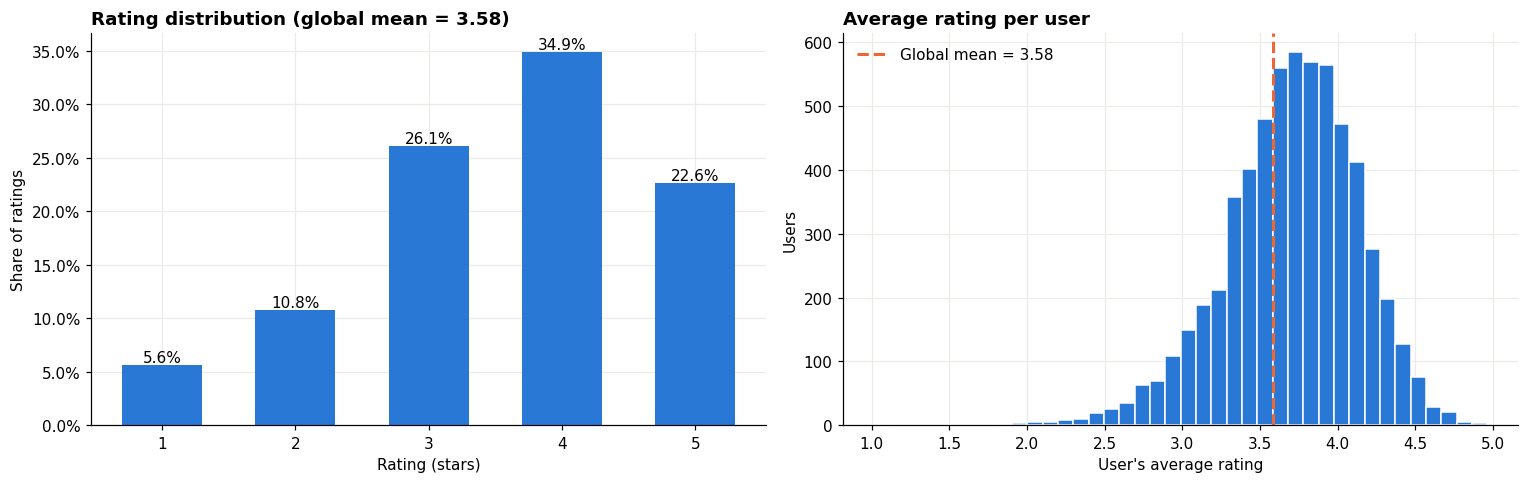

Share of ratings ≥ 4 stars: 57.5%
Share of ratings ≤ 2 stars: 16.4%

User average rating: p10 = 3.15 | median = 3.74 | p90 = 4.21
Users averaging ≥ 4.5 stars ('generous'): 100 | ≤ 3.0 stars ('strict'): 379
Users who always give the same rating (std = 0): 0


In [8]:
# ==============================
# 5.1.1 Rating distribution
# ==============================
global_mean = ratings["rating"].mean()
dist = ratings["rating"].value_counts(normalize=True).sort_index()

user_stats = ratings.groupby("user_id")["rating"].agg(n="size", mean="mean", std="std")
movie_stats = (ratings.groupby("movie_id")["rating"].agg(n="size", mean="mean", std="std")
               .join(movies.set_index("movie_id")[["title", "genres", "year"]]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(dist.index, dist.values, color=BLUE, width=0.6)
for x, v in zip(dist.index, dist.values):
    axes[0].text(x, v, f"{v:.1%}", ha="center", va="bottom", fontsize=10)
axes[0].set(title=f"Rating distribution (global mean = {global_mean:.2f})",
            xlabel="Rating (stars)", ylabel="Share of ratings")
pct_axis(axes[0])

# ==============================
# 5.1.2 User bias: average rating per user
# ==============================
axes[1].hist(user_stats["mean"], bins=40, color=BLUE, edgecolor="white")
axes[1].axvline(global_mean, color=ORANGE, ls="--", lw=2, label=f"Global mean = {global_mean:.2f}")
axes[1].set(title="Average rating per user", xlabel="User's average rating", ylabel="Users")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print(f"Share of ratings ≥ 4 stars: {(ratings['rating'] >= 4).mean():.1%}")
print(f"Share of ratings ≤ 2 stars: {(ratings['rating'] <= 2).mean():.1%}")
print(f"\nUser average rating: p10 = {user_stats['mean'].quantile(.1):.2f} | "
      f"median = {user_stats['mean'].median():.2f} | p90 = {user_stats['mean'].quantile(.9):.2f}")
print(f"Users averaging ≥ 4.5 stars ('generous'): {(user_stats['mean'] >= 4.5).sum():,} | "
      f"≤ 3.0 stars ('strict'): {(user_stats['mean'] <= 3.0).sum():,}")
print(f"Users who always give the same rating (std = 0): {(user_stats['std'] == 0).sum():,}")

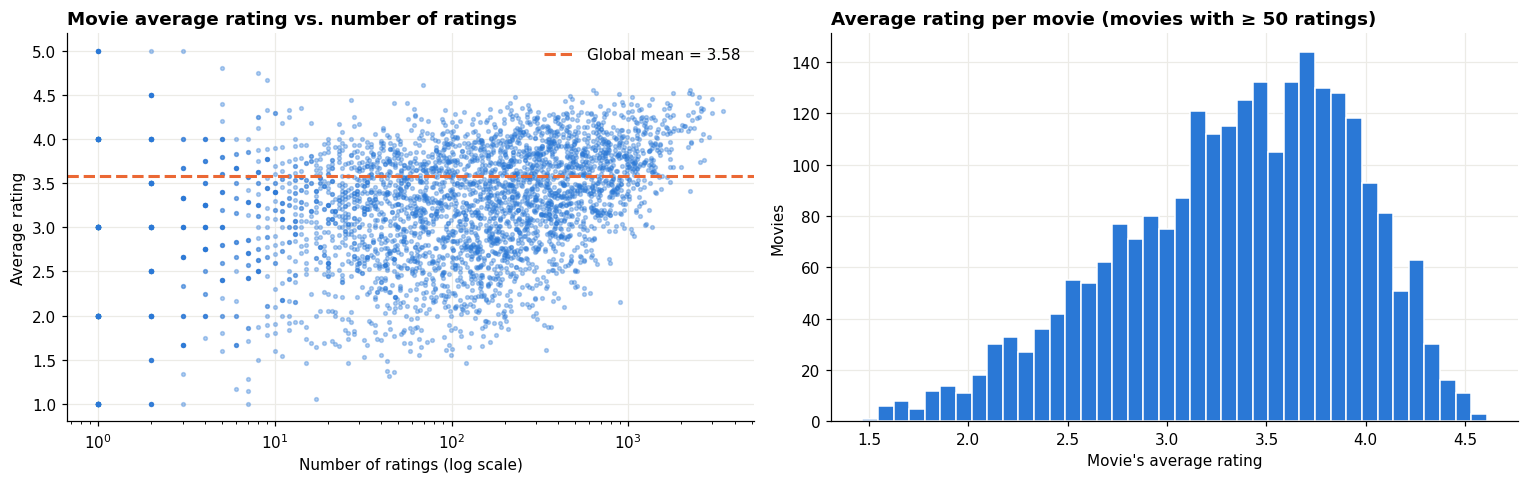

Top 10 movies by RAW average rating:


,title,genres,n,mean,bayes_mean
movie_id,,,,,
787,"Gate of Heavenly Peace, The (1995)",Documentary,3,5.00,3.62
989,Schlafes Bruder (Brother of Sleep) (1995),Drama,1,5.00,3.59
1830,Follow the Bitch (1998),Comedy,1,5.00,3.59
3172,Ulysses (Ulisse) (1954),Adventure,1,5.00,3.59
3233,Smashing Time (1967),Comedy,2,5.00,3.60
3280,"Baby, The (1973)",Horror,1,5.00,3.59
3382,Song of Freedom (1936),Drama,1,5.00,3.59
3607,One Little Indian (1973),Comedy|Drama|Western,1,5.00,3.59
3656,Lured (1947),Crime,1,5.00,3.59


Top 10 movies by BAYESIAN average rating (prior = 123 ratings at the global mean):


,title,genres,n,mean,bayes_mean
movie_id,,,,,
318,"Shawshank Redemption, The (1994)",Drama,"2,227",4.55,4.50
858,"Godfather, The (1972)",Action|Crime|Drama,"2,223",4.52,4.48
527,Schindler's List (1993),Drama|War,"2,304",4.51,4.46
50,"Usual Suspects, The (1995)",Crime|Thriller,"1,783",4.52,4.46
1198,Raiders of the Lost Ark (1981),Action|Adventure,"2,514",4.48,4.44
260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,"2,991",4.45,4.42
2019,Seven Samurai (The Magnificent Seven) (Shichinin no samurai) (1954),Action|Drama,628,4.56,4.40
1148,"Wrong Trousers, The (1993)",Animation|Comedy,882,4.51,4.39
904,Rear Window (1954),Mystery|Thriller,"1,050",4.48,4.38


,"RMSE (in-sample, descriptive)"
Global mean only,1.117
User mean,1.028
Movie mean,0.975
Global mean + user bias + movie bias,0.923


In [9]:
# ==============================
# 5.1.3 Item bias: average rating vs. number of ratings per movie
# ==============================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(movie_stats["n"], movie_stats["mean"], s=6, alpha=0.35, color=BLUE)
axes[0].axhline(global_mean, color=ORANGE, ls="--", lw=2, label=f"Global mean = {global_mean:.2f}")
axes[0].set_xscale("log")
axes[0].set(title="Movie average rating vs. number of ratings",
            xlabel="Number of ratings (log scale)", ylabel="Average rating")
axes[0].legend(frameon=False)

axes[1].hist(movie_stats.loc[movie_stats["n"] >= 50, "mean"], bins=40, color=BLUE, edgecolor="white")
axes[1].set(title="Average rating per movie (movies with ≥ 50 ratings)",
            xlabel="Movie's average rating", ylabel="Movies")

plt.tight_layout()
plt.show()

# ==============================
# 5.1.4 Raw average vs. Bayesian (shrunk) average
# ==============================
# Bayesian average: pulls movies with few ratings toward the global mean
M = int(movie_stats["n"].median())                    # prior strength = median number of ratings
movie_stats["bayes_mean"] = ((movie_stats["n"] * movie_stats["mean"] + M * global_mean)
                             / (movie_stats["n"] + M))

cols = ["title", "genres", "n", "mean", "bayes_mean"]
fmt = {"n": "{:,}", "mean": "{:.2f}", "bayes_mean": "{:.2f}"}
print(f"Top 10 movies by RAW average rating:")
display(movie_stats.nlargest(10, "mean")[cols].style.format(fmt))
print(f"Top 10 movies by BAYESIAN average rating (prior = {M} ratings at the global mean):")
display(movie_stats.nlargest(10, "bayes_mean")[cols].style.format(fmt))

# ==============================
# 5.1.5 How much of the rating is explained by simple biases?
# ==============================
r = ratings[["user_id", "movie_id", "rating"]].copy()
r["user_mean"] = r["user_id"].map(user_stats["mean"])
r["movie_mean"] = r["movie_id"].map(movie_stats["mean"])
r["user_movie_bias"] = global_mean + (r["user_mean"] - global_mean) + (r["movie_mean"] - global_mean)

rmse = lambda pred: np.sqrt(((r["rating"] - pred) ** 2).mean())
bias_table = pd.Series({
    "Global mean only": rmse(global_mean),
    "User mean": rmse(r["user_mean"]),
    "Movie mean": rmse(r["movie_mean"]),
    "Global mean + user bias + movie bias": rmse(r["user_movie_bias"].clip(1, 5)),
}, name="RMSE (in-sample, descriptive)")
display(bias_table.to_frame().style.format("{:.3f}"))

### 5.1 Ratings — Key Findings

**1. Ratings are skewed toward positive values**
| Rating | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Share | 5.6% | 10.8% | 26.1% | **34.9%** | 22.6% |

- Global mean: **3.58 stars**. **57.5%** of ratings are 4–5 stars, while only **16.4%** are 1–2 stars.
- Users mostly rate movies they **chose to watch**, and they choose movies they expect to like (**selection bias**). Unrated movies are therefore **not** the same as disliked movies: the data is *missing not at random*.

**2. Users have different rating scales (user bias)**
- Average rating per user: **p10 = 3.15, median = 3.74, p90 = 4.21**.
- **100 "generous" users** average ≥ 4.5 stars, and **379 "strict" users** average ≤ 3.0 stars. No user gives the same rating to every movie.
- The median user (3.74) rates **above the global mean (3.58)**: the most active users tend to be **stricter**, and since they contribute more ratings, they pull the global mean down.
- → A 4-star rating from a strict user means more than a 4 from a generous one, so ratings must be read **relative to each user's own scale**.

**3. Movies have different quality levels (item bias)**
- Among movies with ≥ 50 ratings, averages range from **\~1.5 to \~4.6**, with most between 3.0 and 4.0.
- **Popular movies tend to be rated higher:** in the scatter plot, the average rating grows with the number of ratings. Good movies attract more viewers, and more viewers lead to more ratings.
- Movies with **very few ratings** have extreme averages (from 1.0 to 5.0): with 1–3 ratings, the average is mostly noise.

**4. Raw averages are misleading → Bayesian average**
- The **top 10 by raw average** are all obscure movies with **1–3 ratings** of 5 stars (e.g., *Schlafes Bruder*, *Follow the Bitch*).
- The **Bayesian average** (prior of 123 ratings at the global mean) shrinks those movies toward 3.58 and surfaces well-known classics with thousands of ratings: *The Shawshank Redemption* (4.50), *The Godfather* (4.48), *Schindler's List* (4.46), *The Usual Suspects*, *Raiders of the Lost Ark*, *Star Wars*.
- → Any popularity or "top rated" ranking must account for the **number of ratings**, not only the average.

**5. Simple biases already explain a large part of the rating**
| Prediction | RMSE (in-sample) |
|---|---|
| Global mean only | 1.117 |
| User mean | 1.028 |
| Movie mean | 0.975 |
| **Global mean + user bias + movie bias** | **0.923** |

- Adding user and movie biases reduces RMSE by **\~17%** vs. the global mean, explaining **\~32% of the rating variance**.
- The movie effect is stronger than the user effect (0.975 vs. 1.028): **what** is rated matters more than **who** rates it.
- The remaining error is what **personal taste** (user × movie interaction) must explain: this is the job of collaborative filtering and supervised models.
- Note: these values are **descriptive** (computed on all data); the real evaluation will use a temporal train/test split.

**Implications for the recommender**
- **Baseline model:** "global mean + user bias + movie bias" is a strong and simple baseline that every model must beat.
- **Bias terms must be part of the models:** matrix factorization and supervised models should include (or be trained on top of) user and movie biases, so they learn **taste**, not rating scales.
- **Shrinkage is needed:** averages based on few ratings must be regularized (e.g., Bayesian averages, regularized biases) to avoid recommending obscure movies with one 5-star rating.
- **Selection bias matters for ranking:** since users rate what they choose to watch, a good recommender must predict not only *how much* a user will like a movie, but also *whether* they would choose to watch it.

### 5.2 Users

**Questions:**
- How many ratings does each user have? → How much history do we have to personalize?
- How concentrated is activity? Do a few heavy users generate most ratings?
- Do heavy users rate differently from light users?
- Do **gender**, **age** and **occupation** change how users rate? → Useful features for the supervised model and for cold start, and a check for **fairness** across segments.

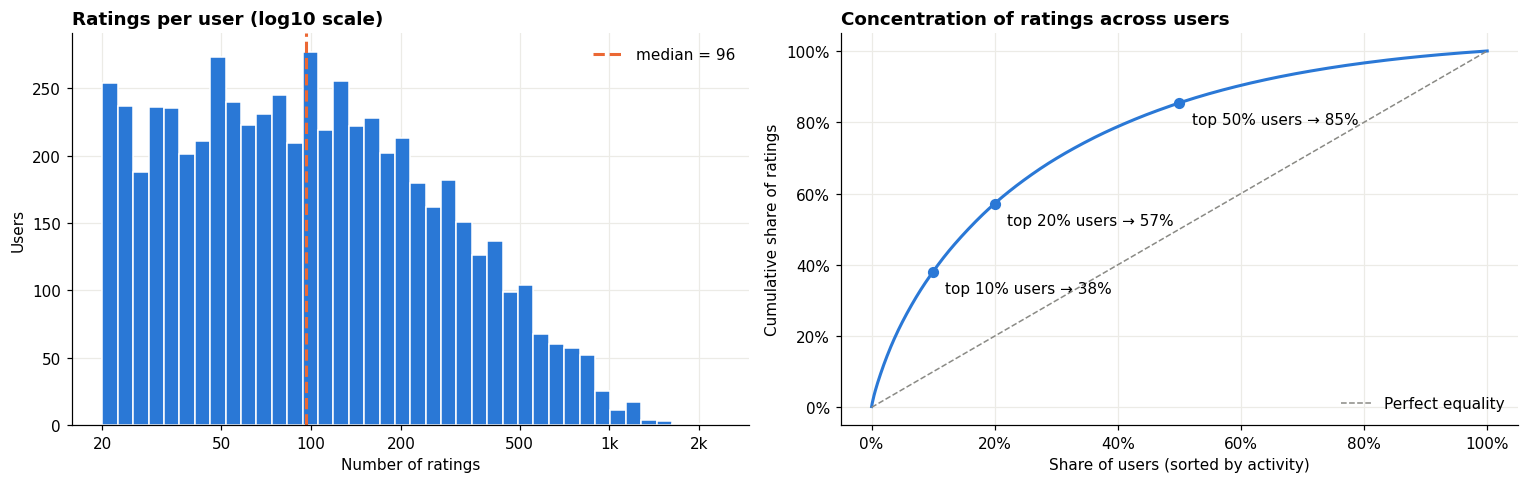

,count,mean,std,min,25%,50%,75%,90%,99%,max
ratings_per_user,"6,040.000",165.598,192.747,20.000,44.000,96.000,208.000,400.000,906.660,"2,314.000"


,users,share_users,share_ratings,avg_rating,avg_std
activity,,,,,
20–50,"1,793",29.7%,5.9%,3.77,1.03
51–100,"1,338",22.2%,9.7%,3.78,1.00
101–200,"1,331",22.0%,18.9%,3.72,0.99
201–500,"1,182",19.6%,36.6%,3.60,1.01
500+,396,6.6%,28.9%,3.39,1.03


In [10]:
# ==============================
# 5.2.1 Ratings per user (activity)
# ==============================
n_per_user = user_stats["n"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(np.log10(n_per_user), bins=40, color=BLUE, edgecolor="white")
axes[0].axvline(np.log10(n_per_user.median()), color=ORANGE, ls="--", lw=2,
                label=f"median = {n_per_user.median():.0f}")
axes[0].set(title="Ratings per user (log10 scale)", xlabel="Number of ratings", ylabel="Users")
axes[0].set_xticks(np.log10([20, 50, 100, 200, 500, 1000, 2000]))
axes[0].set_xticklabels(["20", "50", "100", "200", "500", "1k", "2k"])
axes[0].legend(frameon=False)

# Concentration: share of ratings generated by the most active users
sorted_n = np.sort(n_per_user.values)[::-1]
cum = np.cumsum(sorted_n) / sorted_n.sum()
share_users = np.arange(1, len(sorted_n) + 1) / len(sorted_n)
axes[1].plot(share_users, cum, color=BLUE, lw=2)
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Perfect equality")
for p in (0.10, 0.20, 0.50):
    v = cum[int(p * len(cum)) - 1]
    axes[1].scatter([p], [v], color=BLUE, s=40, zorder=3)
    axes[1].annotate(f"top {p:.0%} users → {v:.0%}", (p, v), xytext=(8, -14), textcoords="offset points")
axes[1].set(title="Concentration of ratings across users",
            xlabel="Share of users (sorted by activity)", ylabel="Cumulative share of ratings")
axes[1].legend(frameon=False, loc="lower right")
pct_axis(axes[1]); pct_axis(axes[1], "x")

plt.tight_layout()
plt.show()

display(n_per_user.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame("ratings_per_user").T)

# ==============================
# 5.2.2 Do heavy users rate differently?
# ==============================
activity_bins = [19, 50, 100, 200, 500, np.inf]
activity_labels = ["20–50", "51–100", "101–200", "201–500", "500+"]
user_stats["activity"] = pd.cut(user_stats["n"], bins=activity_bins, labels=activity_labels)

act = user_stats.groupby("activity", observed=True).agg(
    users=("n", "size"), ratings=("n", "sum"), avg_rating=("mean", "mean"), avg_std=("std", "mean"))
act["share_users"] = act["users"] / act["users"].sum()
act["share_ratings"] = act["ratings"] / act["ratings"].sum()
display(act[["users", "share_users", "share_ratings", "avg_rating", "avg_std"]]
        .style.format({"users": "{:,}", "share_users": "{:.1%}", "share_ratings": "{:.1%}",
                       "avg_rating": "{:.2f}", "avg_std": "{:.2f}"}))

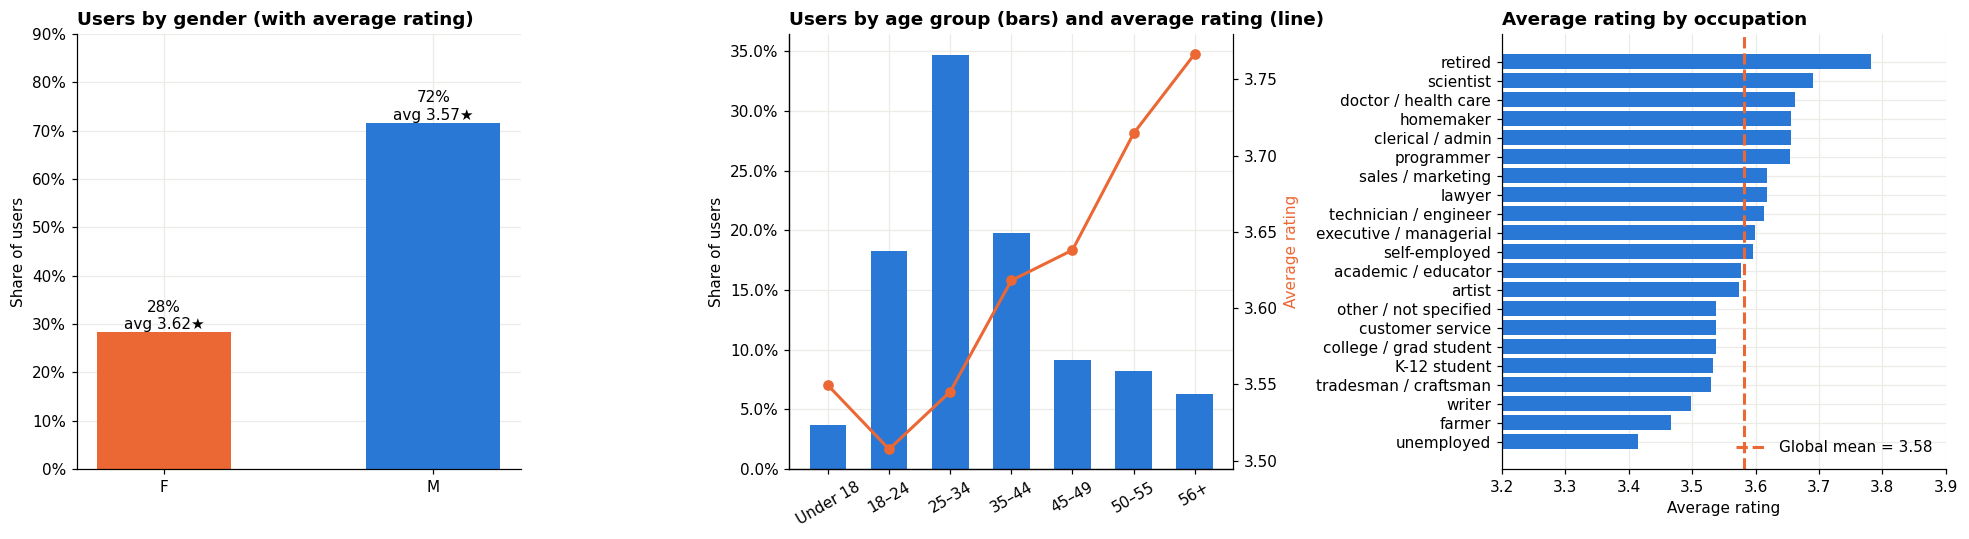

,spread_of_avg_rating (stars)
gender,0.05
age_group,0.26
occupation,0.37
individual users (p10–p90),1.07


In [11]:
# ==============================
# 5.2.3 Demographics: who are the users and how do they rate?
# ==============================
ud = users.set_index("user_id").join(user_stats[["n", "mean"]])
rd = ratings.merge(users[["user_id", "gender", "age_group", "occupation_name"]], on="user_id")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gender
g = rd.groupby("gender")["rating"].agg(["size", "mean"])
g["share_users"] = ud["gender"].value_counts(normalize=True)
axes[0].bar(g.index, g["share_users"], color=[ORANGE, BLUE], width=0.5)
for i, (s, m) in enumerate(zip(g["share_users"], g["mean"])):
    axes[0].text(i, s, f"{s:.0%}\navg {m:.2f}★", ha="center", va="bottom", fontsize=10)
axes[0].set(title="Users by gender (with average rating)", ylabel="Share of users")
axes[0].set_ylim(0, 0.9)
pct_axis(axes[0])

# Age group
a = rd.groupby("age_group", observed=True)["rating"].mean()
a_users = ud["age_group"].value_counts(normalize=True).reindex(a.index)
axes[1].bar(a.index.astype(str), a_users.values, color=BLUE, width=0.6)
ax2 = axes[1].twinx()
ax2.plot(a.index.astype(str), a.values, color=ORANGE, marker="o", lw=2)
ax2.set_ylabel("Average rating", color=ORANGE)
ax2.spines["right"].set_visible(True); ax2.grid(False)
axes[1].set(title="Users by age group (bars) and average rating (line)", ylabel="Share of users")
axes[1].tick_params(axis="x", rotation=30)
pct_axis(axes[1])

# Occupation
o = rd.groupby("occupation_name")["rating"].agg(["size", "mean"]).sort_values("mean")
axes[2].barh(o.index, o["mean"], color=BLUE)
axes[2].axvline(global_mean, color=ORANGE, ls="--", lw=2, label=f"Global mean = {global_mean:.2f}")
axes[2].set(title="Average rating by occupation", xlabel="Average rating")
axes[2].set_xlim(3.2, 3.9)
axes[2].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

# How much do demographics explain? Spread of average rating across groups
spread = pd.Series({
    "gender": rd.groupby("gender")["rating"].mean().agg(lambda s: s.max() - s.min()),
    "age_group": rd.groupby("age_group", observed=True)["rating"].mean().agg(lambda s: s.max() - s.min()),
    "occupation": rd.groupby("occupation_name")["rating"].mean().agg(lambda s: s.max() - s.min()),
    "individual users (p10–p90)": user_stats["mean"].quantile(.9) - user_stats["mean"].quantile(.1),
}, name="spread_of_avg_rating (stars)")
display(spread.to_frame().style.format("{:.2f}"))

### 5.2 Users — Key Findings

**1. Users have a lot of history, but very unevenly**
- **6,040 users**, with a **median of 96 ratings** (mean 166 → right-skewed). The minimum is 20 (dataset guarantee) and the maximum is **2,314**.
- 25% of users have ≤ 44 ratings, while the top 1% have more than \~900.
- Compared with Instacart (median of 10 orders), **every user has enough history to personalize**: there is no real user cold start in this dataset.

**2. A minority of heavy users generates most ratings**
- The **top 10%** of users generate **38%** of all ratings, the **top 20%** generate **57%**, and the **top 50%** generate **85%**.

| Activity (ratings) | Users | Share of users | Share of ratings | Avg. rating | Avg. std |
|---|---|---|---|---|---|
| 20–50 | 1,793 | 29.7% | 5.9% | 3.77 | 1.03 |
| 51–100 | 1,338 | 22.2% | 9.7% | 3.78 | 1.00 |
| 101–200 | 1,331 | 22.0% | 18.9% | 3.72 | 0.99 |
| 201–500 | 1,182 | 19.6% | 36.6% | 3.60 | 1.01 |
| **500+** | **396** | **6.6%** | **28.9%** | **3.39** | 1.03 |

- → If all ratings are weighted equally, models will mostly learn the tastes of **heavy users**, who are a small part of the user base.

**3. Heavy users are stricter**
- The average rating drops from **3.77–3.78** for light users to **3.39** for users with 500+ ratings.
- Heavy users rate a wider range of movies (not only the ones they expected to like), so their ratings are less affected by **selection bias**.
- This explains why the median user (3.74) rates above the global mean (3.58): heavy users contribute many ratings and pull the global mean down.
- The **spread of ratings within a user** is similar across segments (std ≈ 1.0): users use the full scale regardless of activity.

**4. Demographics have a small effect on ratings**
- **Gender:** 72% male / 28% female, with almost identical average ratings (**3.57 vs. 3.62**).
- **Age:** the largest group is **25–34 (\~35% of users)**. The average rating grows with age, from **3.51 (18–24)** to **3.77 (56+)**.
- **Occupation:** from **3.41 (unemployed)** to **3.78 (retired)**; scientists, doctors and homemakers rate above average, while writers, farmers and the unemployed rate below.

**5. Individual differences matter much more than demographics**
| Source of variation | Spread of average rating |
|---|---|
| Gender | 0.05 stars |
| Age group | 0.26 stars |
| Occupation | 0.37 stars |
| **Individual users (p10–p90)** | **1.07 stars** |

- Differences between individual users are **3–20× larger** than differences between demographic groups (and the comparison favors groups, since it uses their full range vs. the p10–p90 range for users).
- → **Demographics are a weak signal** for predicting how a user rates. A user's **own history** is far more informative.

**Implications for the recommender**
- **Personal biases are essential:** each user needs their own bias term; demographic groups cannot replace it.
- **Demographics are useful mainly for cold start:** for a brand-new user (no ratings), age and occupation can provide a first guess, but their value drops quickly once the user has a few ratings.
- **Heavy users dominate the training data:** evaluation should be reported **by activity segment**, so that results are not driven only by heavy users.
- **Fairness check:** recommendation quality should be compared across **gender and age groups**, given the 72/28 gender imbalance.

### 5.3 Movies

**Questions:**
- How concentrated is attention? Do a few blockbusters receive most ratings (**popularity bias**)?
- How many movies have too few ratings to learn from (**item cold start**)?
- Which **genres** are most common and most watched? Are some genres rated higher than others?
- Does the **release year** affect how much a movie is watched and how it is rated?

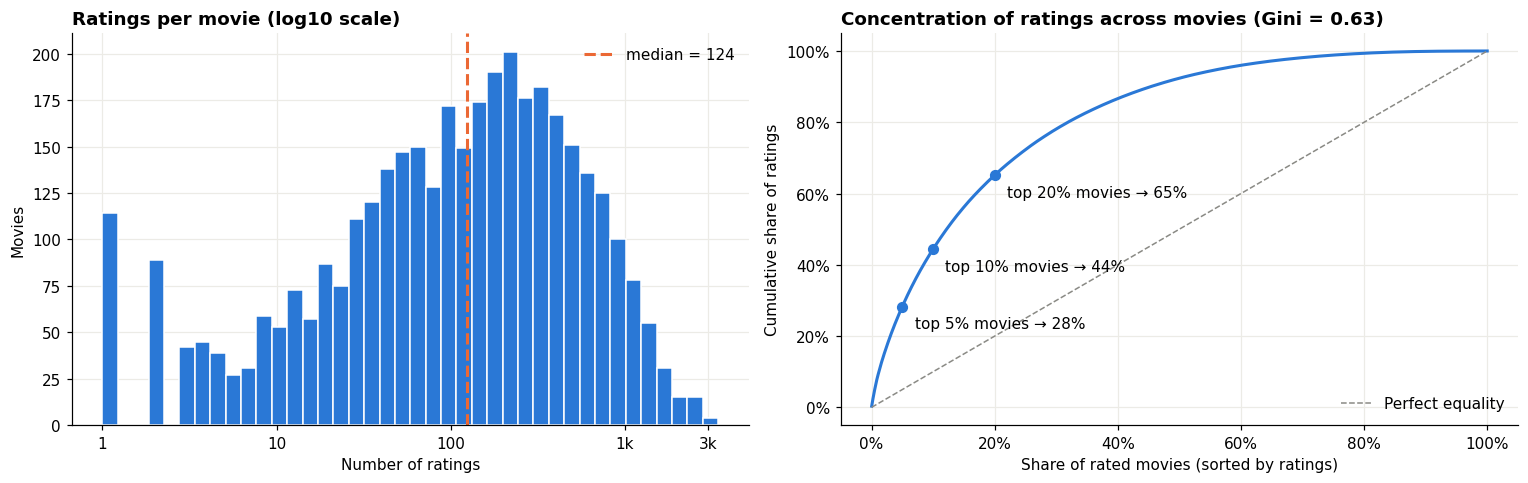

,count,mean,std,min,25%,50%,75%,90%,99%,max
ratings_per_movie,"3,706.000",269.889,384.048,1.000,33.000,123.500,350.000,729.500,"1,784.900","3,428.000"


Top 10 most rated movies:


,title,genres,n,mean,bayes_mean
movie_id,,,,,
2858,American Beauty (1999),Comedy|Drama,"3,428",4.32,4.29
260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,"2,991",4.45,4.42
1196,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Drama|Sci-Fi|War,"2,990",4.29,4.26
1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,"2,883",4.02,4.00
480,Jurassic Park (1993),Action|Adventure|Sci-Fi,"2,672",3.76,3.76
2028,Saving Private Ryan (1998),Action|Drama|War,"2,653",4.34,4.30
589,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,"2,649",4.06,4.04
2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,"2,590",4.32,4.28
1270,Back to the Future (1985),Comedy|Sci-Fi,"2,583",3.99,3.97


Rated movies with <  10 ratings: 446 (12.0%)
Rated movies with <  20 ratings: 663 (17.9%)
Rated movies with <  50 ratings: 1,192 (32.2%)
Rated movies with < 100 ratings: 1,687 (45.5%)


In [12]:
# ==============================
# 5.3.1 Ratings per movie and concentration (long tail)
# ==============================
n_per_movie = movie_stats["n"].sort_values(ascending=False)
cum_m = np.cumsum(n_per_movie.values) / n_per_movie.sum()
share_m = np.arange(1, len(n_per_movie) + 1) / len(n_per_movie)

asc = np.sort(n_per_movie.values)
gini_movies = 1 - 2 * (np.cumsum(asc) / asc.sum()).mean() + 1 / len(asc)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(np.log10(n_per_movie), bins=40, color=BLUE, edgecolor="white")
axes[0].axvline(np.log10(n_per_movie.median()), color=ORANGE, ls="--", lw=2,
                label=f"median = {n_per_movie.median():.0f}")
axes[0].set(title="Ratings per movie (log10 scale)", xlabel="Number of ratings", ylabel="Movies")
axes[0].set_xticks(np.log10([1, 10, 100, 1000, 3000]))
axes[0].set_xticklabels(["1", "10", "100", "1k", "3k"])
axes[0].legend(frameon=False)

axes[1].plot(share_m, cum_m, color=BLUE, lw=2)
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Perfect equality")
for p in (0.05, 0.10, 0.20):
    v = cum_m[int(p * len(cum_m)) - 1]
    axes[1].scatter([p], [v], color=BLUE, s=40, zorder=3)
    axes[1].annotate(f"top {p:.0%} movies → {v:.0%}", (p, v), xytext=(8, -14), textcoords="offset points")
axes[1].set(title=f"Concentration of ratings across movies (Gini = {gini_movies:.2f})",
            xlabel="Share of rated movies (sorted by ratings)", ylabel="Cumulative share of ratings")
axes[1].legend(frameon=False, loc="lower right")
pct_axis(axes[1]); pct_axis(axes[1], "x")

plt.tight_layout()
plt.show()

display(n_per_movie.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame("ratings_per_movie").T)

print("Top 10 most rated movies:")
display(movie_stats.nlargest(10, "n")[["title", "genres", "n", "mean", "bayes_mean"]]
        .style.format({"n": "{:,}", "mean": "{:.2f}", "bayes_mean": "{:.2f}"}))

for t in (10, 20, 50, 100):
    k = (n_per_movie < t).sum()
    print(f"Rated movies with < {t:>3} ratings: {k:,} ({k / len(n_per_movie):.1%})")

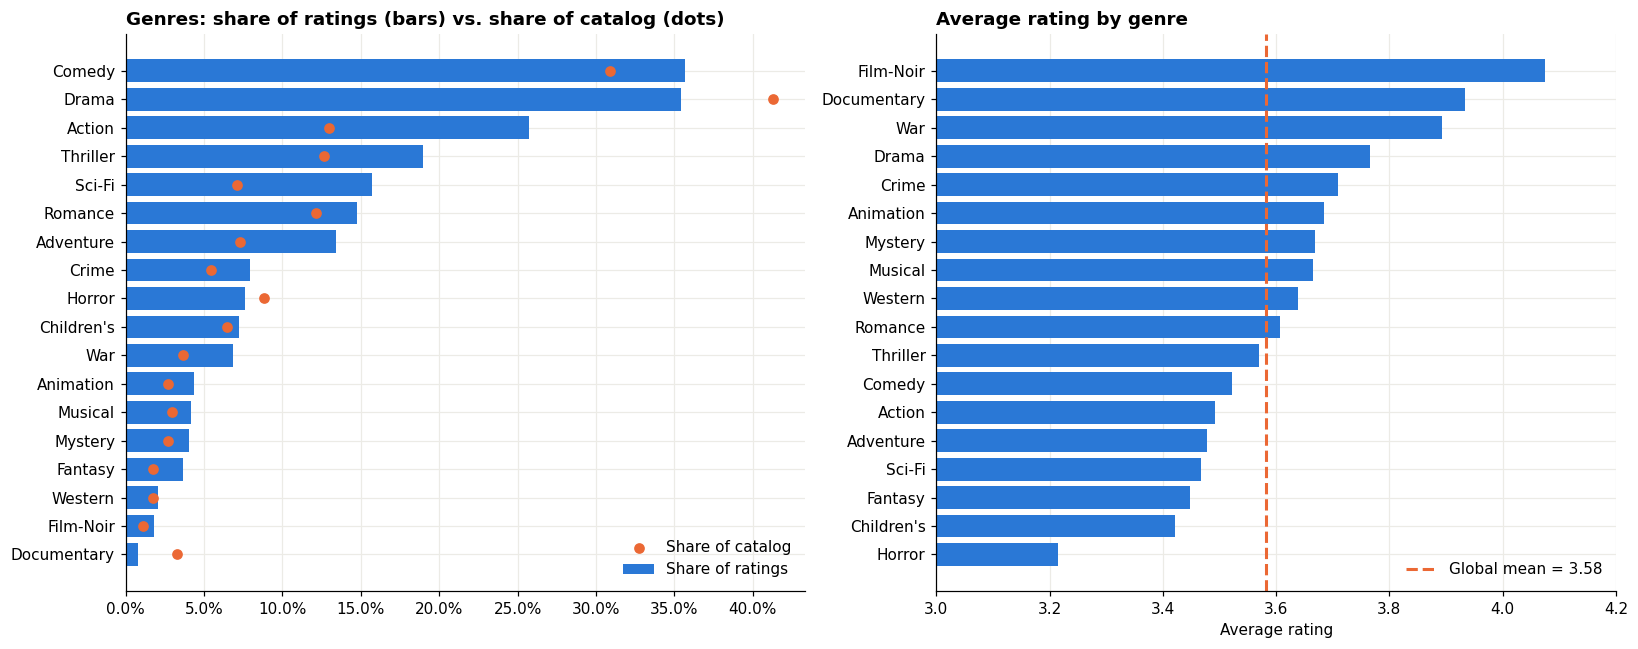

,movies_in_catalog,share_of_catalog,share_of_ratings,ratings_per_movie,avg_rating
Comedy,"1,200",30.9%,35.7%,297,3.52
Drama,"1,603",41.3%,35.4%,221,3.77
Action,503,13.0%,25.7%,512,3.49
Thriller,492,12.7%,19.0%,386,3.57
Sci-Fi,276,7.1%,15.7%,570,3.47
Romance,471,12.1%,14.7%,313,3.61
Adventure,283,7.3%,13.4%,473,3.48
Crime,211,5.4%,8.0%,377,3.71
Horror,343,8.8%,7.6%,223,3.22
Children's,251,6.5%,7.2%,288,3.42


Note: shares add up to more than 100% because a movie can have several genres.


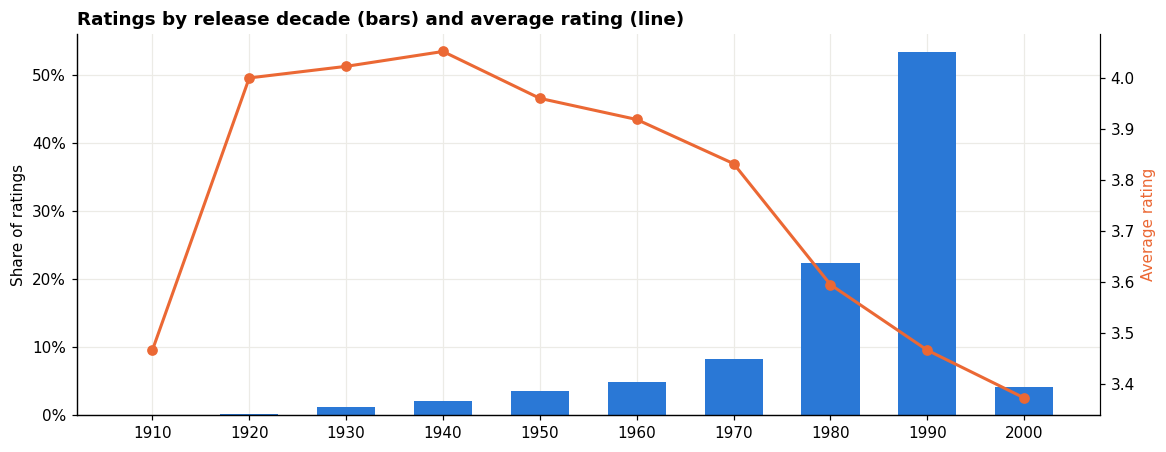

,movies_in_catalog,ratings,avg_rating,share_of_ratings,ratings_per_movie
decade,,,,,
1910,3,45,3.47,0.0%,15
1920,34,"1,696",4.00,0.2%,50
1930,77,"12,729",4.02,1.3%,165
1940,126,"21,501",4.05,2.1%,171
1950,168,"35,232",3.96,3.5%,210
1960,191,"48,555",3.92,4.9%,254
1970,247,"82,552",3.83,8.3%,334
1980,598,"224,056",3.59,22.4%,375
1990,"2,283","532,843",3.47,53.3%,233


In [13]:
# ==============================
# 5.3.2 Genres: catalog share, attention and average rating
# ==============================
g_cols = [f"g_{g}" for g in GENRES]
rg = ratings[["movie_id", "rating"]].merge(movies[["movie_id"] + g_cols], on="movie_id")

genre_tbl = pd.DataFrame({
    "movies_in_catalog": movies[g_cols].sum().values,
    "share_of_ratings": rg[g_cols].mean().values,                 # share of ratings involving the genre
    "avg_rating": [rg.loc[rg[c] == 1, "rating"].mean() for c in g_cols],
}, index=GENRES)
genre_tbl["share_of_catalog"] = genre_tbl["movies_in_catalog"] / len(movies)
genre_tbl["ratings_per_movie"] = (genre_tbl["share_of_ratings"] * len(ratings)) / genre_tbl["movies_in_catalog"]
genre_tbl = genre_tbl.sort_values("share_of_ratings", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(genre_tbl.index[::-1], genre_tbl["share_of_ratings"][::-1], color=BLUE, label="Share of ratings")
axes[0].scatter(genre_tbl["share_of_catalog"][::-1], genre_tbl.index[::-1], color=ORANGE, zorder=3,
                label="Share of catalog")
axes[0].set(title="Genres: share of ratings (bars) vs. share of catalog (dots)")
axes[0].legend(frameon=False, loc="lower right")
pct_axis(axes[0], "x")

gr = genre_tbl.sort_values("avg_rating")
axes[1].barh(gr.index, gr["avg_rating"], color=BLUE)
axes[1].axvline(global_mean, color=ORANGE, ls="--", lw=2, label=f"Global mean = {global_mean:.2f}")
axes[1].set(title="Average rating by genre", xlabel="Average rating")
axes[1].set_xlim(3.0, 4.2)
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

display(genre_tbl[["movies_in_catalog", "share_of_catalog", "share_of_ratings", "ratings_per_movie", "avg_rating"]]
        .style.format({"movies_in_catalog": "{:,}", "share_of_catalog": "{:.1%}", "share_of_ratings": "{:.1%}",
                       "ratings_per_movie": "{:,.0f}", "avg_rating": "{:.2f}"}))
print("Note: shares add up to more than 100% because a movie can have several genres.")

# ==============================
# 5.3.3 Release year (by decade)
# ==============================
movies["decade"] = (movies["year"] // 10 * 10).astype("Int16")
ry = ratings[["movie_id", "rating"]].merge(movies[["movie_id", "decade"]], on="movie_id")

decade_tbl = pd.DataFrame({
    "movies_in_catalog": movies.groupby("decade").size(),
    "ratings": ry.groupby("decade").size(),
    "avg_rating": ry.groupby("decade")["rating"].mean(),
})
decade_tbl["share_of_ratings"] = decade_tbl["ratings"] / decade_tbl["ratings"].sum()
decade_tbl["ratings_per_movie"] = decade_tbl["ratings"] / decade_tbl["movies_in_catalog"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(decade_tbl.index.astype(str), decade_tbl["share_of_ratings"], color=BLUE, width=0.6)
ax.set(title="Ratings by release decade (bars) and average rating (line)", ylabel="Share of ratings")
pct_axis(ax)
ax2 = ax.twinx()
ax2.plot(decade_tbl.index.astype(str), decade_tbl["avg_rating"], color=ORANGE, marker="o", lw=2)
ax2.set_ylabel("Average rating", color=ORANGE)
ax2.spines["right"].set_visible(True); ax2.grid(False)
plt.show()

display(decade_tbl.style.format({"movies_in_catalog": "{:,}", "ratings": "{:,}", "avg_rating": "{:.2f}",
                                 "share_of_ratings": "{:.1%}", "ratings_per_movie": "{:,.0f}"}))

### 5.3 Movies — Key Findings

**1. Attention is concentrated, but less than in grocery retail**
- **3,706 rated movies**, with a **median of 124 ratings** (mean 270, max 3,428 → right-skewed).
- The **top 5%** of movies receive **28%** of ratings, the **top 10%** receive **44%**, and the **top 20%** receive **65%**.
- **Gini = 0.63**, lower than in Instacart (0.87): there is a clear **popularity bias**, but the catalog is more evenly consumed than a grocery catalog.
- The most rated movies are late-20th-century **blockbusters**, mostly Action / Sci-Fi: *American Beauty* (3,428 ratings), the three original *Star Wars*, *Jurassic Park*, *Saving Private Ryan*, *Terminator 2*, *The Matrix*, *Back to the Future*, *The Silence of the Lambs*. All of them are rated **above the global mean** (3.76–4.45).

**2. A large part of the catalog has little data (item cold start)**
| Ratings per movie | Movies | Share of rated movies |
|---|---|---|
| < 10 | 446 | 12.0% |
| < 20 | 663 | 17.9% |
| < 50 | 1,192 | 32.2% |
| < 100 | 1,687 | 45.5% |

- About **1 in 3 movies has fewer than 50 ratings**, and \~114 movies have a **single rating**. Together with the 177 movies with no ratings, a significant part of the catalog has too little interaction data for collaborative filtering alone.

**3. The most watched genres are not the best rated**
| Genre | Share of catalog | Share of ratings | Ratings per movie | Avg. rating |
|---|---|---|---|---|
| Comedy | 30.9% | 35.7% | 297 | 3.52 |
| Drama | 41.3% | 35.4% | 221 | 3.77 |
| **Action** | 13.0% | **25.7%** | 512 | 3.49 |
| **Sci-Fi** | 7.1% | **15.7%** | **570** | 3.47 |
| Horror | 8.8% | 7.6% | 223 | **3.22** (lowest) |
| War | 3.7% | 6.9% | 479 | 3.89 |
| Film-Noir | 1.1% | 1.8% | 415 | **4.08** (highest) |
| Documentary | 3.3% | 0.8% | **62** | 3.93 |

- **Action, Sci-Fi, Adventure and Fantasy** receive about **2× more attention** than their share of the catalog (470–570 ratings per movie), but are rated **below the global mean** (3.45–3.49).
- **Drama** is the largest genre in the catalog (41%) but receives proportionally less attention (221 ratings per movie), while being rated above average (3.77).
- **Niche genres** such as Film-Noir, Documentary and War get the **highest ratings** (3.89–4.08): they are watched mainly by people who already enjoy them (**self-selection**).
- **Documentaries** are the least watched genre per movie (62 ratings), and **Horror** is the lowest rated (3.22).
- The average rating varies by **\~0.9 stars across genres** (3.22–4.08), much more than across demographic groups (≤ 0.37).

**4. Older movies are rated higher (survivorship bias)**
| Decade | Movies | Share of ratings | Avg. rating |
|---|---|---|---|
| 1930s–1940s | 203 | 3.4% | 4.02–4.05 |
| 1950s–1970s | 606 | 16.7% | 3.83–3.96 |
| 1980s | 598 | 22.4% | 3.59 |
| **1990s** | **2,283** | **53.3%** | 3.47 |
| 2000 | 156 | 4.1% | 3.37 |

- The catalog and the attention are dominated by **recent movies**: the **1990s** account for **59% of the catalog** and **53% of ratings**; together with the 1980s, **\~76% of ratings**.
- The average rating **declines steadily** from **4.05 (1940s)** to **3.47 (1990s)** and **3.37 (2000)**.
- This does not mean older movies are better: only the **classics** from earlier decades are still in the catalog and being watched, while recent decades include every kind of release (**survivorship bias**). Users who choose to watch old movies are also likely to be film enthusiasts.

**Implications for the recommender**
- **Popularity bias:** a model trained on these ratings will tend to recommend Action / Sci-Fi blockbusters from the 1980s–1990s. **Catalog coverage** and **novelty** must be measured alongside accuracy.
- **Item cold start:** \~1 in 3 movies has fewer than 50 ratings, so their biases and latent factors must be **regularized**, and **content features** (genres, release decade) are needed to recommend them.
- **Genres and release year are useful features** for the supervised model: they shift the expected rating by up to \~0.9 and \~0.7 stars, respectively.
- **Popular ≠ best rated:** recommending only what is most watched is not the same as recommending what users will like most. A good recommender needs to balance **"will they watch it?"** with **"will they like it?"**.
- **Self-selection by genre:** niche genres are rated high because only their fans watch them. Recommending them to everyone would **not** reproduce those ratings, so models must learn **which users** like each genre (user × genre interaction).

### 5.4 Time: How Is Activity Distributed?

**Questions:**
- How are ratings distributed over the 34 months of data? Is activity stable or concentrated in some periods?
- How do users rate over their **lifetime** on the platform: continuously, or in a few intense sessions?
- Do ratings change as users become more experienced?
- **How should we split the data into train and test?** A global time cutoff or a per-user split?

**Why it matters:** a realistic evaluation must use **the past to predict the future**. A random split lets models "see the future" and inflates results.

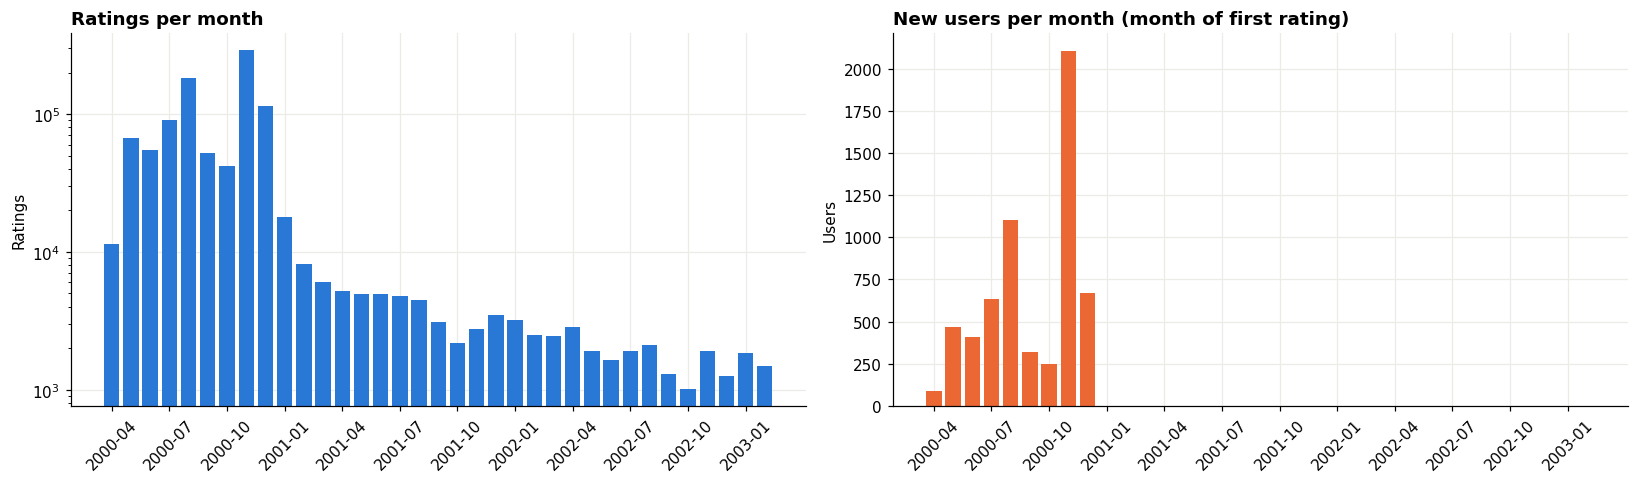

Share of ratings by year: {2000: '90.5%', 2001: '6.8%', 2002: '2.4%', 2003: '0.3%'}


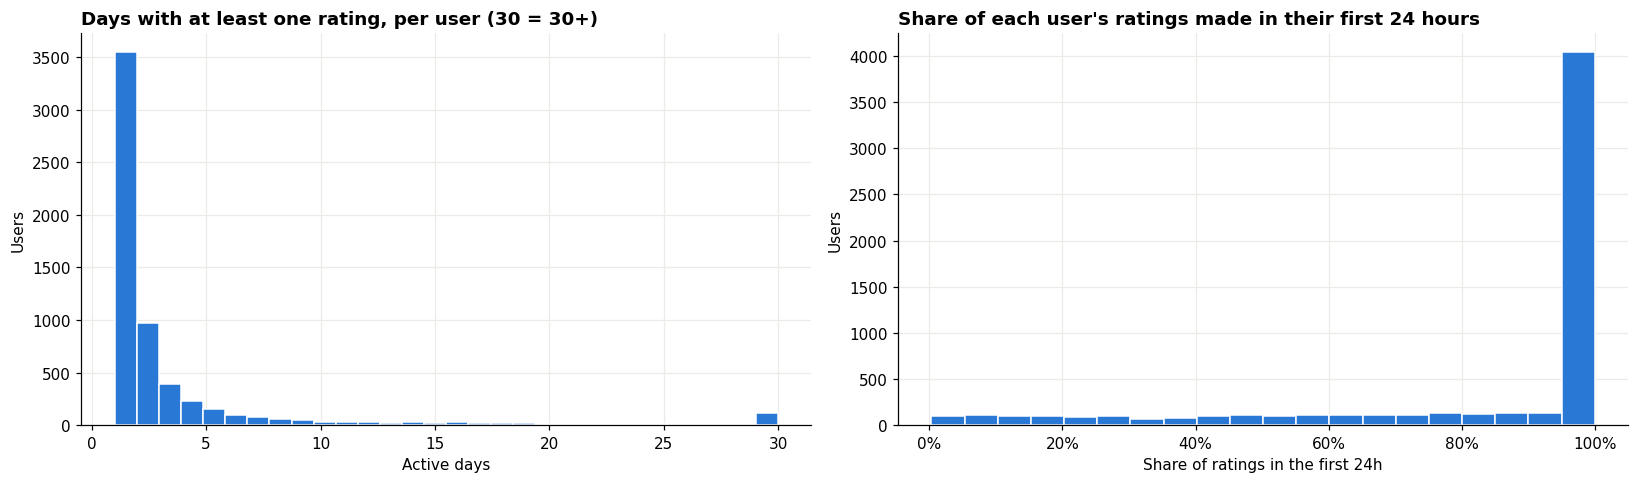

Median lifetime (first → last rating): 0.0 days
Users whose ratings all happened within 1 day: 62.9%
Median active days per user: 1
Share of ALL ratings made in the user's first 24 hours: 72.4%
Ratings sharing their exact timestamp with another rating of the same user: 77.4%


In [14]:
# ==============================
# 5.4.1 Activity over time
# ==============================
ratings["month"] = ratings["datetime"].dt.to_period("M")
monthly = ratings.groupby("month").agg(ratings=("rating", "size"), avg_rating=("rating", "mean"))
first_month = ratings.groupby("user_id")["month"].min()
monthly["new_users"] = first_month.value_counts().reindex(monthly.index, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

x = monthly.index.astype(str)
axes[0].bar(x, monthly["ratings"], color=BLUE, width=0.8)
axes[0].set(title="Ratings per month", ylabel="Ratings")
axes[0].set_xticks(range(0, len(x), 3)); axes[0].set_xticklabels(x[::3], rotation=45)
axes[0].set_yscale("log")

axes[1].bar(x, monthly["new_users"], color=ORANGE, width=0.8)
axes[1].set(title="New users per month (month of first rating)", ylabel="Users")
axes[1].set_xticks(range(0, len(x), 3)); axes[1].set_xticklabels(x[::3], rotation=45)

plt.tight_layout()
plt.show()

year_share = ratings["datetime"].dt.year.value_counts(normalize=True).sort_index()
print("Share of ratings by year:", {int(k): f"{v:.1%}" for k, v in year_share.items()})

# ==============================
# 5.4.2 User lifetime: continuous use or a few intense sessions?
# ==============================
ratings["date"] = ratings["datetime"].dt.normalize()
life = ratings.groupby("user_id").agg(first=("datetime", "min"), last=("datetime", "max"),
                                      n=("rating", "size"), active_days=("date", "nunique"))
life["lifetime_days"] = (life["last"] - life["first"]).dt.total_seconds() / 86400

first_day = ratings.merge(life[["first"]], left_on="user_id", right_index=True)
first_day = (first_day["datetime"] - first_day["first"]).dt.total_seconds() < 86400
share_first_day = first_day.groupby(ratings["user_id"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(life["active_days"].clip(upper=30), bins=30, color=BLUE, edgecolor="white")
axes[0].set(title="Days with at least one rating, per user (30 = 30+)", xlabel="Active days", ylabel="Users")

axes[1].hist(share_first_day, bins=20, color=BLUE, edgecolor="white")
axes[1].set(title="Share of each user's ratings made in their first 24 hours",
            xlabel="Share of ratings in the first 24h", ylabel="Users")
pct_axis(axes[1], "x")
plt.tight_layout()
plt.show()

print(f"Median lifetime (first → last rating): {life['lifetime_days'].median():.1f} days")
print(f"Users whose ratings all happened within 1 day: {(life['lifetime_days'] < 1).mean():.1%}")
print(f"Median active days per user: {life['active_days'].median():.0f}")
print(f"Share of ALL ratings made in the user's first 24 hours: {first_day.mean():.1%}")

# Ratings with the exact same timestamp for the same user (batch rating)
ties = ratings.duplicated(["user_id", "timestamp"], keep=False).mean()
print(f"Ratings sharing their exact timestamp with another rating of the same user: {ties:.1%}")

In [15]:
# ==============================
# 5.4.3 Do ratings change as users rate more movies?
# ==============================
ratings = ratings.sort_values(["user_id", "timestamp", "movie_id"]).reset_index(drop=True)
ratings["rating_seq"] = ratings.groupby("user_id").cumcount() + 1          # 1st, 2nd, ... rating of the user

seq = ratings[ratings["rating_seq"] <= 500].copy()
seq["seq_bin"] = pd.cut(seq["rating_seq"], bins=[0, 10, 20, 50, 100, 200, 500],
                        labels=["1–10", "11–20", "21–50", "51–100", "101–200", "201–500"])
seq_tbl = seq.merge(movie_stats[["n"]], left_on="movie_id", right_index=True) \
             .groupby("seq_bin", observed=True).agg(avg_rating=("rating", "mean"),
                                                    avg_movie_popularity=("n", "median"))
display(seq_tbl.style.format({"avg_rating": "{:.2f}", "avg_movie_popularity": "{:,.0f}"}))

# ==============================
# 5.4.4 Train/test split options
# ==============================
# Option A — global time cutoff: last 10% of ratings (in time) as test
cutoff = ratings["timestamp"].quantile(0.90)
test_a = ratings[ratings["timestamp"] > cutoff]
train_a_users = set(ratings.loc[ratings["timestamp"] <= cutoff, "user_id"])
users_test_a = test_a["user_id"].unique()

# Option B — per-user temporal split: each user's last 20% of ratings as test
ratings["n_user"] = ratings.groupby("user_id")["rating"].transform("size")
test_b = ratings[ratings["rating_seq"] > (ratings["n_user"] * 0.8).round()]

split_cmp = pd.DataFrame({
    "test_ratings": [len(test_a), len(test_b)],
    "users_in_test": [len(users_test_a), test_b["user_id"].nunique()],
    "share_of_users_evaluated": [len(users_test_a) / ratings["user_id"].nunique(),
                                 test_b["user_id"].nunique() / ratings["user_id"].nunique()],
    "test_users_unseen_in_train": [np.mean([u not in train_a_users for u in users_test_a]), 0.0],
}, index=["A: global cutoff (last 10% in time)", "B: per user (last 20% of each user)"])
display(split_cmp.style.format({"test_ratings": "{:,}", "users_in_test": "{:,}",
                                "share_of_users_evaluated": "{:.1%}", "test_users_unseen_in_train": "{:.1%}"}))
print(f"Global cutoff date for option A: {pd.to_datetime(cutoff, unit='s'):%Y-%m-%d}")

,avg_rating,avg_movie_popularity
seq_bin,,
1–10,3.68,913
11–20,3.86,928
21–50,3.79,838
51–100,3.70,742
101–200,3.57,638
201–500,3.42,510


,test_ratings,users_in_test,share_of_users_evaluated,test_users_unseen_in_train
A: global cutoff (last 10% in time),"100,021","1,209",20.0%,2.4%
B: per user (last 20% of each user),"200,016","6,040",100.0%,0.0%


Global cutoff date for option A: 2000-12-29


### 5.4 Time — Key Findings

**1. Almost all activity happened in 2000**
| Year | 2000 | 2001 | 2002 | 2003 |
|---|---|---|---|---|
| Share of ratings | **90.5%** | 6.8% | 2.4% | 0.3% |

- **All 6,040 users joined between April and December 2000** (peaks in July and, above all, **November 2000** with \~2,100 new users). **No new users joined after 2000.**
- From 2001 on, activity drops to a few thousand ratings per month: only a minority of users kept coming back.

**2. Users rate in bulk, not as they watch**
- **Median user lifetime (first → last rating): 0 days**; median active days per user: **1**.
- **62.9%** of users made **all** their ratings within a single day, and **72.4% of all ratings** were made during the user's **first 24 hours**.
- **77.4%** of ratings share their **exact timestamp** (to the second) with another rating of the same user.
- → Ratings are mostly produced in **bulk sessions** where users rate movies they **watched in the past**, not as a record of what they watch over time. In practice, MovieLens works as a **taste profile** that users fill in when they sign up.

**3. Users start with popular movies and move toward niche ones**
| User's rating number | 1–10 | 11–20 | 21–50 | 51–100 | 101–200 | 201–500 |
|---|---|---|---|---|---|---|
| Avg. rating | 3.68 | **3.86** | 3.79 | 3.70 | 3.57 | **3.42** |
| Median popularity of rated movies | 913 | 928 | 838 | 742 | 638 | **510** |

- A user's first ratings go to **well-known movies** (median \~920 ratings), and later ratings move to **less popular** titles (\~510).
- Ratings rise slightly between the 1st and 20th rating and then **decline steadily** (3.86 → 3.42): users first rate the movies they remember (and liked) most, and later rate a broader mix, including movies they liked less.
- This is consistent with the previous findings: **heavy users are stricter** (5.2) and **popular movies are rated higher** (5.1).

**4. Choosing the train/test split**
| Option | Test ratings | Users evaluated | Test users unseen in train |
|---|---|---|---|
| A: global time cutoff (last 10% of ratings, after 2000-12-29) | 100,021 | **1,209 (20%)** | 2.4% |
| **B: per-user temporal split (last 20% of each user's ratings)** | **200,016** | **6,040 (100%)** | 0% |

- **Option A** is the most realistic in principle, but since almost all activity happened in 2000, the last 10% of ratings come from only **20% of users**: the minority who kept using the site. Evaluation would ignore 80% of users and would be biased toward heavy, long-term users.
- **Option B** evaluates **every user** and still respects the **time order within each user** (the model learns from earlier ratings and predicts later ones).
- **Decision: use option B** (per-user temporal split, last 20% of each user's ratings as test).

**Caveats of the chosen split**
- Since 77% of ratings share a timestamp with another rating of the same user, the order **within a session** is not meaningful. Ties are broken by `movie_id`, so for single-session users, the split behaves almost like a **random split within that session**.
- The split is temporal **per user**, not globally: a user's test ratings may happen before another user's training ratings. Movie statistics learned in training can therefore include "future" information from other users. This is a common, accepted limitation in MovieLens benchmarks.

**Implications for the recommender**
- **Sequential or time-aware models have limited value here:** with bulk rating sessions, the order of ratings does not reflect viewing behavior. This motivates using a dataset with real interaction sequences (Amazon Reviews) for the **self-supervised sequential** project.
- **Temporal context features** (time of day, day of week) are **not meaningful** in this dataset and will not be used.
- **The task is to infer taste from a profile:** given the movies a user has rated so far, predict how they would rate the rest. This is exactly the setting of **collaborative filtering** and **rating prediction**.
- **Position in the user's history** matters: later ratings are lower and go to less popular movies, so **test ratings will be harder to predict** (and lower on average) than training ratings. Evaluation results should be read with this in mind.

### 5.5 Taste Structure: Is There a Pattern in What Users Like?

**Questions:**
- Do users have clear **genre preferences**, beyond their general rating scale?
- Are genre preferences **related** (e.g., users who like Sci-Fi also like Action)?
- Do different user groups (e.g., gender) prefer different genres?
- Are there **similar movies** in terms of who likes them (collaborative signal)?
- Can tastes be summarized in a **few latent factors**? → If yes, matrix factorization and clustering will work.

**Method:** to separate **taste** from **rating scale**, ratings are **centered per user** (rating − user's average). A positive value means the user liked the movie **more than they usually like movies**.

*Note: this block is descriptive and uses all ratings. Models will use only the training split.*

Users with affinity in ≥ 5 genres: 5,246
Median gap between a user's favorite and least favorite genre: 1.03 stars

Users' favorite genre (relative to their own average), share of users:


,share_of_users
War,18.1%
Drama,10.4%
Film-Noir,9.9%
Crime,8.5%
Animation,7.4%
Thriller,6.0%
Romance,5.7%
Mystery,4.5%
Adventure,4.2%
Musical,3.9%


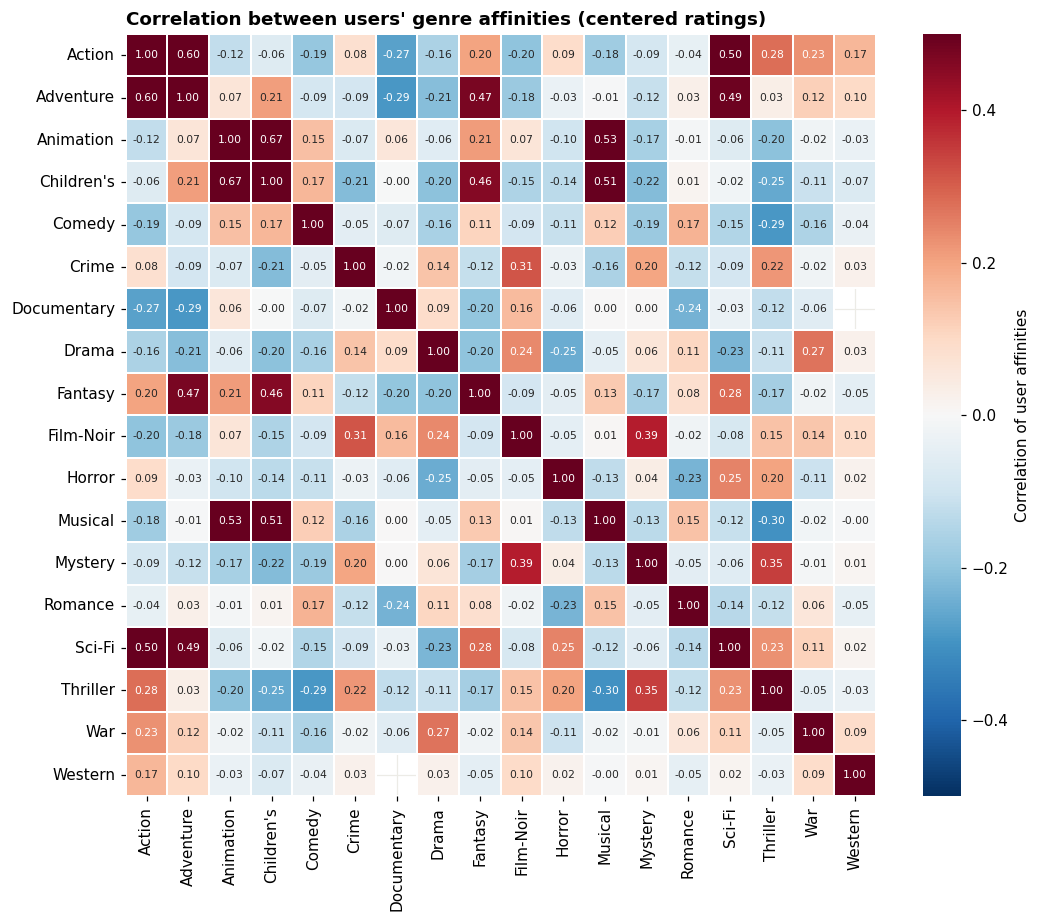

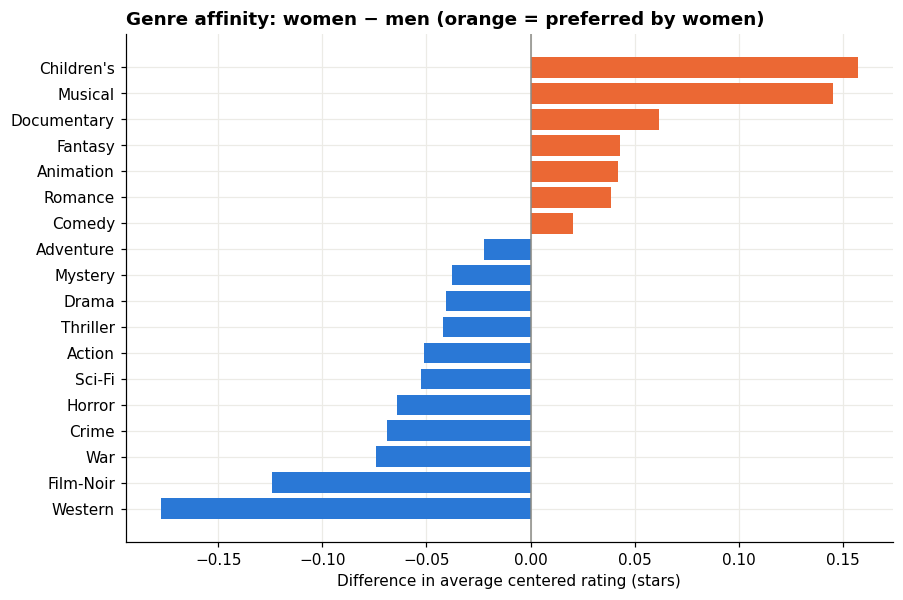

In [16]:
# ==============================
# 5.5.1 User × genre affinity (centered ratings)
# ==============================
r = ratings[["user_id", "movie_id", "rating"]].copy()
r["dev"] = r["rating"] - r["user_id"].map(user_stats["mean"])        # taste, net of the user's scale

rgu = r.merge(movies[["movie_id"] + g_cols], on="movie_id")
MIN_R = 5                                                              # min ratings in a genre to compute affinity
aff = {}
for g in GENRES:
    s = rgu.loc[rgu[f"g_{g}"] == 1].groupby("user_id")["dev"].agg(["mean", "size"])
    aff[g] = s.loc[s["size"] >= MIN_R, "mean"]
aff = pd.DataFrame(aff)                                                # users × genres (NaN = not enough ratings)

# How strong are individual genre preferences?
enough = aff.notna().sum(axis=1) >= 5
spread = (aff.max(axis=1) - aff.min(axis=1))[enough]
print(f"Users with affinity in ≥ 5 genres: {enough.sum():,}")
print(f"Median gap between a user's favorite and least favorite genre: {spread.median():.2f} stars")

fav = aff[enough].idxmax(axis=1).value_counts(normalize=True)
print("\nUsers' favorite genre (relative to their own average), share of users:")
display(fav.head(10).to_frame("share_of_users").style.format("{:.1%}"))

# ==============================
# 5.5.2 Which genre preferences go together?
# ==============================
corr = aff.corr(min_periods=300)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.3, linecolor="white", ax=ax,
            cbar_kws={"label": "Correlation of user affinities"})
ax.set(title="Correlation between users' genre affinities (centered ratings)")
plt.show()

# ==============================
# 5.5.3 Do men and women prefer different genres?
# ==============================
by_gender = aff.join(users.set_index("user_id")["gender"]).groupby("gender").mean().T
by_gender["F − M"] = by_gender["F"] - by_gender["M"]
by_gender = by_gender.sort_values("F − M")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(by_gender.index, by_gender["F − M"],
        color=[ORANGE if v > 0 else BLUE for v in by_gender["F − M"]])
ax.axvline(0, color=GREY, lw=1)
ax.set(title="Genre affinity: women − men (orange = preferred by women)",
       xlabel="Difference in average centered rating (stars)")
plt.show()


Movies liked by the same users as 'Toy Story (1995)':


,similar_movie,similarity
0,Toy Story 2 (1999),0.50
1,Raiders of the Lost Ark (1981),0.31
2,"Bug's Life, A (1998)",0.30
3,"Shawshank Redemption, The (1994)",0.29
4,Star Wars: Episode V - The Empire Strikes Back (1980),0.29
5,Star Wars: Episode IV - A New Hope (1977),0.28



Movies liked by the same users as 'Star Wars: Episode IV - A New Hope (1977)':


,similar_movie,similarity
0,Star Wars: Episode V - The Empire Strikes Back (1980),0.67
1,Raiders of the Lost Ark (1981),0.56
2,Star Wars: Episode VI - Return of the Jedi (1983),0.50
3,"Matrix, The (1999)",0.42
4,"Godfather, The (1972)",0.39
5,Indiana Jones and the Last Crusade (1989),0.38



Movies liked by the same users as 'Pulp Fiction (1994)':


,similar_movie,similarity
0,GoodFellas (1990),0.43
1,Reservoir Dogs (1992),0.42
2,Fargo (1996),0.40
3,"Usual Suspects, The (1995)",0.39
4,"Silence of the Lambs, The (1991)",0.36
5,"Godfather, The (1972)",0.34



Movies liked by the same users as 'Titanic (1997)':


,similar_movie,similarity
0,Pretty Woman (1990),0.17
1,Ghost (1990),0.16
2,Forrest Gump (1994),0.15
3,Dances with Wolves (1990),0.14
4,Speed (1994),0.13
5,Jerry Maguire (1996),0.13


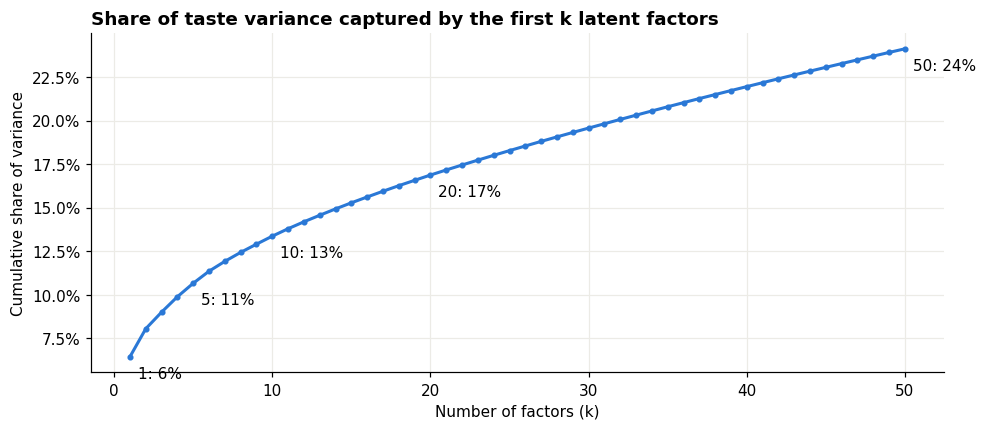


Factor 1
  One end:    ['Star Wars: Episode IV - A New Hope (1977)', 'Raiders of the Lost Ark (1981)', 'Star Wars: Episode V - The Empire Strikes Back (1980)', 'American Beauty (1999)', 'Godfather, The (1972)', 'Shawshank Redemption, The (1994)']
  Other end:  ['Wild Wild West (1999)', 'Batman & Robin (1997)', 'Congo (1995)', 'Judge Dredd (1995)', 'Howard the Duck (1986)', 'Superman III (1983)']

Factor 2
  One end:    ['Fargo (1996)', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963)', 'Annie Hall (1977)', 'Citizen Kane (1941)', 'Chinatown (1974)', 'Being John Malkovich (1999)']
  Other end:  ['Independence Day (ID4) (1996)', 'Jurassic Park (1993)', 'Star Wars: Episode VI - Return of the Jedi (1983)', 'Braveheart (1995)', 'Forrest Gump (1994)', 'Matrix, The (1999)']


In [17]:
# ==============================
# 5.5.4 Item-item similarity (adjusted cosine) among the 1,000 most rated movies
# ==============================
from scipy import sparse
from scipy.sparse.linalg import svds

TOP_SIM = 1000
top_movies = movie_stats.nlargest(TOP_SIM, "n").index
rs = r[r["movie_id"].isin(top_movies)]
u_codes, u_uni = pd.factorize(rs["user_id"])
m_pos = pd.Series(np.arange(TOP_SIM), index=top_movies)

Xc = sparse.csr_matrix((rs["dev"].values.astype(np.float32), (u_codes, m_pos[rs["movie_id"]].values)),
                       shape=(len(u_uni), TOP_SIM))
norms = np.sqrt(np.asarray(Xc.multiply(Xc).sum(axis=0)).ravel()) + 1e-9
S_items = (Xc.T @ Xc).toarray() / np.outer(norms, norms)
np.fill_diagonal(S_items, np.nan)

title_of = movies.set_index("movie_id")["title"]

def similar_movies(title, n=6):
    mid = movies.loc[movies["title"] == title, "movie_id"].iloc[0]
    i = m_pos[mid]
    order = np.argsort(-np.nan_to_num(S_items[i], nan=-9))[:n]
    return pd.DataFrame({"similar_movie": title_of.loc[top_movies[order]].values,
                         "similarity": S_items[i, order]})

for t in ["Toy Story (1995)", "Star Wars: Episode IV - A New Hope (1977)",
          "Pulp Fiction (1994)", "Titanic (1997)"]:
    print(f"\nMovies liked by the same users as '{t}':")
    display(similar_movies(t).style.format({"similarity": "{:.2f}"}))

# ==============================
# 5.5.5 Can tastes be summarized in a few latent factors? (SVD on centered ratings)
# ==============================
u_all, u_uni_all = pd.factorize(r["user_id"])
m_all, m_uni_all = pd.factorize(r["movie_id"])
X_full = sparse.csr_matrix((r["dev"].values.astype(np.float64), (u_all, m_all)))

K_SVD = 50
U_, s_, Vt_ = svds(X_full, k=K_SVD)
order = np.argsort(-s_)
s_, Vt_ = s_[order], Vt_[order]
cum_var = np.cumsum(s_ ** 2) / (r["dev"] ** 2).sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1, K_SVD + 1), cum_var, color=BLUE, lw=2, marker="o", ms=3)
for k in (1, 5, 10, 20, 50):
    ax.annotate(f"{k}: {cum_var[k-1]:.0%}", (k, cum_var[k-1]), xytext=(5, -14), textcoords="offset points")
ax.set(title="Share of taste variance captured by the first k latent factors",
       xlabel="Number of factors (k)", ylabel="Cumulative share of variance")
pct_axis(ax)
plt.show()

# Interpret the first two factors (movies with ≥ 300 ratings; the sign of a factor is arbitrary)
popular_mask = pd.Index(m_uni_all).isin(movie_stats.index[movie_stats["n"] >= 300])
for f in (0, 1):
    load = pd.Series(Vt_[f], index=m_uni_all)[popular_mask].sort_values()
    print(f"\nFactor {f + 1}")
    print("  One end:   ", title_of.loc[load.index[:6]].tolist())
    print("  Other end: ", title_of.loc[load.index[-6:][::-1]].tolist())

### 5.5 Taste Structure — Key Findings

**1. Users have clear genre preferences, beyond their rating scale**
- 5,246 users have enough ratings to measure their affinity for at least 5 genres.
- The **median gap between a user's favorite and least favorite genre is 1.03 stars** (after removing the user's own rating scale): genre preference is a strong personal signal.
- Most common "favorite genre" (relative to the user's own average): **War (18.1%)**, Drama (10.4%), Film-Noir (9.9%), Crime (8.5%), Animation (7.4%).
- Niche, highly rated genres appear often as favorites: within each genre, users watch only the best-known titles (e.g., classic war films), which inflates their affinity.

**2. Genre preferences form "taste families"**
| Taste family | Genres | Correlation of affinities |
|---|---|---|
| **Blockbuster / spectacle** | Action, Adventure, Sci-Fi, Fantasy | Action–Adventure **0.60**, Action–Sci-Fi 0.50, Adventure–Sci-Fi 0.49, Adventure–Fantasy 0.47 |
| **Family** | Animation, Children's, Musical (+ Fantasy) | Animation–Children's **0.67**, Animation–Musical 0.53, Children's–Musical 0.51 |
| **Dark / suspense** | Film-Noir, Mystery, Thriller, Crime | Film-Noir–Mystery 0.39, Mystery–Thriller 0.35, Crime–Film-Noir 0.31 |
| **Serious drama** | Drama, War, Film-Noir | Drama–War 0.27, Drama–Film-Noir 0.24 |

- **Opposing tastes** also appear: Documentary vs. Action/Adventure (**−0.27 / −0.29**), Musical vs. Thriller (−0.30), Comedy vs. Thriller (−0.29), Drama vs. Horror (−0.25), Romance vs. Horror (−0.23), Drama vs. Sci-Fi (−0.23).
- → Users can be described by a **few broad taste dimensions** rather than 18 independent genres, which supports **user clustering** and **latent factor models**.

**3. Gender-related genre preferences exist, but are small**
- Women prefer **Children's (+0.16 stars)**, **Musical (+0.14)**, Documentary, Fantasy, Animation, Romance and Comedy.
- Men prefer **Western (−0.18)**, **Film-Noir (−0.12)**, War, Crime, Horror, Sci-Fi and Action.
- These differences (≤ 0.18 stars) are **much smaller** than the gap between a user's own favorite and least favorite genre (1.03 stars) → consistent with section 5.2: **demographics are a weak proxy for taste**.

**4. Rating patterns reveal meaningful movie similarities**
Similar movies were computed **only from ratings** (adjusted cosine on centered ratings), with no information about genres, directors or titles:

| Movie | Most similar movies (similarity) | What the model recovered |
|---|---|---|
| *Star Wars IV* | *Empire Strikes Back* (0.67), *Raiders of the Lost Ark* (0.56), *Return of the Jedi* (0.50), *The Matrix* | **Franchise** and classic adventure |
| *Pulp Fiction* | *GoodFellas* (0.43), *Reservoir Dogs* (0.42), *Fargo* (0.40), *The Usual Suspects* | **Same director**, 90s crime / indie cinema |
| *Toy Story* | *Toy Story 2* (0.50), *Raiders* (0.31), *A Bug's Life* (0.30), *Shawshank* | **Sequel** and Pixar, plus widely liked classics |
| *Titanic* | *Pretty Woman* (0.17), *Ghost*, *Forrest Gump*, *Speed*, *Jerry Maguire* | Mainstream crowd-pleasers, with **much weaker** similarities |

- Collaborative signals recover **franchises, directors and styles** without any content data → **collaborative filtering will work** on this dataset.
- Some neighbors are **universally liked classics** (*Shawshank*, *Raiders*), a popularity component that must be controlled.
- *Titanic* has low similarities (≤ 0.17): it was watched by a very **broad and heterogeneous** audience, so no group of users shares a distinct taste around it.

**5. Taste can be summarized in latent factors, but it is noisy**
| Latent factors (k) | 1 | 5 | 10 | 20 | 50 |
|---|---|---|---|---|---|
| Share of taste variance captured | 6% | 11% | 13% | 17% | **24%** |

- The first factors are **interpretable**:
  - **Factor 1 — acclaimed vs. poorly received blockbusters:** *Star Wars*, *Raiders of the Lost Ark*, *The Empire Strikes Back* vs. *Wild Wild West*, *Batman & Robin*, *Congo*, *Judge Dredd*, *Howard the Duck*, *Superman III*.
  - **Factor 2 — mainstream vs. auteur cinema:** *Independence Day*, *Jurassic Park*, *Return of the Jedi*, *Braveheart* vs. *Fargo*, *Dr. Strangelove*, *Annie Hall*, *Citizen Kane*.
- However, even **50 factors capture only \~24%** of the (centered) variance. Part of the remaining variance is **noise**: whole-star ratings, mood, and the fact that users rate movies watched long ago. (This share is also underestimated because unrated movies are treated as "average" in this quick decomposition.)

**Implications for the recommender**
- **Collaborative filtering and matrix factorization are well suited:** rating patterns contain real, interpretable taste structure (franchises, directors, mainstream vs. auteur).
- **Many factors and strong regularization** will be needed: taste is high-dimensional and noisy, so models must avoid overfitting individual ratings.
- **User clustering is promising:** taste families (blockbuster, family, dark/suspense, serious drama) suggest that users can be grouped into interpretable **taste segments**, useful for both recommendations and business insights.
- **User × genre affinity is a strong feature** for the supervised model: it captures personal taste far better than demographics.
- **Popularity must be controlled** in item similarities, otherwise universally liked classics will appear as "similar" to everything.

## 6. EDA Summary and Modeling Decisions

### 6.1 What We Learned

| # | Finding | Evidence | Consequence for the recommender |
|---|---|---|---|
| 1 | **Ratings are positive and self-selected** | 57.5% of ratings are 4–5 stars; users rate movies they chose to watch | Unrated ≠ disliked; ranking must consider both *"will they watch it?"* and *"will they like it?"* |
| 2 | **Users have different rating scales** | User averages from 3.15 (p10) to 4.21 (p90); 100 generous vs. 379 strict users | Every model needs **user biases** (or centered ratings) |
| 3 | **Movies have different quality levels** | Movie mean is a better predictor than user mean (RMSE 0.975 vs. 1.028) | Every model needs **movie biases** |
| 4 | **Simple biases are a strong baseline** | Global mean + user + movie bias: RMSE 1.117 → 0.923 (\~32% of variance) | Baseline to beat; models must learn **taste**, not scales |
| 5 | **Few ratings → unreliable averages** | Top raw averages are movies with 1–3 ratings; Bayesian average surfaces real classics | **Regularization / shrinkage** is mandatory |
| 6 | **Heavy users dominate and are stricter** | Top 20% of users = 57% of ratings; 500+ users average 3.39 vs. 3.77 for light users | Evaluate **by activity segment** |
| 7 | **Demographics are a weak signal** | Spread by gender 0.05, age 0.26, occupation 0.37 stars vs. 1.07 across individual users | Useful mainly for **cold start**, not for personalization |
| 8 | **Moderate popularity bias** | Gini 0.63; top 20% of movies = 65% of ratings; Action/Sci-Fi blockbusters most rated | Measure **coverage and novelty**, not only accuracy |
| 9 | **Item cold start** | 177 movies without ratings; 1 in 3 rated movies has < 50 ratings | Use **content features** (genres, decade) and regularization |
| 10 | **Genre and era shift ratings** | Genre averages 3.22–4.08; decade averages 3.37–4.05 (survivorship bias) | Genres and release decade are useful **features** |
| 11 | **Ratings were made in bulk sessions** | 72.4% of ratings in the user's first 24h; 77.4% share an exact timestamp | Temporal context and sequence order carry little information here |
| 12 | **Clear taste structure** | Taste families (blockbuster, family, dark/suspense); item similarities recover franchises and directors; interpretable latent factors | **Collaborative filtering, matrix factorization and clustering** are well suited |
| 13 | **Taste is high-dimensional and noisy** | 50 latent factors capture only \~24% of centered variance | Use **many factors with strong regularization**; expect modest gains over biases |

### 6.2 Modeling Plan

**Two tasks**
1. **Rating prediction:** predict the star rating a user would give to a movie (regression).
2. **Top-K recommendation:** recommend the K movies a user is most likely to watch and like (ranking).

**Models, from simple to complex**

| # | Model | Idea | Learning paradigm |
|---|---|---|---|
| M0 | **Popularity** | Most watched (Bayesian-ranked) movies for everyone | Baseline (heuristic) |
| M1 | **Bias model** | Global mean + regularized user bias + regularized movie bias | Baseline (statistical) |
| M2 | **Item-item collaborative filtering** | Predict a rating from the user's ratings of **similar movies** (adjusted cosine with shrinkage) | **Unsupervised** (neighborhood) |
| M3 | **Matrix factorization** | Compress users and movies into **latent taste factors** (SVD on centered ratings, and biased MF) | **Unsupervised** (latent factors) |
| M4 | **User clustering** | Group users into **taste segments** (K-means on latent factors / genre affinities); recommend what each segment likes | **Unsupervised** (clustering) |
| M5 | **Supervised rating model** (LightGBM) | Regression on engineered features: biases, user × genre affinities, movie genres / decade / popularity, demographics, and the predictions of M2–M3 | **Supervised** |
| M6 | **Two-stage recommender** | Candidate generation with M3, re-ranking with M5 | **Unsupervised + supervised** |

*Note on paradigms: matrix factorization is trained on observed ratings, but it is usually classified as **unsupervised** because it learns latent representations without explicit features or labels beyond the interaction matrix. M5 is fully **supervised**: it learns a mapping from engineered features to a target (the rating).*

**Feature groups for M5 (from the EDA)**
- **User:** bias, number of ratings, rating std, demographics (gender, age group, occupation), **genre affinities**.
- **Movie:** bias, popularity (log ratings), Bayesian average, genres (one-hot), release decade.
- **User × movie:** affinity of the user for the movie's genres, item-item CF prediction (M2), matrix factorization prediction (M3), user's taste segment (M4).

**Success criteria**
- Each model must beat the **bias model (M1)** on RMSE and on NDCG@10.
- Improvements must hold across **activity segments, gender and age groups**.
- The final system should balance **accuracy** with **catalog coverage and novelty**.

### 6.3 Evaluation Strategy

**Data split (decided in section 5.4)**
- **Per-user temporal split:** for each user, the **last 20%** of their ratings (by timestamp, ties broken by `movie_id`) form the **test set**; the first 80% form the **training set**.
- **Validation:** for tuning hyperparameters, the last 10% of each user's **training** ratings are held out as a validation set. The test set is used **only once**, for the final comparison.
- Every user appears in train and test → no user cold start in the main evaluation (simulated separately if needed).

**Task 1 — Rating prediction**
- Metrics: **RMSE** (penalizes large errors) and **MAE**, on all test ratings.
- Predictions are clipped to the valid range [1, 5].

**Task 2 — Top-K recommendation (K = 10)**
- **Relevant items:** test movies rated **≥ 4 stars** by the user.
- **Candidates:** all movies the user has **not rated in training**.
- Metrics: **Precision@10, Recall@10, NDCG@10, Hit Rate@10**, plus **catalog coverage** and **novelty** (how popular the recommended movies are).
- *Caveat:* we only know ratings for movies the user actually rated. A recommended movie that the user never rated counts as **not relevant**, even if they might have liked it. Top-K metrics are therefore **conservative**, and they favor popular movies (which users are more likely to have watched and rated).

**Why both tasks?** A model can predict ratings well (low RMSE) and still rank poorly: RMSE rewards being accurate on movies the user **already chose to watch**, while top-K rewards finding the right movies **among the whole catalog**. Comparing both shows the trade-off between **"how much will they like it?"** and **"will they watch it at all?"**.

**Segments:** results broken down by **user activity** (20–50 … 500+ ratings), **gender** and **age group**, to check that improvements are not driven only by heavy users and that quality is fair across groups.

## 7. Recommender Models

### 7.1 Evaluation Setup

**Split (per-user temporal, section 6.3)**
- **Test:** last 20% of each user's ratings.
- **Train (full):** first 80% of each user's ratings.
- **Validation:** last 10% of each user's *training* ratings, used only for **hyperparameter tuning**.

**Protocol:** models are tuned with `train → validation`, then **re-fitted on the full training set** and evaluated **once** on the test set.

**Rating prediction:** RMSE and MAE on all test ratings (predictions clipped to [1, 5]).

**Top-K (K = 10):** for each user, rank all movies **not rated in training**; relevant = test movies rated **≥ 4**. Metrics: Precision@10, Recall@10, NDCG@10, Hit Rate@10, catalog coverage, average popularity of recommended movies and **long-tail share** (movies outside the 20% most rated).

In [18]:
# ==============================
# 7.1.1 Per-user temporal split
# ==============================
from scipy import sparse

ratings = ratings.sort_values(["user_id", "timestamp", "movie_id"]).reset_index(drop=True)
ratings["rating_seq"] = ratings.groupby("user_id").cumcount() + 1
ratings["n_user"] = ratings.groupby("user_id")["rating"].transform("size")

cols = ["user_id", "movie_id", "rating", "timestamp"]
is_test = ratings["rating_seq"] > (ratings["n_user"] * 0.8).round()
train_full = ratings.loc[~is_test, cols].reset_index(drop=True)
test       = ratings.loc[is_test, cols].reset_index(drop=True)

# Validation = last 10% of each user's training ratings (for tuning only)
seq_tr = train_full.groupby("user_id").cumcount() + 1
n_tr   = train_full.groupby("user_id")["rating"].transform("size")
is_val = seq_tr > (n_tr * 0.9).round()
train = train_full[~is_val].reset_index(drop=True)
valid = train_full[is_val].reset_index(drop=True)

split_summary = pd.DataFrame({
    "ratings": [len(train), len(valid), len(train_full), len(test)],
    "users": [d["user_id"].nunique() for d in (train, valid, train_full, test)],
    "movies": [d["movie_id"].nunique() for d in (train, valid, train_full, test)],
    "avg_rating": [d["rating"].mean() for d in (train, valid, train_full, test)],
    "share_rating_≥4": [(d["rating"] >= 4).mean() for d in (train, valid, train_full, test)],
}, index=["train (for tuning)", "validation", "train (full)", "test"])
display(split_summary.style.format({"ratings": "{:,}", "users": "{:,}", "movies": "{:,}",
                                    "avg_rating": "{:.3f}", "share_rating_≥4": "{:.1%}"}))

unseen_movies = ~test["movie_id"].isin(train_full["movie_id"])
print(f"Test ratings on movies never seen in training: {unseen_movies.sum():,} ({unseen_movies.mean():.2%})")

,ratings,users,movies,avg_rating,share_rating_≥4
train (for tuning),"720,066","6,040","3,654",3.631,59.4%
validation,"80,127","6,040","3,274",3.491,54.1%
train (full),"800,193","6,040","3,667",3.617,58.8%
test,"200,016","6,040","3,535",3.439,52.3%


Test ratings on movies never seen in training: 54 (0.03%)


In [19]:
# ==============================
# 7.1.2 Rating prediction metrics
# ==============================
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
def mae(y, p):  return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

rating_results, preds_test = [], {}

def eval_rating(pred, name):
    p = np.clip(np.asarray(pred, dtype=float), 1, 5)
    preds_test[name] = p
    rating_results.append({"model": name, "RMSE": rmse(test["rating"], p), "MAE": mae(test["rating"], p)})
    return pd.DataFrame(rating_results[-1:]).set_index("model")

# ==============================
# 7.1.3 Top-K setup: indices, seen items, relevant items
# ==============================
K = 10
users_idx = np.sort(ratings["user_id"].unique())
items_idx = np.sort(train_full["movie_id"].unique())          # recommendable movies (seen in training)
u_pos = pd.Series(np.arange(len(users_idx)), index=users_idx)
i_pos = pd.Series(np.arange(len(items_idx)), index=items_idx)

seen = sparse.csr_matrix((np.ones(len(train_full), dtype=np.int8),
                          (u_pos[train_full["user_id"]].values, i_pos[train_full["movie_id"]].values)),
                         shape=(len(users_idx), len(items_idx)))
seen_r, seen_c = seen.nonzero()

relevant = test[test["rating"] >= 4].groupby("user_id")["movie_id"].apply(set).to_dict()

item_pop = train_full["movie_id"].value_counts().reindex(items_idx).fillna(0).values
pop_rank = pd.Series(item_pop).rank(ascending=False, method="first").values
is_longtail = pop_rank > 0.2 * len(items_idx)                  # outside the 20% most rated movies

def topk_from_scores(scores, k=K):
    """scores: (n_users × n_items) array, or a 1-D item vector for non-personalized models."""
    scores = np.array(np.broadcast_to(scores, (len(users_idx), len(items_idx))), dtype=np.float32)
    scores[seen_r, seen_c] = -np.inf                           # never recommend already rated movies
    top = np.argpartition(-scores, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
    top = np.take_along_axis(top, order, axis=1)
    return {u: items_idx[row] for u, row in zip(users_idx, top)}

topk_results = {}
disc = 1 / np.log2(np.arange(2, K + 2))

def eval_topk(recs, name, k=K):
    P, R, N, H = [], [], [], []
    for u, rel in relevant.items():
        hits = np.isin(recs[u][:k], list(rel))
        h = hits.sum()
        P.append(h / k); R.append(h / len(rel)); H.append(h > 0)
        N.append((hits * disc[:len(hits)]).sum() / disc[:min(len(rel), k)].sum())
    pos = i_pos[np.concatenate([recs[u][:k] for u in users_idx])].values
    topk_results[name] = {
        "Precision@10": np.mean(P), "Recall@10": np.mean(R), "NDCG@10": np.mean(N), "HitRate@10": np.mean(H),
        "Coverage": len(np.unique(pos)) / len(items_idx),
        "Avg. popularity": item_pop[pos].mean(), "Long-tail share": is_longtail[pos].mean(),
    }
    return pd.DataFrame([topk_results[name]], index=[name])

FMT_TOPK = {"Precision@10": "{:.4f}", "Recall@10": "{:.4f}", "NDCG@10": "{:.4f}", "HitRate@10": "{:.1%}",
            "Coverage": "{:.1%}", "Avg. popularity": "{:,.0f}", "Long-tail share": "{:.1%}"}
FMT_RATING = {"RMSE": "{:.4f}", "MAE": "{:.4f}"}

def show_results():
    print("Rating prediction (test):")
    display(pd.DataFrame(rating_results).set_index("model").style.format(FMT_RATING))
    print("Top-10 recommendation (test):")
    display(pd.DataFrame(topk_results).T.style.format(FMT_TOPK))

# Reference: theoretical ceiling of Precision@10 (users can have fewer than 10 relevant test movies)
n_rel = pd.Series({u: len(r) for u, r in relevant.items()})
print(f"Users with ≥ 1 relevant test movie: {len(relevant):,} of {len(users_idx):,}")
print(f"Relevant test movies per user: median = {n_rel.median():.0f}, mean = {n_rel.mean():.1f}")
print(f"Ceiling of Precision@10 (perfect ranking): {np.mean(np.minimum(n_rel, K) / K):.3f}")

Users with ≥ 1 relevant test movie: 5,968 of 6,040
Relevant test movies per user: median = 11, mean = 17.5
Ceiling of Precision@10 (perfect ranking): 0.773


### 7.2 Baselines: M0 Popularity and M1 Bias Model

| Model | Rating prediction | Top-K ranking |
|---|---|---|
| **M0** | Global mean for everyone | **M0a:** most rated movies · **M0b:** best rated movies (Bayesian average) |
| **M1** | Global mean + **regularized** user bias + **regularized** movie bias | Movies with the highest movie bias |

**Regularized biases** (fitted by alternating least squares):

$$b_u = \frac{\sum_{i \in R(u)} (r_{ui} - \mu - b_i)}{\lambda_u + |R(u)|} \qquad b_i = \frac{\sum_{u \in R(i)} (r_{ui} - \mu - b_u)}{\lambda_i + |R(i)|}$$

The regularization strengths $\lambda_u$ and $\lambda_i$ shrink the biases of users and movies with few ratings toward 0 (section 5.1). They are tuned on the **validation** set.

*Note:* for top-K, the user bias is the same for all of a user's candidates, so **M1 ranks movies by their bias only**: it is still a **non-personalized** ranking.

In [20]:
# ==============================
# 7.2.1 M0 — Global mean and popularity
# ==============================
mu_tr = train_full["rating"].mean()
eval_rating(np.full(len(test), mu_tr), "M0 Global mean")

# M0a — most rated movies
recs_m0a = topk_from_scores(item_pop.astype(np.float32))
eval_topk(recs_m0a, "M0a Most rated")

# M0b — best rated movies (Bayesian average, prior = median number of ratings)
st = train_full.groupby("movie_id")["rating"].agg(["size", "mean"]).reindex(items_idx)
M_prior = st["size"].median()
bayes_tr = ((st["size"] * st["mean"] + M_prior * mu_tr) / (st["size"] + M_prior)).values
recs_m0b = topk_from_scores(bayes_tr.astype(np.float32))
eval_topk(recs_m0b, "M0b Best rated (Bayesian)")

print("Top 10 most rated (M0a):", title_of.loc[items_idx[np.argsort(-item_pop)[:10]]].tolist())
print("Top 10 best rated (M0b):", title_of.loc[items_idx[np.argsort(-bayes_tr)[:10]]].tolist())
show_results()

Top 10 most rated (M0a): ['American Beauty (1999)', 'Star Wars: Episode V - The Empire Strikes Back (1980)', 'Star Wars: Episode IV - A New Hope (1977)', 'Star Wars: Episode VI - Return of the Jedi (1983)', 'Saving Private Ryan (1998)', 'Jurassic Park (1993)', 'Terminator 2: Judgment Day (1991)', 'Matrix, The (1999)', 'Back to the Future (1985)', 'Raiders of the Lost Ark (1981)']
Top 10 best rated (M0b): ['Shawshank Redemption, The (1994)', 'Godfather, The (1972)', 'Usual Suspects, The (1995)', "Schindler's List (1993)", 'Raiders of the Lost Ark (1981)', 'Seven Samurai (The Magnificent Seven) (Shichinin no samurai) (1954)', 'Star Wars: Episode IV - A New Hope (1977)', 'Wrong Trousers, The (1993)', 'Close Shave, A (1995)', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963)']
Rating prediction (test):


,RMSE,MAE
model,,
M0 Global mean,1.1469,0.9440


Top-10 recommendation (test):


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M0a Most rated,0.0795,0.0471,0.0904,38.9%,3.2%,"2,323",0.0%
M0b Best rated (Bayesian),0.0499,0.0277,0.0560,27.6%,2.4%,"1,369",0.1%


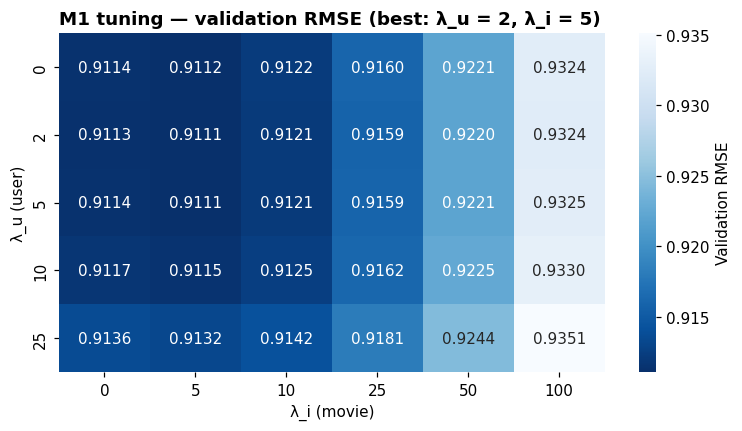

Top 10 by movie bias (M1): ['Sanjuro (1962)', 'Seven Samurai (The Magnificent Seven) (Shichinin no samurai) (1954)', 'Shawshank Redemption, The (1994)', 'Usual Suspects, The (1995)', 'Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)', 'Close Shave, A (1995)', 'Godfather, The (1972)', 'Wrong Trousers, The (1993)', 'Paths of Glory (1957)', "Schindler's List (1993)"]
Rating prediction (test):


,RMSE,MAE
model,,
M0 Global mean,1.1469,0.9440
M1 Bias model (no regularization),0.9210,0.7225
M1 Bias model (regularized),0.9211,0.7234


Top-10 recommendation (test):


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M0a Most rated,0.0795,0.0471,0.0904,38.9%,3.2%,"2,323",0.0%
M0b Best rated (Bayesian),0.0499,0.0277,0.0560,27.6%,2.4%,"1,369",0.1%
M1 Bias model (regularized),0.0293,0.0163,0.0272,19.1%,1.5%,869,21.4%


In [21]:
# ==============================
# 7.2.2 M1 — Regularized bias model
# ==============================
def fit_biases(df, lam_u=10, lam_i=25, n_iter=8):
    mu = df["rating"].mean()
    bi = pd.Series(0.0, index=df["movie_id"].unique())
    for _ in range(n_iter):
        res = df["rating"] - mu - df["movie_id"].map(bi).values
        g = res.groupby(df["user_id"]); bu = g.sum() / (g.count() + lam_u)
        res = df["rating"] - mu - df["user_id"].map(bu).values
        g = res.groupby(df["movie_id"]); bi = g.sum() / (g.count() + lam_i)
    return mu, bu, bi

def predict_biases(model, df):
    mu, bu, bi = model
    return mu + df["user_id"].map(bu).fillna(0).values + df["movie_id"].map(bi).fillna(0).values

# Tune λ_u, λ_i on validation
grid = []
for lu in [0, 2, 5, 10, 25]:
    for li in [0, 5, 10, 25, 50, 100]:
        m = fit_biases(train, lu, li)
        grid.append({"lam_u": lu, "lam_i": li, "RMSE_valid": rmse(valid["rating"], np.clip(predict_biases(m, valid), 1, 5))})
grid = pd.DataFrame(grid)
best = grid.loc[grid["RMSE_valid"].idxmin()]
LAM_U, LAM_I = int(best["lam_u"]), int(best["lam_i"])

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(grid.pivot(index="lam_u", columns="lam_i", values="RMSE_valid"), annot=True, fmt=".4f",
            cmap="Blues_r", ax=ax, cbar_kws={"label": "Validation RMSE"})
ax.set(title=f"M1 tuning — validation RMSE (best: λ_u = {LAM_U}, λ_i = {LAM_I})",
       xlabel="λ_i (movie)", ylabel="λ_u (user)")
plt.show()

# Re-fit on the full training set and evaluate on test
m1_noreg = fit_biases(train_full, 0, 0)
m1 = fit_biases(train_full, LAM_U, LAM_I)
eval_rating(predict_biases(m1_noreg, test), "M1 Bias model (no regularization)")
eval_rating(predict_biases(m1, test), "M1 Bias model (regularized)")

mu1, bu1, bi1 = m1
bi_vec = bi1.reindex(items_idx).fillna(0).values.astype(np.float32)
recs_m1 = topk_from_scores(bi_vec)
eval_topk(recs_m1, "M1 Bias model (regularized)")

print("Top 10 by movie bias (M1):", title_of.loc[items_idx[np.argsort(-bi_vec)[:10]]].tolist())
show_results()

### 7.2 Baselines — Results

**0. Split and evaluation setup**
| Set | Ratings | Users | Movies | Avg. rating | Share ≥ 4 stars |
|---|---|---|---|---|---|
| Train (for tuning) | 720,066 | 6,040 | 3,654 | 3.631 | 59.4% |
| Validation | 80,127 | 6,040 | 3,274 | 3.491 | 54.1% |
| **Train (full)** | **800,193** | 6,040 | 3,667 | 3.617 | 58.8% |
| **Test** | **200,016** | 6,040 | 3,535 | **3.439** | **52.3%** |

- Every user appears in train and test, and only **54 test ratings (0.03%)** are on movies never seen in training → item cold start is negligible in this evaluation.
- **Later ratings are lower:** the average rating drops from 3.62 (train) to 3.49 (validation) and **3.44 (test)**, and the share of 4–5 star ratings from 58.8% to **52.3%**. This confirms section 5.4: each user's later ratings are stricter and go to less popular movies, so **the test set is harder** than the training data.
- **Top-K setup:** 5,968 of 6,040 users have at least one relevant test movie (rated ≥ 4), with a **median of 11** (mean 17.5) relevant movies per user.
- **Ceiling of Precision@10 = 0.773:** even a perfect ranking cannot reach 1, because some users have fewer than 10 relevant test movies. The best baseline (M0a, Precision@10 = 0.0795) reaches only **\~10% of this ceiling**.

**Rating prediction (test)**
| Model | RMSE | MAE |
|---|---|---|
| M0 Global mean | 1.1469 | 0.9440 |
| M1 Bias model (no regularization) | **0.9210** | **0.7225** |
| M1 Bias model (regularized, λ_u = 2, λ_i = 5) | 0.9211 | 0.7234 |

**Top-10 recommendation (test)**
| Model | Precision@10 | Recall@10 | NDCG@10 | Hit Rate@10 | Coverage | Avg. popularity | Long-tail share |
|---|---|---|---|---|---|---|---|
| **M0a Most rated** | **0.0795** | **0.0471** | **0.0904** | **38.9%** | 3.2% | 2,323 | 0.0% |
| M0b Best rated (Bayesian) | 0.0499 | 0.0277 | 0.0560 | 27.6% | 2.4% | 1,369 | 0.1% |
| M1 Bias model | 0.0293 | 0.0163 | 0.0272 | 19.1% | 1.5% | 869 | 21.4% |

**1. Biases are a strong baseline for rating prediction**
- User and movie biases reduce RMSE by **\~20%** vs. the global mean (1.147 → 0.921).
- The test RMSE of the global mean (1.147) is **higher than in the EDA** (1.117): each user's **later ratings are lower and harder to predict**, and the test average (3.44) is 0.18 stars below the training average (3.62). Models trained on earlier ratings will tend to **overestimate** test ratings.

**2. Regularization barely matters for RMSE here**
- Validation selected **very light regularization** (λ_u = 2, λ_i = 5); the error surface is flat for small values and only degrades with strong shrinkage (λ_i ≥ 50 → RMSE ≥ 0.922).
- On test, regularized and unregularized biases are practically identical (0.9211 vs. 0.9210).
- Reason: the movies users rate in their test period are mostly **popular movies with many ratings**, whose biases are already reliable. Shrinkage mostly affects rarely rated movies, which seldom appear in the test set.

**3. For ranking, the order is reversed: popularity wins**
- **Most rated (M0a)** is the best baseline for top-K: almost **4 in 10 users** get at least one relevant movie among 10 suggestions.
- **Best rated (M0b)** recommends acclaimed classics (*Shawshank*, *The Godfather*, *Schindler's List*) and performs **\~38% worse** in NDCG.
- **The bias model (M1)** is the **worst** ranker: with light regularization, the highest movie biases belong to **excellent but rarely watched** films (*Sanjuro*, *Seven Samurai*), so 21.4% of its recommendations are long-tail movies that users rarely rate.

**4. Why: offline top-K rewards "will they watch it?", not only "will they like it?"**
- The test set only contains movies that users **chose to watch and rate**. A great movie the user never watched counts as a **miss**, even if they would have loved it.
- Popular movies are the ones most users eventually watch, so recommending them is rewarded offline.
- → **The model that best predicts ratings (M1) is the worst at ranking**: **RMSE and top-K measure different things**, and optimizing one does not optimize the other.

**5. All baselines are non-personalized**
- They recommend (almost) the same 10 movies to everyone: catalog **coverage is only 1.5–3.2%**.
- Personalized models must beat **M0a (most rated)** on NDCG@10 and **M1 (biases)** on RMSE.

**Targets for the next models:** RMSE < **0.921** and NDCG@10 > **0.090**.

### 7.3 M2 — Item-Item Collaborative Filtering (Unsupervised)

**Idea:** a user's rating for a movie can be predicted from how they rated **similar movies**, where similarity is learned **only from rating patterns** (section 5.5 showed that this recovers franchises, directors and styles).

**Rating prediction (M2a)** — baseline + weighted average of the user's residuals on the *k* most similar movies they rated:

$$\hat r_{ui} = \underbrace{\mu + b_u + b_i}_{\text{M1 baseline}} + \frac{\sum_{j \in N_k(i;u)} s_{ij}\,(r_{uj} - \mu - b_u - b_j)}{\sum_{j \in N_k(i;u)} s_{ij}}$$

- $s_{ij}$: cosine similarity between the **residuals** of movies *i* and *j* (ratings net of biases), keeping only positive similarities.
- **Shrinkage:** $s_{ij} \leftarrow s_{ij} \cdot \frac{n_{ij}}{n_{ij} + \beta}$, where $n_{ij}$ is the number of users who rated both movies: similarities based on few common users are pulled toward 0.
- Hyperparameters **k** (neighbors) and **β** (shrinkage) are tuned on the **validation** set.

**Top-K ranking — two scoring strategies**
- **M2b — co-watching:** score = sum of the **binary** cosine similarities ("watched by the same users") between a candidate and the movies the user rated → *"will they watch it?"*
- **M2c — predicted rating:** score = predicted rating using all positive neighbors → *"will they like it?"*

**Learning paradigm:** **unsupervised** — item similarities are computed from the user × movie matrix without any labels or features.

In [22]:
import gc

# ==============================
# 7.3.1 Item-item similarities (residual cosine with shrinkage, and binary co-watching)
# ==============================
def item_similarities(tr_df, base_model, beta):
    """Returns S_res (shrunk residual cosine), S_bin (binary cosine), E (residual matrix), B (binary matrix)."""
    e = (tr_df["rating"].values - predict_biases(base_model, tr_df)).astype(np.float32)
    r = u_pos[tr_df["user_id"]].values
    c = i_pos[tr_df["movie_id"]].values
    shape = (len(users_idx), len(items_idx))
    E = sparse.csr_matrix((e, (r, c)), shape=shape)
    B = sparse.csr_matrix((np.ones(len(e), dtype=np.float32), (r, c)), shape=shape)

    n_co = (B.T @ B).toarray().astype(np.float32)                    # users who rated both movies
    sq = np.asarray(E.multiply(E).sum(axis=0)).ravel()
    S_res = (E.T @ E).toarray().astype(np.float32) / (np.sqrt(np.outer(sq, sq)).astype(np.float32) + 1e-9)
    S_res *= n_co / (n_co + beta)                                    # shrinkage
    np.fill_diagonal(S_res, 0)

    n_i = np.diag(n_co).copy()
    S_bin = n_co / (np.sqrt(np.outer(n_i, n_i)).astype(np.float32) + 1e-9)
    np.fill_diagonal(S_bin, 0)
    return S_res, S_bin, E, B

# ==============================
# 7.3.2 kNN rating prediction
# ==============================
def knn_predict(S, base_model, tr_df, pairs, k):
    base_tr = predict_biases(base_model, tr_df)
    e  = (tr_df["rating"].values - base_tr).astype(np.float32)
    tu = tr_df["user_id"].values
    ti = i_pos[tr_df["movie_id"]].values
    o = np.argsort(tu, kind="stable"); tu, ti, e = tu[o], ti[o], e[o]
    t_start, t_end = np.searchsorted(tu, users_idx), np.searchsorted(tu, users_idx, side="right")

    out = predict_biases(base_model, pairs).astype(np.float64)
    pu = pairs["user_id"].values
    pi = i_pos.reindex(pairs["movie_id"]).values                     # NaN for movies unseen in training
    po = np.argsort(pu, kind="stable")
    p_start, p_end = np.searchsorted(pu[po], users_idx), np.searchsorted(pu[po], users_idx, side="right")

    for n in range(len(users_idx)):
        rows = po[p_start[n]:p_end[n]]
        if len(rows) == 0:
            continue
        tgt = pi[rows]
        ok = ~np.isnan(tgt)
        rows, tgt = rows[ok], tgt[ok].astype(int)
        items_r, e_r = ti[t_start[n]:t_end[n]], e[t_start[n]:t_end[n]]
        sims = np.maximum(S[np.ix_(tgt, items_r)], 0)                # positive similarities only
        if items_r.size > k:
            idx = np.argpartition(-sims, k, axis=1)[:, :k]
            sims, e_k = np.take_along_axis(sims, idx, axis=1), e_r[idx]
        else:
            e_k = np.broadcast_to(e_r, sims.shape)
        num, den = (sims * e_k).sum(axis=1), sims.sum(axis=1)
        out[rows] += np.where(den > 0, num / (den + 1e-9), 0)
    return out

# ==============================
# 7.3.3 Tune k and β on validation (model fitted on the tuning train set)
# ==============================
m1_tune = fit_biases(train, LAM_U, LAM_I)
grid_knn = []
for beta in [25, 100]:
    S_res_t, _, _, _ = item_similarities(train, m1_tune, beta)
    for k in [20, 50, 100, 200]:
        p = knn_predict(S_res_t, m1_tune, train, valid, k)
        grid_knn.append({"beta": beta, "k": k, "RMSE_valid": rmse(valid["rating"], np.clip(p, 1, 5))})
    del S_res_t; gc.collect()

grid_knn = pd.DataFrame(grid_knn)
best_knn = grid_knn.loc[grid_knn["RMSE_valid"].idxmin()]
BETA, K_NN = int(best_knn["beta"]), int(best_knn["k"])
print(f"Validation RMSE of M1 (biases) for reference: "
      f"{rmse(valid['rating'], np.clip(predict_biases(m1_tune, valid), 1, 5)):.4f}")
display(grid_knn.pivot(index="beta", columns="k", values="RMSE_valid").style.format("{:.4f}")
        .highlight_min(axis=None, color="#cde2fb"))
print(f"Best: β = {BETA}, k = {K_NN}")

Validation RMSE of M1 (biases) for reference: 0.9111


k,20,50,100,200
beta,,,,
25,0.8638,0.8643,0.8669,0.8684
100,0.8654,0.8648,0.8666,0.8676


Best: β = 25, k = 20


In [23]:
# ==============================
# 7.3.4 Re-fit on the full training set and evaluate on test
# ==============================
S_res, S_bin, E_tr, B_tr = item_similarities(train_full, m1, BETA)

# M2a — kNN rating prediction
pred_m2a = knn_predict(S_res, m1, train_full, test, K_NN)
eval_rating(pred_m2a, f"M2a Item-kNN (k = {K_NN}, β = {BETA})")

# M2b — ranking by co-watching similarity ("will they watch it?")
scores_m2b = np.asarray(B_tr @ S_bin)
recs_m2b = topk_from_scores(scores_m2b)
eval_topk(recs_m2b, "M2b Item-kNN co-watching")
del scores_m2b; gc.collect()

# M2c — ranking by predicted rating ("will they like it?"), all positive neighbors
S_pos = np.maximum(S_res, 0)
mu1, bu1, bi1 = m1
base_all = (mu1 + bu1.reindex(users_idx).fillna(0).values[:, None]
            + bi1.reindex(items_idx).fillna(0).values[None, :]).astype(np.float32)
num = np.asarray(E_tr @ S_pos)
den = np.asarray(B_tr @ S_pos)
scores_m2c = base_all + np.where(den > 0, num / (den + 1.0), 0)      # +1 damps predictions with weak neighbors
recs_m2c = topk_from_scores(scores_m2c)
eval_topk(recs_m2c, "M2c Item-kNN predicted rating")
del num, den, scores_m2c, S_pos; gc.collect()

show_results()

# Example: recommendations for one user
u = users_idx[0]
print(f"\nUser {u} — top rated movies in training:")
top_u = train_full[train_full["user_id"] == u].nlargest(5, "rating")["movie_id"]
print(title_of.loc[top_u].tolist())
print("M2b (co-watching):     ", title_of.loc[recs_m2b[u][:6]].tolist())
print("M2c (predicted rating):", title_of.loc[recs_m2c[u][:6]].tolist())

Rating prediction (test):


,RMSE,MAE
model,,
M0 Global mean,1.1469,0.9440
M1 Bias model (no regularization),0.9210,0.7225
M1 Bias model (regularized),0.9211,0.7234
"M2a Item-kNN (k = 20, β = 25)",0.8748,0.6812


Top-10 recommendation (test):


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M0a Most rated,0.0795,0.0471,0.0904,38.9%,3.2%,"2,323",0.0%
M0b Best rated (Bayesian),0.0499,0.0277,0.0560,27.6%,2.4%,"1,369",0.1%
M1 Bias model (regularized),0.0293,0.0163,0.0272,19.1%,1.5%,869,21.4%
M2b Item-kNN co-watching,0.0930,0.0769,0.1133,49.9%,13.4%,"1,742",0.4%
M2c Item-kNN predicted rating,0.0358,0.0206,0.0394,22.0%,4.7%,830,23.4%



User 1 — top rated movies in training:
['Cinderella (1950)', 'Back to the Future (1985)', 'Last Days of Disco, The (1998)', 'Christmas Story, A (1983)', "One Flew Over the Cuckoo's Nest (1975)"]
M2b (co-watching):      ['Star Wars: Episode V - The Empire Strikes Back (1980)', 'Raiders of the Lost Ark (1981)', 'Groundhog Day (1993)', 'Shawshank Redemption, The (1994)', 'Pulp Fiction (1994)', 'Toy Story (1995)']
M2c (predicted rating): ['Shawshank Redemption, The (1994)', 'Sanjuro (1962)', 'Paths of Glory (1957)', 'Godfather, The (1972)', 'Usual Suspects, The (1995)', 'Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)']


### 7.3 M2 — Results

**Tuning (validation RMSE; M1 biases = 0.9111)**
| β \ k | 20 | 50 | 100 | 200 |
|---|---|---|---|---|
| 25 | **0.8638** | 0.8643 | 0.8669 | 0.8684 |
| 100 | 0.8654 | 0.8648 | 0.8666 | 0.8676 |

- Best: **k = 20 neighbors, β = 25**. The error surface is flat (0.864–0.868): the model is robust to these choices.
- **Fewer neighbors work better:** the 20 most similar movies carry the signal; adding weaker neighbors adds noise.

**Rating prediction (test)**
| Model | RMSE | MAE | vs. M1 (RMSE) |
|---|---|---|---|
| M1 Bias model (regularized) | 0.9211 | 0.7234 | — |
| **M2a Item-kNN (k = 20, β = 25)** | **0.8748** | **0.6812** | **−5.0%** |

**Top-10 recommendation (test)**
| Model | Precision@10 | Recall@10 | NDCG@10 | Hit Rate@10 | Coverage | Avg. popularity | Long-tail share |
|---|---|---|---|---|---|---|---|
| M0a Most rated | 0.0795 | 0.0471 | 0.0904 | 38.9% | 3.2% | 2,323 | 0.0% |
| M1 Bias model | 0.0293 | 0.0163 | 0.0272 | 19.1% | 1.5% | 869 | 21.4% |
| **M2b Item-kNN co-watching** | **0.0930** | **0.0769** | **0.1133** | **49.9%** | **13.4%** | 1,742 | 0.4% |
| M2c Item-kNN predicted rating | 0.0358 | 0.0206 | 0.0394 | 22.0% | 4.7% | 830 | 23.4% |

**1. Personalization improves rating prediction**
- M2a reduces RMSE by **5.0%** vs. the bias model (0.921 → 0.875) and MAE by 5.8%. The gain is consistent with validation (−5.2%).
- This is the first model that uses **each user's taste**: the rating of a movie is adjusted by how the user rated its 20 most similar movies, beyond their general rating scale.

**2. Co-watching similarity is the best ranker so far**
- **M2b** beats the best baseline (most rated) on every accuracy metric: **NDCG@10 +25%** (0.090 → 0.113), **Recall@10 +63%**, Precision@10 +17%, and **half of the users (49.9%)** get at least one relevant movie in their top 10.
- It is also **far more diverse**: **coverage 13.4% vs. 3.2%** (4× more movies recommended), with less popular recommendations on average (1,742 vs. 2,323 ratings).
- Precision@10 reaches **\~12% of the theoretical ceiling** (0.093 / 0.773).
- → Recommending what **"people who watched what you watched also watched"** captures both personal taste **and** the likelihood of watching a movie.

**3. Ranking by predicted rating does not work well**
- **M2c** improves over the bias model (NDCG 0.027 → 0.039), but remains **far below popularity** (0.090).
- Its top predictions are again **acclaimed but rarely watched** classics (*Sanjuro*, *Paths of Glory*, *The Godfather*, *Shawshank*), with 23.4% long-tail recommendations. The predicted rating is dominated by the **movie bias**, so many users get similar lists (coverage 4.7%).
- → Even with a better rating model, **"will they like it?" alone is not enough** to rank: offline top-K mostly rewards **"will they watch it?"**.

**4. Qualitative example (user 1)**
- Liked in training: *Cinderella*, *Back to the Future*, *A Christmas Story*, *One Flew Over the Cuckoo's Nest* (family and classic films).
- **M2b (co-watching):** *The Empire Strikes Back*, *Raiders of the Lost Ark*, *Groundhog Day*, *Shawshank* → popular, broadly appealing classics, coherent with the user's history.
- **M2c (predicted rating):** *Shawshank*, *Sanjuro*, *Paths of Glory*, *The Godfather* → acclaimed films, less connected to this user's family-oriented taste.

**Conclusions**
- **Item-item collaborative filtering (unsupervised)** improves both tasks over the baselines, confirming the taste structure found in the EDA.
- The **scoring must match the task**: residual similarities for rating prediction (M2a), co-watching similarities for ranking (M2b).
- **Best models so far:** M2a for rating prediction (RMSE **0.875**), M2b for top-10 (NDCG@10 **0.113**).

### 7.4 M3 — Matrix Factorization (Unsupervised, Latent Factors)

**Idea:** represent each user and each movie as a vector of *k* **latent taste factors** (section 5.5 found interpretable factors such as *acclaimed vs. poorly received blockbusters* and *mainstream vs. auteur cinema*). A user's affinity for a movie is the dot product of their vectors:

$$\hat r_{ui} = \underbrace{\mu + b_u + b_i}_{\text{M1 baseline}} + p_u^\top q_i$$

| Model | How the factors are learned | Task |
|---|---|---|
| **M3a — Truncated SVD** | SVD of the residual matrix (ratings − M1 baseline), treating unrated movies as 0 (= "as expected by the baseline") | Rating prediction |
| **M3b — Biased MF (ALS)** | Alternating Least Squares on **observed residuals only**, with weighted-λ regularization: $\min \sum_{(u,i)} (e_{ui} - p_u^\top q_i)^2 + \lambda (n_u \lVert p_u \rVert^2 + n_i \lVert q_i \rVert^2)$ | Rating prediction |
| **M3c — PureSVD (implicit)** | SVD of the **binary** "rated / not rated" matrix → captures *what* users watch | Top-K ("will they watch it?") |
| **M3d — ALS predicted rating** | Same factors as M3b, ranking by predicted rating | Top-K ("will they like it?") |

**Tuning (validation set):** number of factors *k* for all models, regularization λ and number of iterations for ALS. Ranking models are tuned on **validation NDCG@10** (relevant = validation ratings ≥ 4).

**Learning paradigm:** **unsupervised** — latent factors are discovered from the user × movie matrix only, without features or external labels.

In [24]:
# ==============================
# 7.4.1 Helpers
# ==============================
import gc
from scipy.sparse.linalg import svds

for obj in ["S_res", "S_bin"]:                     # free memory from M2
    globals().pop(obj, None)
gc.collect()

def build_matrices(df, base_model):
    """Residual matrix E (ratings − M1 baseline) and binary matrix B (rated / not rated)."""
    e = (df["rating"].values - predict_biases(base_model, df)).astype(np.float64)
    r, c = u_pos[df["user_id"]].values, i_pos[df["movie_id"]].values
    shape = (len(users_idx), len(items_idx))
    return (sparse.csr_matrix((e, (r, c)), shape=shape),
            sparse.csr_matrix((np.ones(len(e)), (r, c)), shape=shape))

def mf_predict(P, Q, base_model, pairs):
    """Baseline + dot product of user and movie factors."""
    out = predict_biases(base_model, pairs).astype(np.float64)
    u = u_pos[pairs["user_id"]].values
    i = i_pos.reindex(pairs["movie_id"]).values
    ok = ~np.isnan(i)
    out[ok] += np.einsum("ij,ij->i", P[u[ok]], Q[i[ok].astype(int)])
    return out

def sorted_svds(M, k):
    U, s, Vt = svds(M, k=k)
    o = np.argsort(-s)
    return U[:, o], s[o], Vt[o]

E_t, B_t = build_matrices(train, m1_tune)          # for tuning (train → validation)
E_f, B_f = build_matrices(train_full, m1)          # for the final model (train_full → test)

# ==============================
# 7.4.2 M3a — Truncated SVD on residuals
# ==============================
KS_SVD = [5, 10, 20, 50, 100]
U_t, s_t, Vt_t = sorted_svds(E_t, max(KS_SVD))
grid_svd = pd.DataFrame([{
    "k": k,
    "RMSE_valid": rmse(valid["rating"], np.clip(mf_predict(U_t[:, :k] * s_t[:k], Vt_t[:k].T, m1_tune, valid), 1, 5)),
} for k in KS_SVD]).set_index("k")
K_SVD_BEST = int(grid_svd["RMSE_valid"].idxmin())
display(grid_svd.T.style.format("{:.4f}").highlight_min(axis=1, color="#cde2fb"))

U_f, s_f, Vt_f = sorted_svds(E_f, K_SVD_BEST)
pred_m3a = mf_predict(U_f * s_f, Vt_f.T, m1, test)
eval_rating(pred_m3a, f"M3a Truncated SVD on residuals (k = {K_SVD_BEST})")
del U_t, s_t, Vt_t; gc.collect()

k,5,10,20,50,100
RMSE_valid,0.8976,0.8946,0.8930,0.8934,0.8965


35

k =  20, λ = 0.03  → best validation RMSE 0.9166 (iteration 10) — 0.1 min
k =  20, λ = 0.06  → best validation RMSE 0.8817 (iteration 10) — 0.1 min
k =  20, λ = 0.1   → best validation RMSE 0.8764 (iteration 10) — 0.1 min
k =  50, λ = 0.03  → best validation RMSE 0.9344 (iteration 7) — 0.2 min
k =  50, λ = 0.06  → best validation RMSE 0.8816 (iteration 10) — 0.2 min
k =  50, λ = 0.1   → best validation RMSE 0.8747 (iteration 10) — 0.2 min


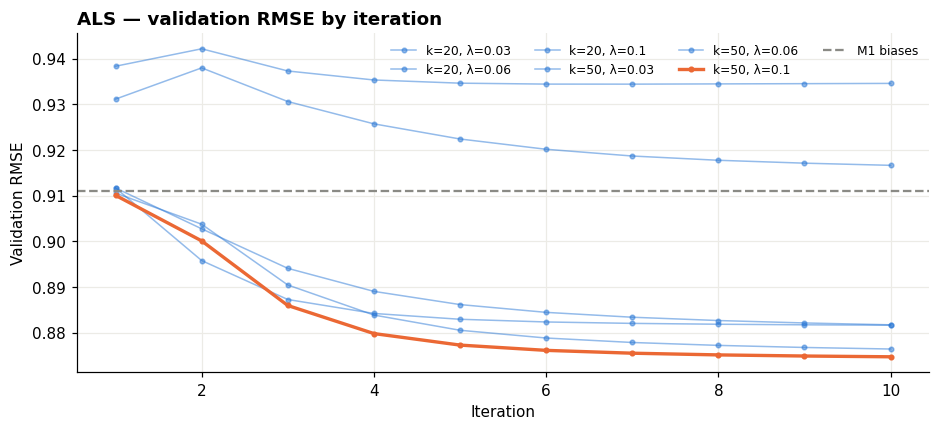

,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M3d ALS predicted rating,0.032,0.019,0.034,0.201,0.163,673.306,0.439


In [25]:
# ==============================
# 7.4.3 M3b — Biased matrix factorization with ALS (weighted-λ regularization)
# ==============================
def als_residual(E, k=50, lam=0.06, n_iter=10, seed=SEED, valid_fn=None):
    rng_ = np.random.default_rng(seed)
    n_u, n_i = E.shape
    P = 0.1 * rng_.standard_normal((n_u, k))
    Q = 0.1 * rng_.standard_normal((n_i, k))
    Ec, I_k, hist = E.tocsc(), np.eye(k), []
    for _ in range(n_iter):
        for u in range(n_u):                                       # update user factors
            s, e = E.indptr[u], E.indptr[u + 1]
            if e == s: P[u] = 0; continue
            Qi = Q[E.indices[s:e]]
            P[u] = np.linalg.solve(Qi.T @ Qi + lam * (e - s) * I_k, Qi.T @ E.data[s:e])
        for i in range(n_i):                                       # update movie factors
            s, e = Ec.indptr[i], Ec.indptr[i + 1]
            if e == s: Q[i] = 0; continue
            Pu = P[Ec.indices[s:e]]
            Q[i] = np.linalg.solve(Pu.T @ Pu + lam * (e - s) * I_k, Pu.T @ Ec.data[s:e])
        if valid_fn is not None:
            hist.append(valid_fn(P, Q))
    return P, Q, hist

valid_rmse = lambda P, Q: rmse(valid["rating"], np.clip(mf_predict(P, Q, m1_tune, valid), 1, 5))

grid_als, curves = [], {}
for k in [20, 50]:
    for lam in [0.03, 0.06, 0.1]:
        t0 = time.time()
        _, _, hist = als_residual(E_t, k, lam, n_iter=10, valid_fn=valid_rmse)
        curves[(k, lam)] = hist
        grid_als.append({"k": k, "lambda": lam, "best_iter": int(np.argmin(hist)) + 1,
                         "RMSE_valid": min(hist), "minutes": (time.time() - t0) / 60})
        print(f"k = {k:>3}, λ = {lam:<5} → best validation RMSE {min(hist):.4f} "
              f"(iteration {int(np.argmin(hist)) + 1}) — {(time.time() - t0) / 60:.1f} min")

grid_als = pd.DataFrame(grid_als)
best_als = grid_als.loc[grid_als["RMSE_valid"].idxmin()]
K_ALS, LAM_ALS, IT_ALS = int(best_als["k"]), float(best_als["lambda"]), int(best_als["best_iter"])

fig, ax = plt.subplots(figsize=(10, 4))
for (k, lam), h in curves.items():
    best = (k == K_ALS and lam == LAM_ALS)
    ax.plot(range(1, len(h) + 1), h, marker="o", ms=3, lw=2.2 if best else 1,
            color=ORANGE if best else BLUE, alpha=1 if best else 0.5, label=f"k={k}, λ={lam}")
ax.axhline(rmse(valid["rating"], np.clip(predict_biases(m1_tune, valid), 1, 5)), color=GREY, ls="--", label="M1 biases")
ax.set(title="ALS — validation RMSE by iteration", xlabel="Iteration", ylabel="Validation RMSE")
ax.legend(frameon=False, ncol=4, fontsize=8)
plt.show()

# Re-fit on the full training set and evaluate
P_als, Q_als, _ = als_residual(E_f, K_ALS, LAM_ALS, n_iter=IT_ALS)
eval_rating(mf_predict(P_als, Q_als, m1, test), f"M3b Biased MF — ALS (k = {K_ALS}, λ = {LAM_ALS})")

# M3d — ranking by ALS predicted rating ("will they like it?")
mu1, bu1, bi1 = m1
base_all = (mu1 + bu1.reindex(users_idx).fillna(0).values[:, None]
            + bi1.reindex(items_idx).fillna(0).values[None, :])
recs_m3d = topk_from_scores((base_all + P_als @ Q_als.T).astype(np.float32))
eval_topk(recs_m3d, "M3d ALS predicted rating")

In [26]:
# ==============================
# 7.4.4 M3c — PureSVD on the binary "rated" matrix (implicit feedback)
# ==============================
rel_valid = valid[valid["rating"] >= 4].groupby("user_id")["movie_id"].apply(set).to_dict()

def valid_ndcg(scores, seen_csr, rel_dict, k=K):
    s = np.array(np.broadcast_to(scores, seen_csr.shape), dtype=np.float32)
    r, c = seen_csr.nonzero(); s[r, c] = -np.inf
    top = np.argpartition(-s, k, axis=1)[:, :k]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(s, top, axis=1), axis=1), axis=1)
    return np.mean([(np.isin(items_idx[top[u_pos[u]]], list(rel)) * disc).sum() / disc[:min(len(rel), k)].sum()
                    for u, rel in rel_valid.items()])

Ub, sb, Vtb = sorted_svds(B_t, 200)
grid_ps = [{"k": "popularity (reference)",
            "NDCG@10_valid": valid_ndcg(np.asarray(B_t.sum(axis=0)).ravel(), B_t, rel_valid)}]
for k in [10, 20, 50, 100, 200]:
    grid_ps.append({"k": k, "NDCG@10_valid": valid_ndcg((Ub[:, :k] * sb[:k]) @ Vtb[:k], B_t, rel_valid)})
grid_ps = pd.DataFrame(grid_ps).set_index("k")
display(grid_ps.T.style.format("{:.4f}"))
K_PS = int(grid_ps.drop(index="popularity (reference)")["NDCG@10_valid"].astype(float).idxmax())
del Ub, sb, Vtb; gc.collect()

U_b, s_b, Vt_b = sorted_svds(B_f, K_PS)
recs_m3c = topk_from_scores(((U_b * s_b) @ Vt_b).astype(np.float32))
eval_topk(recs_m3c, f"M3c PureSVD implicit (k = {K_PS})")

show_results()

# Example: same user as in M2
u = users_idx[0]
print(f"\nUser {u}")
print("M2b (item-kNN co-watching):", title_of.loc[recs_m2b[u][:6]].tolist())
print("M3c (PureSVD implicit):    ", title_of.loc[recs_m3c[u][:6]].tolist())
print("M3d (ALS predicted rating):", title_of.loc[recs_m3d[u][:6]].tolist())

k,popularity (reference),10,20,50,100,200
NDCG@10_valid,0.0515,0.0691,0.0703,0.0713,0.0704,0.0637


Rating prediction (test):


,RMSE,MAE
model,,
M0 Global mean,1.1469,0.9440
M1 Bias model (no regularization),0.9210,0.7225
M1 Bias model (regularized),0.9211,0.7234
"M2a Item-kNN (k = 20, β = 25)",0.8748,0.6812
M3a Truncated SVD on residuals (k = 20),0.9030,0.7076
"M3b Biased MF — ALS (k = 50, λ = 0.1)",0.8852,0.6917


Top-10 recommendation (test):


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M0a Most rated,0.0795,0.0471,0.0904,38.9%,3.2%,"2,323",0.0%
M0b Best rated (Bayesian),0.0499,0.0277,0.0560,27.6%,2.4%,"1,369",0.1%
M1 Bias model (regularized),0.0293,0.0163,0.0272,19.1%,1.5%,869,21.4%
M2b Item-kNN co-watching,0.0930,0.0769,0.1133,49.9%,13.4%,"1,742",0.4%
M2c Item-kNN predicted rating,0.0358,0.0206,0.0394,22.0%,4.7%,830,23.4%
M3d ALS predicted rating,0.0320,0.0192,0.0341,20.1%,16.3%,673,43.9%
M3c PureSVD implicit (k = 50),0.0841,0.0808,0.1040,48.3%,28.6%,"1,242",2.0%



User 1
M2b (item-kNN co-watching): ['Star Wars: Episode V - The Empire Strikes Back (1980)', 'Raiders of the Lost Ark (1981)', 'Groundhog Day (1993)', 'Shawshank Redemption, The (1994)', 'Pulp Fiction (1994)', 'Toy Story (1995)']
M3c (PureSVD implicit):     ['Shawshank Redemption, The (1994)', 'Raiders of the Lost Ark (1981)', 'Star Wars: Episode V - The Empire Strikes Back (1980)', 'Amadeus (1984)', 'Silence of the Lambs, The (1991)', 'Toy Story (1995)']
M3d (ALS predicted rating): ['Godfather, The (1972)', 'Shawshank Redemption, The (1994)', 'Rear Window (1954)', 'Sunset Blvd. (a.k.a. Sunset Boulevard) (1950)', 'Paths of Glory (1957)', 'Third Man, The (1949)']


### 7.4 M3 — Results

**Tuning (validation)**
| Model | Search | Best | Validation |
|---|---|---|---|
| M3a Truncated SVD on residuals | k ∈ {5, 10, 20, 50, 100} | **k = 20** | RMSE 0.8930 (M1: 0.9111) |
| M3b Biased MF (ALS) | k ∈ {20, 50}, λ ∈ {0.03, 0.06, 0.1}, 10 iterations | **k = 50, λ = 0.1** | RMSE 0.8747 |
| M3c PureSVD (implicit) | k ∈ {10, 20, 50, 100, 200} | **k = 50** | NDCG@10 0.0713 (popularity: 0.0515) |

- **ALS needs strong regularization:** with λ = 0.03 it **overfits** (validation RMSE 0.917–0.934, worse than the bias model), while λ = 0.1 gives the best results for both k = 20 and k = 50.
- The best configuration is **at the edge of the grid** (largest λ) and the validation curve is **still decreasing at iteration 10**: ALS is likely **under-tuned**, and a larger λ and more iterations could improve it further.
- PureSVD peaks at **k = 50** factors; more factors (k = 200) start to fit noise.

**Rating prediction (test)**
| Model | RMSE | MAE | vs. M1 (RMSE) |
|---|---|---|---|
| M1 Bias model (regularized) | 0.9211 | 0.7234 | — |
| **M2a Item-kNN (k = 20, β = 25)** | **0.8748** | **0.6812** | **−5.0%** |
| M3a Truncated SVD on residuals (k = 20) | 0.9030 | 0.7076 | −2.0% |
| M3b Biased MF — ALS (k = 50, λ = 0.1) | 0.8852 | 0.6917 | −3.9% |

**Top-10 recommendation (test)**
| Model | Precision@10 | Recall@10 | NDCG@10 | Hit Rate@10 | Coverage | Avg. popularity | Long-tail share |
|---|---|---|---|---|---|---|---|
| M0a Most rated | 0.0795 | 0.0471 | 0.0904 | 38.9% | 3.2% | 2,323 | 0.0% |
| **M2b Item-kNN co-watching** | **0.0930** | 0.0769 | **0.1133** | **49.9%** | 13.4% | 1,742 | 0.4% |
| **M3c PureSVD implicit (k = 50)** | 0.0841 | **0.0808** | 0.1040 | 48.3% | **28.6%** | 1,242 | 2.0% |
| M3d ALS predicted rating | 0.0320 | 0.0192 | 0.0341 | 20.1% | 16.3% | 673 | 43.9% |

**1. Matrix factorization improves rating prediction, but item-kNN remains best**
- ALS reduces RMSE by **3.9%** vs. the bias model, and the simple truncated SVD by 2.0%: latent factors capture part of each user's taste.
- **Item-kNN (M2a) is still the best rating model** (0.875 vs. 0.885). Possible reasons: ALS is under-tuned (see above), and with bulk-rating sessions (section 5.4), the **most similar movies a user rated** are a very direct signal for the next ones.
- The truncated SVD treats unrated movies as "average", which biases its factors; learning only from **observed** ratings (ALS) works better.

**2. PureSVD is a strong and more diverse ranker**
- On "will they watch it?", PureSVD is **close to item-kNN**: NDCG@10 0.104 vs. 0.113 (−8%), with the **best Recall@10** of all models (0.081).
- It is **much more diverse**: **coverage 28.6%** (2× item-kNN, 9× popularity) and less popular recommendations on average (1,242 vs. 1,742 ratings).
- → Item-kNN and PureSVD offer a **trade-off between accuracy and diversity**.

**3. Ranking by predicted rating fails again**
- **M3d** (ALS predicted rating) has the **lowest accuracy** among personalized rankers (NDCG@10 0.034) and the **highest long-tail share (43.9%)**: it recommends acclaimed but rarely watched classics (*The Godfather*, *Rear Window*, *Sunset Blvd.*).
- This confirms the pattern seen with M1 and M2c: predicted ratings answer *"how much would they like it?"*, but offline top-K rewards *"will they watch it?"*.

**4. Qualitative example (user 1)**
- **M2b (item-kNN):** *The Empire Strikes Back*, *Raiders of the Lost Ark*, *Groundhog Day*, *Shawshank*.
- **M3c (PureSVD):** *Shawshank*, *Raiders of the Lost Ark*, *The Empire Strikes Back* → very similar popular classics.
- **M3d (ALS rating):** *The Godfather*, *Shawshank*, *Rear Window*, *Sunset Blvd.* → older, critically acclaimed films.

**Conclusions**
- **Best rating model:** M2a item-kNN (RMSE 0.875), followed by ALS (0.885).
- **Best ranking models:** M2b item-kNN co-watching (highest NDCG@10 and precision) and **M3c PureSVD** (highest recall and **2× coverage**).
- The **implicit signal ("what users watch")** is the key to ranking, while **explicit ratings** are the key to rating prediction: the two tasks require different models.

### 7.5 M4 — User Clustering (Unsupervised, Taste Segments)

**Idea:** group users with similar viewing behavior into **taste segments**, and recommend to each user what is most watched **within their segment** (*"people like you watched…"*).

**User representation:** the latent user factors from **PureSVD (M3c, k = 50)**, L2-normalized, so that K-means groups users by the **direction** of their tastes rather than by how many movies they rated.

**Models**
| Model | Recommendation | Rating prediction |
|---|---|---|
| **M4a — Clusters for recommendation** | Rank movies by the **share of segment members who watched them** | Bias model + **shrunk average residual** of the segment on the movie |
| **M4b — Segmentation for business insight** | Same, with a small number of segments (K = 8) | — |

**Choosing K (number of segments)**
- For recommendation, K is tuned on **validation NDCG@10** (and the silhouette score is reported as a measure of cluster separation).
- For business use, a **small K** is preferred so segments can be described and named, even if accuracy is lower.

**Learning paradigm:** **unsupervised** — K-means discovers groups without any labels.

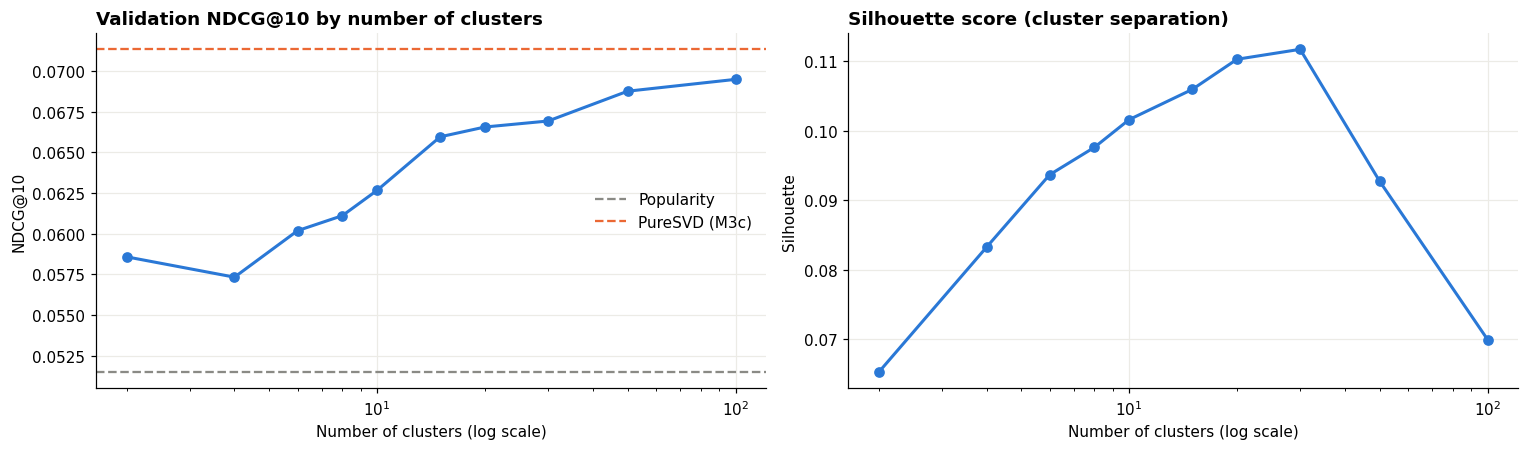

clusters,2,4,6,8,10,15,20,30,50,100
NDCG@10_valid,0.0586,0.0573,0.0602,0.0611,0.0627,0.0660,0.0666,0.0669,0.0688,0.0695
silhouette,0.0652,0.0832,0.0937,0.0976,0.1016,0.1059,0.1103,0.1117,0.0927,0.0700


Best number of clusters for recommendation: K = 100


In [27]:
# ==============================
# 7.5.1 User embeddings (PureSVD factors, L2-normalized)
# ==============================
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

Ub_t, sb_t, _ = sorted_svds(B_t, K_PS)                # tuning embeddings (train → validation)
emb_t = normalize(Ub_t * sb_t)
emb_f = normalize(U_b * s_b)                           # final embeddings (train_full, from M3c)

def indicator(labels, n_clusters):
    """Sparse clusters × users matrix (1 if the user belongs to the cluster)."""
    return sparse.csr_matrix((np.ones(len(labels)), (labels, np.arange(len(labels)))),
                             shape=(n_clusters, len(labels)))

def cluster_watch_scores(labels, n_clusters, Bmat):
    """Users × movies: share of the user's cluster members who rated each movie."""
    C = indicator(labels, n_clusters)
    share = np.asarray((C @ Bmat).todense()) / np.asarray(C.sum(axis=1))
    return share[labels].astype(np.float32)

# ==============================
# 7.5.2 Choose the number of clusters on validation
# ==============================
sample_idx = rng.choice(len(users_idx), 3000, replace=False)
grid_km, labels_t = [], {}
for nc in [2, 4, 6, 8, 10, 15, 20, 30, 50, 100]:
    km = KMeans(n_clusters=nc, n_init=10, random_state=SEED).fit(emb_t)
    labels_t[nc] = km.labels_
    grid_km.append({"clusters": nc,
                    "NDCG@10_valid": valid_ndcg(cluster_watch_scores(km.labels_, nc, B_t), B_t, rel_valid),
                    "silhouette": silhouette_score(emb_t[sample_idx], km.labels_[sample_idx])})
grid_km = pd.DataFrame(grid_km).set_index("clusters")
K_REC = int(grid_km["NDCG@10_valid"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(grid_km.index, grid_km["NDCG@10_valid"], color=BLUE, lw=2, marker="o")
axes[0].axhline(grid_ps.loc["popularity (reference)", "NDCG@10_valid"], color=GREY, ls="--", label="Popularity")
axes[0].axhline(grid_ps["NDCG@10_valid"].drop("popularity (reference)").max(), color=ORANGE, ls="--",
                label="PureSVD (M3c)")
axes[0].set(title="Validation NDCG@10 by number of clusters", xlabel="Number of clusters (log scale)",
            ylabel="NDCG@10", xscale="log")
axes[0].legend(frameon=False)
axes[1].plot(grid_km.index, grid_km["silhouette"], color=BLUE, lw=2, marker="o")
axes[1].set(title="Silhouette score (cluster separation)", xlabel="Number of clusters (log scale)",
            ylabel="Silhouette", xscale="log")
plt.tight_layout()
plt.show()

display(grid_km.T.style.format("{:.4f}"))
print(f"Best number of clusters for recommendation: K = {K_REC}")

In [28]:
# ==============================
# 7.5.3 Cluster-based rating prediction (shrunk segment residuals)
# ==============================
def cluster_rating_pred(labels, nc, Emat, Bmat, base_model, pairs, beta):
    C = indicator(labels, nc)
    dev = np.asarray((C @ Emat).todense()) / (np.asarray((C @ Bmat).todense()) + beta)
    out = predict_biases(base_model, pairs).astype(np.float64)
    u = u_pos[pairs["user_id"]].values
    i = i_pos.reindex(pairs["movie_id"]).values
    ok = ~np.isnan(i)
    out[ok] += dev[labels[u[ok]], i[ok].astype(int)]
    return out

beta_grid = pd.Series({b: rmse(valid["rating"], np.clip(cluster_rating_pred(
    labels_t[K_REC], K_REC, E_t, B_t, m1_tune, valid, b), 1, 5)) for b in [5, 10, 25, 50, 100]},
    name="RMSE_valid")
BETA_CL = int(beta_grid.idxmin())
print(f"Cluster rating model — validation RMSE by shrinkage β (K = {K_REC}):")
display(beta_grid.to_frame().T.style.format("{:.4f}"))

# ==============================
# 7.5.4 Final models on the full training set
# ==============================
K_SEG = 8
km_rec = KMeans(n_clusters=K_REC, n_init=10, random_state=SEED).fit(emb_f)
km_seg = KMeans(n_clusters=K_SEG, n_init=10, random_state=SEED).fit(emb_f)

eval_rating(cluster_rating_pred(km_rec.labels_, K_REC, E_f, B_f, m1, test, BETA_CL),
            f"M4a User clusters (K = {K_REC}, β = {BETA_CL})")

recs_m4a = topk_from_scores(cluster_watch_scores(km_rec.labels_, K_REC, B_f))
eval_topk(recs_m4a, f"M4a User clusters (K = {K_REC})")
recs_m4b = topk_from_scores(cluster_watch_scores(km_seg.labels_, K_SEG, B_f))
eval_topk(recs_m4b, f"M4b Taste segments (K = {K_SEG})")

show_results()

Cluster rating model — validation RMSE by shrinkage β (K = 100):


,5,10,25,50,100
RMSE_valid,0.9186,0.9130,0.9099,0.9095,0.9098


Rating prediction (test):


,RMSE,MAE
model,,
M0 Global mean,1.1469,0.9440
M1 Bias model (no regularization),0.9210,0.7225
M1 Bias model (regularized),0.9211,0.7234
"M2a Item-kNN (k = 20, β = 25)",0.8748,0.6812
M3a Truncated SVD on residuals (k = 20),0.9030,0.7076
"M3b Biased MF — ALS (k = 50, λ = 0.1)",0.8852,0.6917
"M4a User clusters (K = 100, β = 50)",0.9191,0.7217


Top-10 recommendation (test):


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M0a Most rated,0.0795,0.0471,0.0904,38.9%,3.2%,"2,323",0.0%
M0b Best rated (Bayesian),0.0499,0.0277,0.0560,27.6%,2.4%,"1,369",0.1%
M1 Bias model (regularized),0.0293,0.0163,0.0272,19.1%,1.5%,869,21.4%
M2b Item-kNN co-watching,0.0930,0.0769,0.1133,49.9%,13.4%,"1,742",0.4%
M2c Item-kNN predicted rating,0.0358,0.0206,0.0394,22.0%,4.7%,830,23.4%
M3d ALS predicted rating,0.0320,0.0192,0.0341,20.1%,16.3%,673,43.9%
M3c PureSVD implicit (k = 50),0.0841,0.0808,0.1040,48.3%,28.6%,"1,242",2.0%
M4a User clusters (K = 100),0.0819,0.0706,0.0998,43.0%,26.0%,"1,322",3.1%
M4b Taste segments (K = 8),0.0764,0.0589,0.0916,40.5%,10.6%,"1,678",0.0%


,users,share_users,share_female,share_under_25,share_45_plus,median_train_ratings,avg_rating
segment,,,,,,,
0,494,8.2%,24.5%,30.0%,17.0%,38,3.56
1,909,15.0%,29.6%,8.7%,42.8%,80,3.94
2,436,7.2%,27.5%,25.7%,26.6%,29,3.59
3,480,7.9%,11.7%,18.1%,23.1%,84,3.73
4,875,14.5%,18.4%,18.3%,22.3%,65,3.79
5,859,14.2%,36.0%,23.1%,22.7%,66,3.81
6,976,16.2%,52.4%,23.6%,22.8%,82,3.71
7,"1,011",16.7%,16.0%,30.8%,11.2%,243,3.55


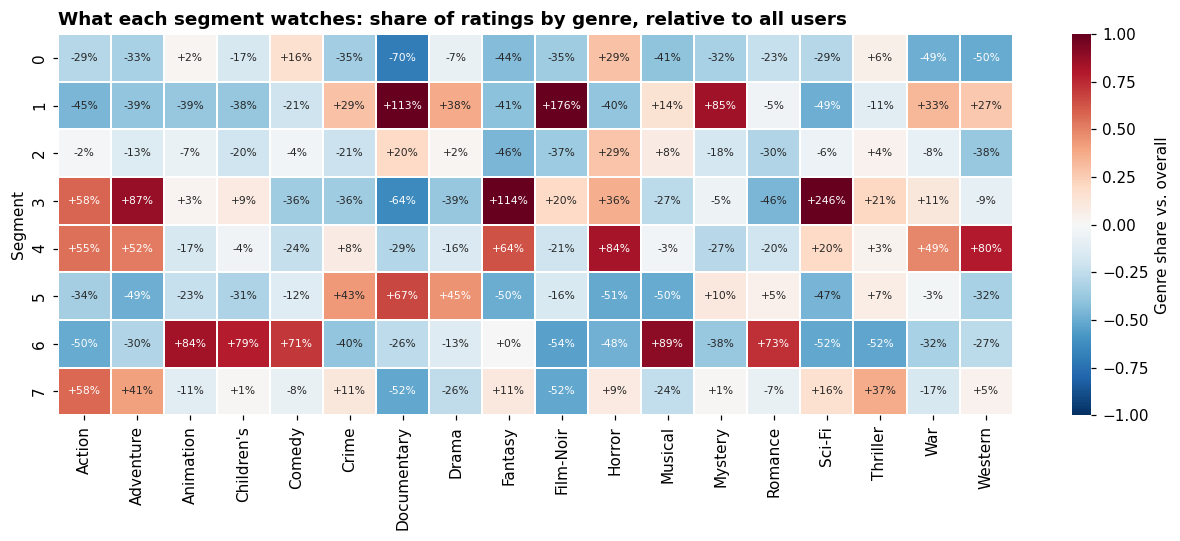


Segment 0 (8% of users) — distinctive movies:
   54 (1998) (×5.3) | General's Daughter, The (1999) (×4.5) | Cruel Intentions (1999) (×4.4) | Bone Collector, The (1999) (×4.2) | Doctor Dolittle (1998) (×3.9) | Big Daddy (1999) (×3.9)

Segment 1 (15% of users) — distinctive movies:
   Who's Afraid of Virginia Woolf? (1966) (×4.1) | Thin Man, The (1934) (×4.1) | Third Man, The (1949) (×4.0) | Nashville (1975) (×4.0) | Last Picture Show, The (1971) (×3.9) | Klute (1971) (×3.9)

Segment 2 (7% of users) — distinctive movies:
   Shanghai Noon (2000) (×3.1) | Final Destination (2000) (×2.9) | Frequency (2000) (×2.7) | U-571 (2000) (×2.7) | Nurse Betty (2000) (×2.6) | Pitch Black (2000) (×2.5)

Segment 3 (8% of users) — distinctive movies:
   Forbidden Planet (1956) (×5.8) | Soylent Green (1973) (×5.1) | Nineteen Eighty-Four (1984) (×4.7) | Day the Earth Stood Still, The (1951) (×4.7) | Godzilla (Gojira) (1954) (×4.6) | Them! (1954) (×4.3)

Segment 4 (14% of users) — distinctive movies:
   Gun

In [29]:
# ==============================
# 7.5.5 Segment profiles (K = 8): size, demographics, activity
# ==============================
seg_lab = pd.Series(km_seg.labels_, index=users_idx, name="segment")
ud = users.set_index("user_id").reindex(users_idx)
n_train = train_full.groupby("user_id").size().reindex(users_idx)
avg_r = train_full.groupby("user_id")["rating"].mean().reindex(users_idx)

profile = pd.DataFrame({
    "users": seg_lab.value_counts().sort_index(),
    "share_users": seg_lab.value_counts(normalize=True).sort_index(),
    "share_female": (ud["gender"] == "F").groupby(seg_lab).mean(),
    "share_under_25": ud["age"].isin([1, 18]).groupby(seg_lab).mean(),
    "share_45_plus": ud["age"].isin([45, 50, 56]).groupby(seg_lab).mean(),
    "median_train_ratings": n_train.groupby(seg_lab).median(),
    "avg_rating": avg_r.groupby(seg_lab).mean(),
})
display(profile.style.format({"users": "{:,}", "share_users": "{:.1%}", "share_female": "{:.1%}",
                              "share_under_25": "{:.1%}", "share_45_plus": "{:.1%}",
                              "median_train_ratings": "{:.0f}", "avg_rating": "{:.2f}"}))

# ==============================
# 7.5.6 What each segment watches: genre share of ratings vs. overall (lift)
# ==============================
rt = train_full[["user_id", "movie_id", "rating"]].merge(movies[["movie_id"] + g_cols], on="movie_id")
genre_share_user = rt.groupby("user_id")[g_cols].mean().reindex(users_idx)
genre_share_user.columns = GENRES
watch_lift = genre_share_user.groupby(seg_lab).mean() / genre_share_user.mean() - 1

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(watch_lift, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt="+.0%",
            annot_kws={"size": 7}, linewidths=0.3, linecolor="white", ax=ax,
            cbar_kws={"label": "Genre share vs. overall"})
ax.set(title="What each segment watches: share of ratings by genre, relative to all users",
       xlabel="", ylabel="Segment")
plt.show()

# ==============================
# 7.5.7 Most distinctive movies per segment (watched much more than average)
# ==============================
C_seg = indicator(km_seg.labels_, K_SEG)
seg_share = np.asarray((C_seg @ B_f).todense()) / np.asarray(C_seg.sum(axis=1))
overall_share = np.asarray(B_f.mean(axis=0)).ravel()
for s in range(K_SEG):
    lift = np.where(seg_share[s] >= 0.15, seg_share[s] / (overall_share + 1e-9), 0)
    top = np.argsort(-lift)[:6]
    print(f"\nSegment {s} ({profile.loc[s, 'share_users']:.0%} of users) — distinctive movies:")
    print("   " + " | ".join(f"{title_of.loc[items_idx[j]]} (×{lift[j]:.1f})" for j in top))

### 7.5 M4 — Results

**Choosing the number of clusters (validation)**
| Clusters | 2 | 4 | 8 | 15 | 30 | 50 | 100 |
|---|---|---|---|---|---|---|---|
| NDCG@10 (valid) | 0.0586 | 0.0573 | 0.0611 | 0.0658 | 0.0669 | 0.0688 | **0.0694** |
| Silhouette | 0.065 | 0.083 | 0.098 | 0.106 | **0.112** | 0.093 | 0.070 |

- **More clusters → better recommendations:** NDCG increases steadily and is still growing at K = 100 (edge of the grid), approaching PureSVD (0.0713). With many clusters, each segment becomes a small group of very similar users, i.e., the model converges toward neighborhood / latent-factor methods.
- **Silhouette is low for every K (≤ 0.11)** and peaks at K = 30: users do **not** form clearly separated groups. Tastes are a **continuum**, and segments are a useful simplification rather than natural "types" of users.

**Rating prediction (test)**
| Model | RMSE | MAE | vs. M1 (RMSE) |
|---|---|---|---|
| M1 Bias model | 0.9211 | 0.7234 | — |
| M2a Item-kNN | **0.8748** | **0.6812** | −5.0% |
| M4a User clusters (K = 100, β = 50) | 0.9191 | 0.7217 | −0.2% |

- Segment-level adjustments barely improve over biases: a segment's average taste is too coarse to predict an individual rating.

**Top-10 recommendation (test)**
| Model | Precision@10 | Recall@10 | NDCG@10 | Hit Rate@10 | Coverage | Avg. popularity |
|---|---|---|---|---|---|---|
| M0a Most rated | 0.0795 | 0.0471 | 0.0904 | 38.9% | 3.2% | 2,323 |
| M2b Item-kNN co-watching | **0.0930** | 0.0769 | **0.1133** | **49.9%** | 13.4% | 1,742 |
| M3c PureSVD implicit | 0.0841 | **0.0808** | 0.1040 | 48.3% | **28.6%** | 1,242 |
| M4a User clusters (K = 100) | 0.0816 | 0.0702 | 0.0997 | 42.8% | 26.0% | 1,323 |
| M4b Taste segments (K = 8) | 0.0763 | 0.0589 | 0.0915 | 40.5% | 10.5% | 1,679 |

- **M4a (K = 100)** gets close to PureSVD (NDCG −4%) with similar diversity (coverage 26%): *"people like you watched…"* is a reasonable, explainable recommender.
- **M4b (K = 8)** matches popularity in accuracy (0.0915 vs. 0.0904) but recommends **3× more distinct movies** (coverage 10.5% vs. 3.2%): even 8 broad segments personalize the catalog without losing accuracy.

**Taste segments (K = 8)**
| # | Segment | Users | Who | Watches more | Distinctive movies |
|---|---|---|---|---|---|
| 0 | **Late-90s releases, light users** | 8.2% | 30% under 25; median 38 ratings | Horror +29%, Comedy +16%; Documentary −70% | *54*, *The General's Daughter*, *Cruel Intentions*, *The Bone Collector* |
| 1 | **Classic cinema lovers** | 15.0% | **43% aged 45+**; highest avg. rating (**3.94**) | **Film-Noir +176%**, Documentary +113%, Mystery +85%, Drama +38% | *Who's Afraid of Virginia Woolf?*, *The Thin Man*, *The Third Man*, *Nashville* |
| 2 | **New releases (2000)** | 7.2% | Lowest activity (median 29 ratings) | Horror +29%, Documentary +20% | *Shanghai Noon*, *Final Destination*, *Frequency*, *U-571* |
| 3 | **Sci-fi fans** | 7.9% | **88% male** | **Sci-Fi +246%**, Fantasy +114%, Adventure +87%, Action +58% | *Forbidden Planet*, *Soylent Green*, *Nineteen Eighty-Four*, *The Day the Earth Stood Still* |
| 4 | **Classic action, western & war** | 14.5% | 82% male | Horror +84%, **Western +80%**, Fantasy +64%, Action +55%, War +49% | *The Guns of Navarone*, *A Fistful of Dollars*, *The Dirty Dozen*, *The Good, the Bad and the Ugly* |
| 5 | **Prestige drama (90s)** | 14.2% | 36% female | Documentary +67%, Drama +45%, Crime +43% | *Dead Man Walking*, *Secrets & Lies*, *The Insider*, *Good Will Hunting* |
| 6 | **Romantic comedy & family** | 16.2% | **52% female** (the only majority-female segment) | **Musical +89%**, Animation +84%, Children's +79%, Romance +73%, Comedy +71% | *Emma*, *Muriel's Wedding*, *While You Were Sleeping*, *The Truth About Cats & Dogs* |
| 7 | **90s action blockbusters, heavy users** | 16.7% | Heaviest users (**median 243 ratings**), 31% under 25; lowest avg. rating (3.55) | Action +58%, Adventure +41%, Thriller +37% | *Eraser*, *The Jackal*, *Mortal Kombat*, *Dante's Peak*, *U.S. Marshals* |

**Reading the segments**
- Segments match the **taste families** found in the EDA (5.5): blockbuster/spectacle (3, 4, 7), family/romance (6), dark/classic (1), serious drama (5).
- Two segments are defined more by **timing** than by genre (0 and 2: users who joined and rated mainly the releases of the moment).
- Demographics differ between segments (e.g., sci-fi fans 88% male; rom-com/family 52% female; classic cinema 43% aged 45+), but every segment mixes all groups: **taste, not demographics, defines the segments**.
- Segment 7 shows that **heavy users** have a distinct, stricter, action-oriented profile, consistent with section 5.2.

**Conclusions**
- **Clustering is the most interpretable model:** segments can be named and used by marketing, content acquisition and editorial teams (e.g., themed home rows such as *"Classic cinema"* or *"Sci-fi picks"*).
- For **recommendation**, many fine-grained clusters (K = 100) approach PureSVD; few broad segments (K = 8) trade accuracy for interpretability while still being 3× more diverse than popularity.
- For **rating prediction**, clusters are too coarse (RMSE −0.2% vs. biases).
- The low silhouette scores show that tastes are **continuous**: segments are a business tool, while latent factors and neighbors are better for personalization.

### 7.6 M5 — Supervised Rating Model (LightGBM, Stacking)

**Idea:** learn a **supervised** mapping from engineered features to the rating, combining content information (genres, year, popularity, demographics) with the predictions of the unsupervised models (M1–M4).

**Leakage-free stacking (blending)**
1. **Level-1 models** (biases, item-kNN, ALS, SVD, clusters, PureSVD, genre affinities) are fitted on the **tuning train set** and produce features for the **validation** ratings.
2. **LightGBM is trained on the validation ratings** (80k), whose targets were never seen by the level-1 models. 20% of validation users are held out for **early stopping**.
3. For the final evaluation, level-1 models are **re-fitted on the full training set** and produce features for the **test** ratings; LightGBM predicts the test ratings.

This is the classic **blending** approach used by the Netflix Prize winners.

**Features**
| Group | Features |
|---|---|
| **Biases** | Bias-model prediction, user bias, movie bias |
| **Collaborative (unsupervised models)** | Predictions of item-kNN (M2a), ALS (M3b), truncated SVD (M3a), user clusters (M4a), and their deviation from the bias model; PureSVD "watch score" (M3c) |
| **User** | Number of ratings, average rating, rating std, gender, age group, occupation |
| **Movie** | Number of ratings, average rating, release year, 18 genre indicators |
| **User × movie (content)** | User's **affinity for the movie's genres** (average and maximum, centered and shrunk) |

**Variants**
- **M5a — Linear blend (Ridge):** only the level-1 predictions → how much does a simple combination add?
- **M5b — Content LightGBM:** biases + content + demographics + genre affinities, **no collaborative predictions** → how far can a content-based supervised model go?
- **M5c — Full LightGBM:** all features.

**Learning paradigm:** **supervised** — the model learns from labeled examples (features → observed rating).

In [30]:
# ==============================
# 7.6.1 Feature engineering helpers
# ==============================
import gc
import lightgbm as lgb
from sklearn.linear_model import Ridge

mi = movies.set_index("movie_id")
ui = users.set_index("user_id")

def genre_affinity(df, base_model, shrink=5):
    """Users × genres: average residual (rating − bias prediction) on each genre, shrunk toward 0."""
    e = df["rating"].values - predict_biases(base_model, df)
    G = mi.loc[df["movie_id"], g_cols].values.astype(np.float32)
    num = pd.DataFrame(G * e[:, None], columns=GENRES).groupby(df["user_id"].values).sum()
    cnt = pd.DataFrame(G, columns=GENRES).groupby(df["user_id"].values).sum()
    return (num / (cnt + shrink)).reindex(users_idx).fillna(0)

def build_features(df_fit, pairs, L):
    """Feature table for (user, movie) pairs, using level-1 models L fitted on df_fit."""
    base = L["base"]
    _, bu, bi = base
    u = u_pos[pairs["user_id"]].values
    i = i_pos.reindex(pairs["movie_id"]).values
    ok = ~np.isnan(i)
    ii = np.where(ok, i, 0).astype(int)

    X = pd.DataFrame(index=np.arange(len(pairs)))
    # Biases
    X["pred_bias"] = predict_biases(base, pairs)
    X["b_u"] = pairs["user_id"].map(bu).fillna(0).values
    X["b_i"] = pairs["movie_id"].map(bi).fillna(0).values
    # Collaborative predictions (unsupervised models)
    X["pred_knn"] = knn_predict(L["S_res"], base, df_fit, pairs, K_NN)
    X["pred_als"] = mf_predict(L["P_als"], L["Q_als"], base, pairs)
    X["pred_svd"] = mf_predict(L["P_svd"], L["Q_svd"], base, pairs)
    X["pred_cluster"] = cluster_rating_pred(L["lab_rec"], K_REC, L["E"], L["B"], base, pairs, BETA_CL)
    for c in ["knn", "als", "svd", "cluster"]:
        X[f"{c}_minus_bias"] = X[f"pred_{c}"] - X["pred_bias"]
    X["watch_score"] = np.where(ok, np.einsum("ij,ij->i", L["P_ps"][u], L["Q_ps"][ii]), 0)
    # User
    us = df_fit.groupby("user_id")["rating"].agg(["size", "mean", "std"])
    X["u_n_log"] = np.log1p(pairs["user_id"].map(us["size"]).values)
    X["u_mean"] = pairs["user_id"].map(us["mean"]).values
    X["u_std"] = pairs["user_id"].map(us["std"]).values
    X["gender_f"] = (pairs["user_id"].map(ui["gender"]) == "F").astype(int).values
    X["age"] = pairs["user_id"].map(ui["age"]).values
    X["occupation"] = pairs["user_id"].map(ui["occupation"]).values
    # Movie
    ms = df_fit.groupby("movie_id")["rating"].agg(["size", "mean"])
    X["m_n_log"] = np.log1p(pairs["movie_id"].map(ms["size"]).fillna(0).values)
    X["m_mean"] = pairs["movie_id"].map(ms["mean"]).values
    X["m_year"] = pairs["movie_id"].map(mi["year"]).astype(float).values
    G = mi.loc[pairs["movie_id"], g_cols].values.astype(np.float32)
    for j, g in enumerate(GENRES):
        X[f"g_{g}"] = G[:, j]
    # User × movie content affinity
    A = L["affinity"].values[u]
    X["genre_affinity_mean"] = (A * G).sum(axis=1) / np.maximum(G.sum(axis=1), 1)
    X["genre_affinity_max"] = np.where(G > 0, A, -9).max(axis=1)
    return X

COLLAB_FEATS = ["pred_knn", "pred_als", "pred_svd", "pred_cluster", "knn_minus_bias", "als_minus_bias",
                "svd_minus_bias", "cluster_minus_bias", "watch_score"]
LEVEL1_PREDS = ["pred_bias", "pred_knn", "pred_als", "pred_svd", "pred_cluster"]
CAT_FEATS = ["occupation"]

In [31]:
# ==============================
# 7.6.2 Level-1 models on the tuning train set → features for VALIDATION
# ==============================
t0 = time.time()
S_res_t = item_similarities(train, m1_tune, BETA)[0]
P_als_t, Q_als_t, _ = als_residual(E_t, K_ALS, LAM_ALS, n_iter=IT_ALS)
U_st, s_st, Vt_st = sorted_svds(E_t, K_SVD_BEST)
U_pt, s_pt, Vt_pt = sorted_svds(B_t, K_PS)

L_tune = {
    "base": m1_tune, "S_res": S_res_t, "P_als": P_als_t, "Q_als": Q_als_t,
    "P_svd": U_st * s_st, "Q_svd": Vt_st.T, "P_ps": U_pt * s_pt, "Q_ps": Vt_pt.T,
    "lab_rec": labels_t[K_REC], "E": E_t, "B": B_t,
    "affinity": genre_affinity(train, m1_tune),
}
X_valid = build_features(train, valid, L_tune)
y_valid = valid["rating"].values
del L_tune, S_res_t; gc.collect()
print(f"Validation features: {X_valid.shape[0]:,} rows × {X_valid.shape[1]} features — {(time.time() - t0) / 60:.1f} min")

Validation features: 80,127 rows × 41 features — 0.3 min


In [32]:
# ==============================
# 7.6.3 Level-1 models on the full training set → features for TEST
# ==============================
t0 = time.time()
S_res_f = item_similarities(train_full, m1, BETA)[0]
L_final = {
    "base": m1, "S_res": S_res_f, "P_als": P_als, "Q_als": Q_als,
    "P_svd": U_f * s_f, "Q_svd": Vt_f.T, "P_ps": U_b * s_b, "Q_ps": Vt_b.T,
    "lab_rec": km_rec.labels_, "E": E_f, "B": B_f,
    "affinity": genre_affinity(train_full, m1),
}
X_test = build_features(train_full, test, L_final)
del L_final, S_res_f; gc.collect()
print(f"Test features: {X_test.shape[0]:,} rows × {X_test.shape[1]} features — {(time.time() - t0) / 60:.1f} min")

# Sanity check: level-1 predictions in the feature table must match the ones evaluated before
print(f"Check — RMSE of pred_knn on test: {rmse(test['rating'], np.clip(X_test['pred_knn'], 1, 5)):.4f} (M2a: 0.8748)")

Test features: 200,016 rows × 41 features — 0.1 min
Check — RMSE of pred_knn on test: 0.8748 (M2a: 0.8748)


In [33]:
# ==============================
# 7.6.4 Train on validation ratings (early stopping on 20% of validation users)
# ==============================
val_users = valid["user_id"].unique()
es_users = rng.choice(val_users, size=int(0.2 * len(val_users)), replace=False)
is_es = valid["user_id"].isin(es_users).values

params_lgb = {"objective": "regression", "metric": "rmse", "learning_rate": 0.03, "num_leaves": 31,
              "min_data_in_leaf": 100, "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
              "lambda_l2": 1.0, "verbose": -1, "seed": SEED}

def train_lgb(feats, name):
    cats = [c for c in CAT_FEATS if c in feats]
    dtr = lgb.Dataset(X_valid.loc[~is_es, feats], y_valid[~is_es], categorical_feature=cats)
    dva = lgb.Dataset(X_valid.loc[is_es, feats], y_valid[is_es], categorical_feature=cats, reference=dtr)
    model = lgb.train(params_lgb, dtr, num_boost_round=3000, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
    print(f"{name}: best iteration {model.best_iteration}, early-stopping RMSE {model.best_score['valid_0']['rmse']:.4f}")
    return model

ALL_FEATS = X_valid.columns.tolist()
CONTENT_FEATS = [f for f in ALL_FEATS if f not in COLLAB_FEATS]

# M5a — linear blend of level-1 predictions
ridge = Ridge(alpha=1.0).fit(X_valid.loc[~is_es, LEVEL1_PREDS], y_valid[~is_es])
print("Ridge blend weights:", dict(zip(LEVEL1_PREDS, np.round(ridge.coef_, 3))), "| intercept", round(ridge.intercept_, 3))
eval_rating(ridge.predict(X_test[LEVEL1_PREDS]), "M5a Linear blend (Ridge)")

# M5b — content LightGBM (no collaborative predictions)
lgb_content = train_lgb(CONTENT_FEATS, "M5b Content LightGBM")
eval_rating(lgb_content.predict(X_test[CONTENT_FEATS], num_iteration=lgb_content.best_iteration),
            "M5b LightGBM — content + biases (no CF)")

# M5c — full LightGBM
lgb_full = train_lgb(ALL_FEATS, "M5c Full LightGBM")
pred_m5c = lgb_full.predict(X_test[ALL_FEATS], num_iteration=lgb_full.best_iteration)
eval_rating(pred_m5c, "M5c LightGBM — all features (stacking)")

show_results()

Ridge blend weights: {'pred_bias': np.float64(-1.168), 'pred_knn': np.float64(0.583), 'pred_als': np.float64(0.817), 'pred_svd': np.float64(0.352), 'pred_cluster': np.float64(0.404)} | intercept -0.04
M5b Content LightGBM: best iteration 183, early-stopping RMSE 0.8994
M5c Full LightGBM: best iteration 218, early-stopping RMSE 0.8450
Rating prediction (test):


,RMSE,MAE
model,,
M0 Global mean,1.1469,0.9440
M1 Bias model (no regularization),0.9210,0.7225
M1 Bias model (regularized),0.9211,0.7234
"M2a Item-kNN (k = 20, β = 25)",0.8748,0.6812
M3a Truncated SVD on residuals (k = 20),0.9030,0.7076
"M3b Biased MF — ALS (k = 50, λ = 0.1)",0.8852,0.6917
"M4a User clusters (K = 100, β = 50)",0.9191,0.7217
M5a Linear blend (Ridge),0.8623,0.6745
M5b LightGBM — content + biases (no CF),0.9021,0.7115


Top-10 recommendation (test):


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M0a Most rated,0.0795,0.0471,0.0904,38.9%,3.2%,"2,323",0.0%
M0b Best rated (Bayesian),0.0499,0.0277,0.0560,27.6%,2.4%,"1,369",0.1%
M1 Bias model (regularized),0.0293,0.0163,0.0272,19.1%,1.5%,869,21.4%
M2b Item-kNN co-watching,0.0930,0.0769,0.1133,49.9%,13.4%,"1,742",0.4%
M2c Item-kNN predicted rating,0.0358,0.0206,0.0394,22.0%,4.7%,830,23.4%
M3d ALS predicted rating,0.0320,0.0192,0.0341,20.1%,16.3%,673,43.9%
M3c PureSVD implicit (k = 50),0.0841,0.0808,0.1040,48.3%,28.6%,"1,242",2.0%
M4a User clusters (K = 100),0.0819,0.0706,0.0998,43.0%,26.0%,"1,322",3.1%
M4b Taste segments (K = 8),0.0764,0.0589,0.0916,40.5%,10.6%,"1,678",0.0%


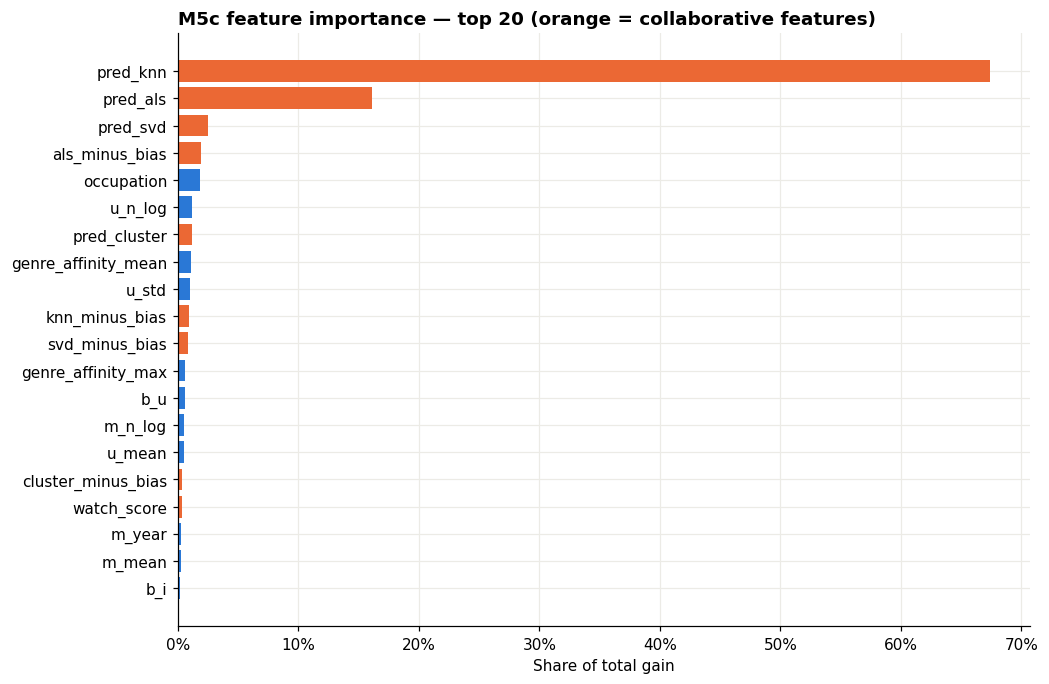

,share_of_gain
"Collaborative (kNN, ALS, SVD, clusters, PureSVD)",91.5%
User profile & demographics,4.7%
User × genre affinity,1.6%
"Movie (popularity, year, genres)",1.2%
Biases,0.9%



RMSE by activity (training activity = number of training ratings):


,test_ratings,M1 Bias,M2a Item-kNN,M5c LightGBM,M5c vs. M1
activity,,,,,
16–40,"11,840",0.9791,0.9562,0.9400,-4.0%
41–80,"19,424",0.9485,0.9057,0.8953,-5.6%
81–160,"37,786",0.9415,0.8974,0.8851,-6.0%
161–400,"73,202",0.9001,0.8530,0.8383,-6.9%
400+,"57,764",0.9123,0.8588,0.8319,-8.8%



RMSE by gender:


,test_ratings,M1 Bias,M2a Item-kNN,M5c LightGBM,M5c vs. M1
gender,,,,,
F,"49,262",0.9480,0.9060,0.8857,-6.6%
M,"150,754",0.9121,0.8643,0.8480,-7.0%



RMSE by age_group:


,test_ratings,M1 Bias,M2a Item-kNN,M5c LightGBM,M5c vs. M1
age_group,,,,,
Under 18,"5,443",1.0853,1.0073,0.9749,-10.2%
18–24,"36,706",0.9632,0.9066,0.8885,-7.8%
25–34,"79,099",0.9178,0.8723,0.8536,-7.0%
35–44,"39,790",0.8888,0.8473,0.8308,-6.5%
45–49,"16,720",0.9138,0.8727,0.8595,-5.9%
50–55,"14,502",0.8813,0.8449,0.8336,-5.4%
56+,"7,756",0.8748,0.8440,0.8320,-4.9%


In [34]:
# ==============================
# 7.6.5 Feature importance (share of total gain)
# ==============================
imp = pd.Series(lgb_full.feature_importance("gain"), index=ALL_FEATS)
imp = (imp / imp.sum()).sort_values(ascending=False)
colors = [ORANGE if f in COLLAB_FEATS else BLUE for f in imp.index[:20]]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(imp.index[:20][::-1], imp.values[:20][::-1], color=colors[::-1])
ax.set(title="M5c feature importance — top 20 (orange = collaborative features)", xlabel="Share of total gain")
pct_axis(ax, "x")
plt.show()

group_imp = pd.Series({
    "Collaborative (kNN, ALS, SVD, clusters, PureSVD)": imp[COLLAB_FEATS].sum(),
    "Biases": imp[["pred_bias", "b_u", "b_i"]].sum(),
    "User × genre affinity": imp[["genre_affinity_mean", "genre_affinity_max"]].sum(),
    "User profile & demographics": imp[["u_n_log", "u_mean", "u_std", "gender_f", "age", "occupation"]].sum(),
    "Movie (popularity, year, genres)": imp[["m_n_log", "m_mean", "m_year"] + [f"g_{g}" for g in GENRES]].sum(),
}, name="share_of_gain").sort_values(ascending=False)
display(group_imp.to_frame().style.format("{:.1%}"))

# ==============================
# 7.6.6 RMSE by user segment: is the improvement broad?
# ==============================
seg_df = pd.DataFrame({
    "activity": pd.cut(test["user_id"].map(train_full.groupby("user_id").size()),
                       bins=[0, 40, 80, 160, 400, np.inf], labels=["16–40", "41–80", "81–160", "161–400", "400+"]),
    "gender": test["user_id"].map(ui["gender"]).values,
    "age_group": test["user_id"].map(users.set_index("user_id")["age_group"]).values,
    "y": test["rating"].values,
    "M1 Bias": preds_test["M1 Bias model (regularized)"],
    "M2a Item-kNN": preds_test[[k for k in preds_test if k.startswith("M2a")][0]],
    "M5c LightGBM": np.clip(pred_m5c, 1, 5),
})
models_cmp = ["M1 Bias", "M2a Item-kNN", "M5c LightGBM"]
for col in ["activity", "gender", "age_group"]:
    t = seg_df.groupby(col, observed=True).apply(
        lambda d: pd.Series({"test_ratings": len(d), **{m: rmse(d["y"], d[m]) for m in models_cmp}}))
    t["M5c vs. M1"] = t["M5c LightGBM"] / t["M1 Bias"] - 1
    print(f"\nRMSE by {col} (training activity = number of training ratings):" if col == "activity" else f"\nRMSE by {col}:")
    display(t.style.format({"test_ratings": "{:,.0f}", **{m: "{:.4f}" for m in models_cmp}, "M5c vs. M1": "{:+.1%}"}))

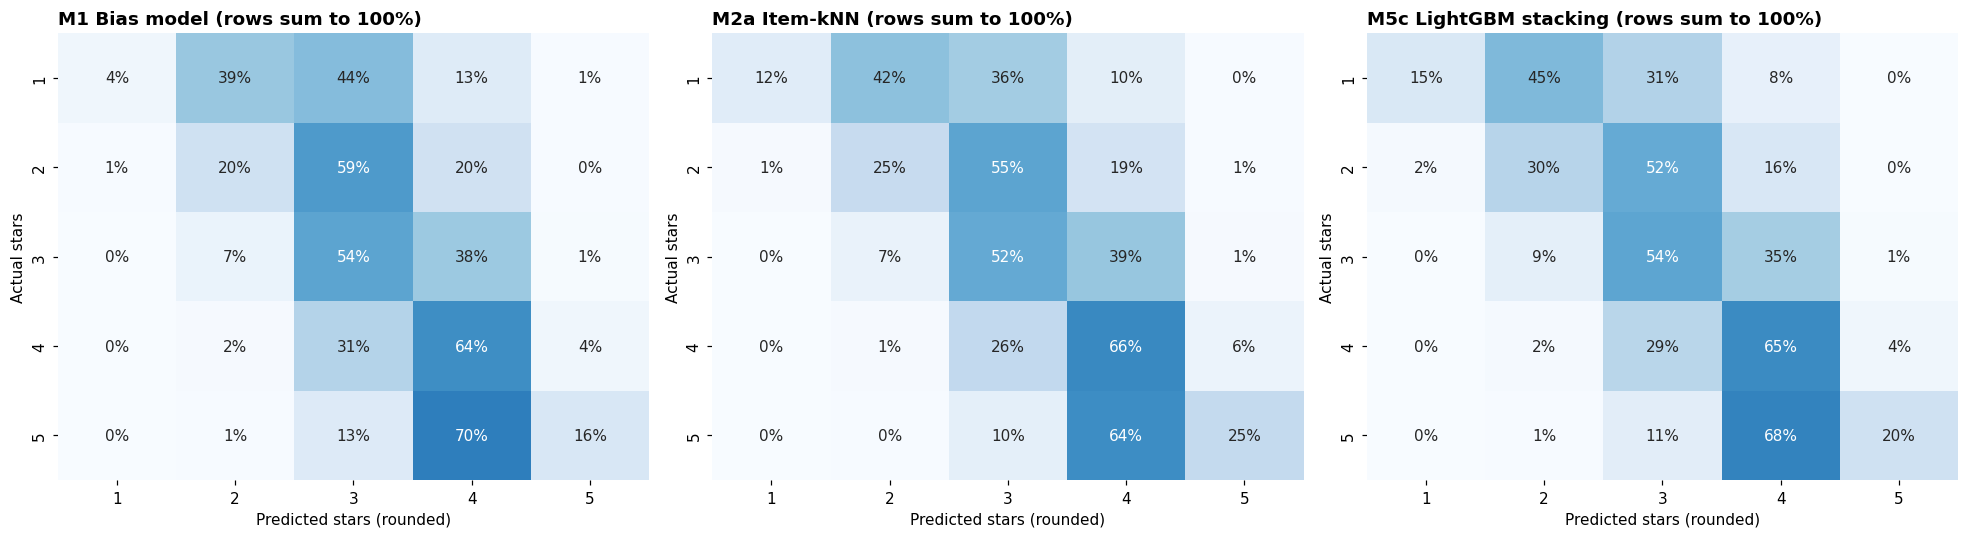

,Exact star accuracy,Within ±1 star,Off by ≥ 2 stars,Liked (≥4): AUC,Liked (≥4): precision@3.5,Liked (≥4): recall@3.5
M1 Bias model,0.427021,0.900248,0.099752,0.792,0.727976,0.741608
M2a Item-kNN,0.456129,0.915022,0.084978,0.818,0.737865,0.782569
M5c LightGBM stacking,0.458868,0.921046,0.078954,0.825,0.756598,0.758899


,Actual,M1 Bias model,M2a Item-kNN,M5c LightGBM stacking
1,6.9%,0.4%,1.1%,1.4%
2,12.8%,7.8%,8.7%,10.4%
3,28.0%,38.6%,34.8%,35.8%
4,34.0%,48.6%,48.2%,47.1%
5,18.3%,4.7%,7.2%,5.4%


In [35]:
# ==============================
# 7.6.7 Rating prediction as classification (bins of width 1)
# ==============================
from sklearn.metrics import confusion_matrix, roc_auc_score

y_true = test["rating"].values
models_cls = {
    "M1 Bias model": preds_test["M1 Bias model (regularized)"],
    "M2a Item-kNN": preds_test[[k for k in preds_test if k.startswith("M2a")][0]],
    "M5c LightGBM stacking": preds_test["M5c LightGBM — all features (stacking)"],
}

summary_cls = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, p) in zip(axes, models_cls.items()):
    p = np.clip(p, 1, 5)
    y_bin = np.clip(np.rint(p), 1, 5).astype(int)              # bins of width 1 around each star
    cm = confusion_matrix(y_true, y_bin, labels=[1, 2, 3, 4, 5], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False,
                xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
    ax.set(title=f"{name} (rows sum to 100%)", xlabel="Predicted stars (rounded)", ylabel="Actual stars")

    liked = y_true >= 4
    summary_cls[name] = {
        "Exact star accuracy": (y_bin == y_true).mean(),
        "Within ±1 star": (np.abs(y_bin - y_true) <= 1).mean(),
        "Off by ≥ 2 stars": (np.abs(y_bin - y_true) >= 2).mean(),
        "Liked (≥4): AUC": roc_auc_score(liked, p),
        "Liked (≥4): precision@3.5": liked[p >= 3.5].mean(),
        "Liked (≥4): recall@3.5": (p[liked] >= 3.5).mean(),
    }
plt.tight_layout()
plt.show()

display(pd.DataFrame(summary_cls).T.style.format("{:.1%}").format({"Liked (≥4): AUC": "{:.3f}"}))

# How "compressed" are the predictions? Distribution of rounded predictions vs. actual ratings
dist_cmp = pd.DataFrame({"Actual": pd.Series(y_true).value_counts(normalize=True).sort_index()})
for name, p in models_cls.items():
    dist_cmp[name] = pd.Series(np.clip(np.rint(np.clip(p, 1, 5)), 1, 5).astype(int)).value_counts(normalize=True)
display(dist_cmp.fillna(0).style.format("{:.1%}"))

### 7.6 M5 — Results

**Setup:** 41 features; LightGBM trained on 80,127 validation ratings (early stopping on 20% of validation users). The level-1 check reproduces M2a exactly on test (RMSE 0.8748), confirming that features are built consistently.

**Rating prediction (test)**
| Model | RMSE | MAE | vs. M1 (RMSE) | vs. M2a (RMSE) |
|---|---|---|---|---|
| M1 Bias model | 0.9211 | 0.7234 | — | +5.3% |
| M2a Item-kNN (best unsupervised) | 0.8748 | 0.6812 | −5.0% | — |
| M5a Linear blend (Ridge) | 0.8623 | 0.6745 | −6.4% | −1.4% |
| M5b LightGBM — content + biases (no CF) | 0.9021 | 0.7115 | −2.1% | +3.1% |
| **M5c LightGBM — all features (stacking)** | **0.8574** | **0.6727** | **−6.9%** | **−2.0%** |

**1. Content and demographics alone are not enough**
- The content model (M5b: biases + genres, year, popularity, demographics, user × genre affinity) improves over the bias model by **2.1%**, but is clearly **worse than item-kNN** (0.902 vs. 0.875).
- → Explicit attributes capture only part of taste; **collaborative signals** (what similar users and similar movies show) carry most of the information.

**2. Combining models beats any single model**
- Even a **linear blend** of the level-1 predictions improves over the best single model (−1.4% vs. item-kNN).
- Ridge weights: bias −1.17, kNN +0.58, ALS **+0.82**, SVD +0.35. Since every prediction already includes the bias model, the blend effectively **sums the residual corrections** of kNN, ALS and SVD: the models capture **complementary** taste signals (neighborhoods vs. latent factors).
- **The full LightGBM (M5c) is the best rating model of the project:** RMSE **0.857**, −6.9% vs. biases and −2.0% vs. item-kNN. It learns non-linear combinations, e.g., when to trust each model depending on the user's activity or the movie's popularity.
- The early-stopping RMSE (0.845) is lower than the test RMSE (0.857): test ratings are each user's latest and hardest ratings (section 5.4), and level-1 models on the test side were fitted on more data than on the training side.

**3. What the model relies on (share of gain)**
| Feature group | Share of gain |
|---|---|
| **Collaborative predictions** (kNN, ALS, SVD, clusters, PureSVD) | **91.5%** |
| User profile & demographics | 4.7% |
| User × genre affinity | 1.6% |
| Movie (popularity, year, genres) | 1.2% |
| Biases | 0.9% |

- **pred_knn** alone accounts for \~2/3 of the gain, followed by **pred_als** (\~16%) and pred_svd.
- Content features add little **on top of** collaborative predictions, which already encode genre preferences implicitly (section 5.5).
- *Occupation* ranks 5th; gain importance tends to **overstate** high-cardinality categorical features, so this should not be read as a strong demographic effect (section 5.2).

**4. The improvement is broad across segments**
| Segment | M1 Bias | M2a Item-kNN | M5c LightGBM | M5c vs. M1 |
|---|---|---|---|---|
| Users with 16–40 training ratings | 0.979 | 0.956 | 0.940 | −4.0% |
| Users with 400+ training ratings | 0.912 | 0.859 | **0.832** | **−8.8%** |
| Women | 0.948 | 0.906 | 0.886 | −6.6% |
| Men | 0.912 | 0.864 | 0.848 | −7.0% |
| Under 18 | 1.085 | 1.007 | 0.975 | **−10.2%** |
| 56+ | 0.875 | 0.844 | 0.832 | −4.9% |

- **Activity:** the more history a user has, the larger the gain (−4.0% → −8.8%): collaborative signals need data. **Light users remain the hardest** (RMSE 0.94).
- **Gender:** similar relative improvement (−6.6% vs. −7.0%), but **women's ratings remain harder to predict** (0.886 vs. 0.848) in every model. With 72% male users (section 4), the collaborative signal is weaker for women's tastes → a **fairness gap** worth monitoring.
- **Age:** the youngest users are the hardest to predict but benefit the most (−10.2%); older users are the easiest (more consistent ratings).

**5. Rating prediction as classification (predictions rounded to the nearest star)**

To make the errors easier to interpret, predictions are rounded to whole stars (bins of width 1) and compared with the actual star in a **5 × 5 confusion matrix**.

| Model | Exact star | Within ±1 star | Off by ≥ 2 stars | "Liked" (≥ 4): AUC | Precision @ 3.5 | Recall @ 3.5 |
|---|---|---|---|---|---|---|
| M1 Bias model | 42.7% | 90.0% | 10.0% | 0.792 | 72.8% | 74.2% |
| M2a Item-kNN | 45.6% | 91.5% | 8.5% | 0.818 | 73.8% | **78.3%** |
| **M5c LightGBM stacking** | **45.9%** | **92.1%** | **7.9%** | **0.825** | **75.7%** | 75.9% |

- **Most errors are small:** the best model predicts the **exact star 46%** of the time and is within **±1 star 92%** of the time. Only **7.9%** of predictions miss by 2 stars or more (vs. 10.0% for the bias model).
- **"Will they like it?" as a binary decision:** M5c separates liked (≥ 4) from not-liked movies with **AUC 0.825**. With a threshold of 3.5 predicted stars, **3 in 4** movies predicted as "liked" are actually rated 4–5 stars.

**Predictions are compressed toward the middle of the scale**
| Stars | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Actual distribution | 6.9% | 12.8% | 28.0% | 34.0% | 18.3% |
| M5c predictions (rounded) | **1.4%** | 10.4% | 35.8% | **47.1%** | **5.4%** |

- The models predict 3 or 4 stars for **83%** of ratings (vs. 62% in reality), and rarely predict the extremes: **1 star in 1.4%** of cases (vs. 6.9%) and **5 stars in 5.4%** (vs. 18.3%).
- In the confusion matrix (M5c): only **15%** of actual 1-star ratings and **20%** of actual 5-star ratings are predicted correctly; most actual 5s are predicted as **4 (68%)** and most actual 1s as **2–3 (76%)**. Middle ratings (3–4) are predicted correctly **54–65%** of the time.
- **Why:** models trained to minimize squared error **hedge toward the average** when they are uncertain; strong opinions (love it / hate it) are hard to anticipate from past ratings.
- **Ranking is not affected by this compression** (it depends on the order of predictions, not their scale), but displayed predicted ratings would look "conservative" to users. If exact stars matter (e.g., a *"We think you'll rate it 4.5★"* badge), thresholds can be **re-calibrated** on validation or an **ordinal classification** model can be used.

**Conclusions**
- **Best rating model: M5c LightGBM stacking** (RMSE 0.857, MAE 0.673, exact star 46%, within ±1 star 92%) — a **supervised** model on top of **unsupervised** representations. Unsupervised models discover taste; the supervised model learns how to combine them.
- Supervised learning with only explicit attributes (M5b) is **not competitive**: interaction data is the key ingredient.
- Gains are consistent across activity, gender and age groups, but **light users and women** remain harder to predict.
- All models **compress predictions toward 3–4 stars** and rarely predict extreme ratings: useful for deciding *what* users will like, less reliable for predicting *how strongly* they will love or hate a movie.

### 7.7 M6 — Two-Stage Recommender (Unsupervised Candidates + Supervised Re-Ranking)

Previous results showed that offline top-K mostly rewards **"will they watch it?"** (co-watching, PureSVD), while ranking by predicted rating alone (**"will they like it?"**) fails. A two-stage recommender combines both:

1. **Candidate generation (unsupervised):** for each user, the **100 unseen movies** with the highest **hybrid watch score** = average of the per-user z-scores of item-kNN co-watching (M2b) and PureSVD (M3c).
2. **Re-ranking (supervised):** a **LightGBM LambdaRank** model (learning-to-rank, optimizes NDCG directly) re-orders the 100 candidates using watch signals **and** rating signals.

**Leakage-free training**
- **Training data:** candidates generated from the **tuning train set**; label = 1 if the movie appears in the user's **validation** ratings with **≥ 4 stars**. 20% of users are held out for early stopping.
- **Test:** candidates generated from the **full training set**, evaluated against **test** ratings ≥ 4 (same protocol as all previous models).

**Features:** the 41 rating features of M5 (biases; kNN, ALS, SVD and cluster rating predictions; user × genre affinity; user profile and demographics; movie popularity, year and genres) + candidate features (co-watching z-score, PureSVD z-score, hybrid score, candidate rank).

**Variants**
| Model | Ranking |
|---|---|
| **M6a — Hybrid watch score** | Top 10 candidates by hybrid score (unsupervised, no re-ranking) |
| **M6b — LTR, watch features only** | LambdaRank with watch/popularity features |
| **M6c — LTR, all features** | LambdaRank with watch **and** rating/taste features |

**Additional metrics:** **candidate recall@100** (share of relevant test movies included in the 100 candidates; the ceiling for any re-ranker), and the **average predicted rating** (M5c) and **average actual rating of hits** of the recommended movies, to check whether re-ranking recommends movies users like more.

In [36]:
# ==============================
# 7.7.1 Candidate generation helpers
# ==============================
import gc
N_CAND = 100

def zscore_unseen(scores, seen_csr):
    """Per-user z-score over unseen movies; already rated movies get −inf."""
    s = np.array(scores, dtype=np.float32)
    r, c = seen_csr.nonzero()
    s[r, c] = np.nan
    z = (s - np.nanmean(s, axis=1, keepdims=True)) / (np.nanstd(s, axis=1, keepdims=True) + 1e-9)
    z[r, c] = -np.inf
    return z

def generate_candidates(cowatch, puresvd, seen_csr, n=N_CAND):
    zc, zp = zscore_unseen(cowatch, seen_csr), zscore_unseen(puresvd, seen_csr)
    hyb = (zc + zp) / 2
    top = np.argpartition(-hyb, n, axis=1)[:, :n]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(hyb, top, axis=1), axis=1), axis=1)
    rows, cols = np.repeat(np.arange(len(users_idx)), n), top.ravel()
    cand = pd.DataFrame({
        "user_id": users_idx[rows], "movie_id": items_idx[cols],
        "cowatch_z": zc[rows, cols], "puresvd_z": zp[rows, cols], "hybrid_z": hyb[rows, cols],
        "cand_rank": np.tile(np.arange(1, n + 1), len(users_idx)),
    })
    return cand, hyb

def candidate_recall(cand, rel):
    cs = cand.groupby("user_id")["movie_id"].apply(set)
    return np.mean([len(r & cs.get(u, set())) / len(r) for u, r in rel.items()])

# ==============================
# 7.7.2 Final candidates (full training set) and M6a
# ==============================
t0 = time.time()
S_res_f, S_bin_f, _, _ = item_similarities(train_full, m1, BETA)
cand_f, hyb_f = generate_candidates(np.asarray(B_f @ S_bin_f), (U_b * s_b) @ Vt_b, B_f)
del S_bin_f; gc.collect()

recs_m6a = topk_from_scores(hyb_f)
eval_topk(recs_m6a, "M6a Hybrid watch score (M2b + M3c)")
del hyb_f; gc.collect()

print(f"Candidates: {len(cand_f):,} ({N_CAND} per user) — {(time.time() - t0) / 60:.1f} min")
print(f"Candidate recall@{N_CAND} on test (ceiling for re-ranking): {candidate_recall(cand_f, relevant):.1%}")

Candidates: 604,000 (100 per user) — 0.1 min
Candidate recall@100 on test (ceiling for re-ranking): 41.6%


In [37]:
# ==============================
# 7.7.3 Training data for re-ranking: candidates from the tuning train set, labels from validation
# ==============================
t0 = time.time()
S_res_t, S_bin_t, _, _ = item_similarities(train, m1_tune, BETA)
cand_t, _ = generate_candidates(np.asarray(B_t @ S_bin_t), (U_pt * s_pt) @ Vt_pt, B_t)
del S_bin_t; gc.collect()

L_tune = {
    "base": m1_tune, "S_res": S_res_t, "P_als": P_als_t, "Q_als": Q_als_t,
    "P_svd": U_st * s_st, "Q_svd": Vt_st.T, "P_ps": U_pt * s_pt, "Q_ps": Vt_pt.T,
    "lab_rec": labels_t[K_REC], "E": E_t, "B": B_t, "affinity": genre_affinity(train, m1_tune),
}
X_ct = build_features(train, cand_t[["user_id", "movie_id"]], L_tune)
CAND_FEATS = ["cowatch_z", "puresvd_z", "hybrid_z", "cand_rank"]
for c in CAND_FEATS:
    X_ct[c] = cand_t[c].values
y_ct = np.array([m in rel_valid.get(u, ()) for u, m in zip(cand_t["user_id"], cand_t["movie_id"])], dtype=int)
del L_tune, S_res_t; gc.collect()

print(f"Training candidates: {len(X_ct):,} × {X_ct.shape[1]} features — {(time.time() - t0) / 60:.1f} min")
print(f"Positive rate (relevant in validation): {y_ct.mean():.2%}")
print(f"Candidate recall@{N_CAND} on validation: {candidate_recall(cand_t, rel_valid):.1%}")

Training candidates: 604,000 × 45 features — 0.2 min
Positive rate (relevant in validation): 2.49%
Candidate recall@100 on validation: 47.7%


In [38]:
# ==============================
# 7.7.4 Test-side features (full training set)
# ==============================
t0 = time.time()
L_final = {
    "base": m1, "S_res": S_res_f, "P_als": P_als, "Q_als": Q_als,
    "P_svd": U_f * s_f, "Q_svd": Vt_f.T, "P_ps": U_b * s_b, "Q_ps": Vt_b.T,
    "lab_rec": km_rec.labels_, "E": E_f, "B": B_f, "affinity": genre_affinity(train_full, m1),
}
X_cf = build_features(train_full, cand_f[["user_id", "movie_id"]], L_final)
for c in CAND_FEATS:
    X_cf[c] = cand_f[c].values
del L_final, S_res_f; gc.collect()
print(f"Test candidates: {len(X_cf):,} × {X_cf.shape[1]} features — {(time.time() - t0) / 60:.1f} min")

# ==============================
# 7.7.5 Learning-to-rank (LightGBM LambdaRank)
# ==============================
es_u = rng.choice(users_idx, size=int(0.2 * len(users_idx)), replace=False)
is_es_c = np.isin(cand_t["user_id"].values, es_u)          # candidates are contiguous per user

params_ltr = {"objective": "lambdarank", "metric": "ndcg", "eval_at": [10], "learning_rate": 0.05,
              "num_leaves": 31, "min_data_in_leaf": 200, "feature_fraction": 0.8, "bagging_fraction": 0.8,
              "bagging_freq": 1, "lambda_l2": 1.0, "verbose": -1, "seed": SEED}

def train_ltr(feats, name):
    cats = [c for c in CAT_FEATS if c in feats]
    dtr = lgb.Dataset(X_ct.loc[~is_es_c, feats], y_ct[~is_es_c], categorical_feature=cats,
                      group=[N_CAND] * int((~is_es_c).sum() // N_CAND))
    dva = lgb.Dataset(X_ct.loc[is_es_c, feats], y_ct[is_es_c], categorical_feature=cats, reference=dtr,
                      group=[N_CAND] * int(is_es_c.sum() // N_CAND))
    m = lgb.train(params_ltr, dtr, num_boost_round=2000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    print(f"{name}: best iteration {m.best_iteration}, early-stopping NDCG@10 {m.best_score['valid_0']['ndcg@10']:.4f}")
    return m

def rerank(model, feats, name):
    s = model.predict(X_cf[feats], num_iteration=model.best_iteration)
    d = cand_f[["user_id", "movie_id"]].assign(s=s).sort_values(["user_id", "s"], ascending=[True, False])
    recs = d.groupby("user_id")["movie_id"].apply(lambda x: x.values[:K]).to_dict()
    eval_topk(recs, name)
    return recs

WATCH_FEATS = CAND_FEATS + ["watch_score", "m_n_log", "m_mean", "m_year", "u_n_log"]
LTR_FEATS = X_ct.columns.tolist()

ltr_watch = train_ltr(WATCH_FEATS, "M6b LTR — watch features")
recs_m6b = rerank(ltr_watch, WATCH_FEATS, "M6b LTR — watch features")
ltr_full = train_ltr(LTR_FEATS, "M6c LTR — all features")
recs_m6c = rerank(ltr_full, LTR_FEATS, "M6c LTR — all features")

show_results()

Test candidates: 604,000 × 45 features — 0.1 min
M6b LTR — watch features: best iteration 129, early-stopping NDCG@10 0.2906
M6c LTR — all features: best iteration 230, early-stopping NDCG@10 0.3142
Rating prediction (test):


,RMSE,MAE
model,,
M0 Global mean,1.1469,0.9440
M1 Bias model (no regularization),0.9210,0.7225
M1 Bias model (regularized),0.9211,0.7234
"M2a Item-kNN (k = 20, β = 25)",0.8748,0.6812
M3a Truncated SVD on residuals (k = 20),0.9030,0.7076
"M3b Biased MF — ALS (k = 50, λ = 0.1)",0.8852,0.6917
"M4a User clusters (K = 100, β = 50)",0.9191,0.7217
M5a Linear blend (Ridge),0.8623,0.6745
M5b LightGBM — content + biases (no CF),0.9021,0.7115


Top-10 recommendation (test):


,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage,Avg. popularity,Long-tail share
M0a Most rated,0.0795,0.0471,0.0904,38.9%,3.2%,"2,323",0.0%
M0b Best rated (Bayesian),0.0499,0.0277,0.0560,27.6%,2.4%,"1,369",0.1%
M1 Bias model (regularized),0.0293,0.0163,0.0272,19.1%,1.5%,869,21.4%
M2b Item-kNN co-watching,0.0930,0.0769,0.1133,49.9%,13.4%,"1,742",0.4%
M2c Item-kNN predicted rating,0.0358,0.0206,0.0394,22.0%,4.7%,830,23.4%
M3d ALS predicted rating,0.0320,0.0192,0.0341,20.1%,16.3%,673,43.9%
M3c PureSVD implicit (k = 50),0.0841,0.0808,0.1040,48.3%,28.6%,"1,242",2.0%
M4a User clusters (K = 100),0.0819,0.0706,0.0998,43.0%,26.0%,"1,322",3.1%
M4b Taste segments (K = 8),0.0764,0.0589,0.0916,40.5%,10.6%,"1,678",0.0%
M6a Hybrid watch score (M2b + M3c),0.0868,0.0833,0.1072,49.7%,25.6%,"1,310",1.3%


In [39]:
# ==============================
# 7.7.6 Do the recommended movies match what users like?
# ==============================
cand_f["pred_rating_m5c"] = np.clip(lgb_full.predict(X_cf[ALL_FEATS], num_iteration=lgb_full.best_iteration), 1, 5)
pr = cand_f.set_index(["user_id", "movie_id"])["pred_rating_m5c"]
test_r = test.set_index(["user_id", "movie_id"])["rating"]

def rec_quality(recs):
    pairs = pd.MultiIndex.from_tuples([(u, m) for u in users_idx for m in recs[u][:K]])
    hits = test_r.reindex(pairs).dropna()
    return pd.Series({"avg_predicted_rating (M5c)": pr.reindex(pairs).mean(),
                      "avg_actual_rating_of_watched": hits.mean(),
                      "share_of_watched_rated_≥4": (hits >= 4).mean()})

quality = pd.DataFrame({name: rec_quality(r) for name, r in
                        [("M2b Item-kNN co-watching", recs_m2b), ("M3c PureSVD", recs_m3c),
                         ("M6a Hybrid", recs_m6a), ("M6b LTR watch", recs_m6b), ("M6c LTR all", recs_m6c)]}).T
print("Quality of recommended movies (watched = recommended movies that appear in the user's test ratings):")
display(quality.style.format({"avg_predicted_rating (M5c)": "{:.2f}", "avg_actual_rating_of_watched": "{:.2f}",
                              "share_of_watched_rated_≥4": "{:.1%}"}))

# ==============================
# 7.7.7 Feature importance of the full re-ranker
# ==============================
imp6 = pd.Series(ltr_full.feature_importance("gain"), index=LTR_FEATS)
imp6 = imp6 / imp6.sum()
groups6 = pd.Series({
    "Watch signals (co-watching, PureSVD, rank)": imp6[CAND_FEATS + ["watch_score"]].sum(),
    "Rating predictions (kNN, ALS, SVD, clusters, biases)": imp6[[f for f in COLLAB_FEATS if f != "watch_score"]
                                                                 + ["pred_bias", "b_u", "b_i"]].sum(),
    "Movie (popularity, year, genres)": imp6[["m_n_log", "m_mean", "m_year"] + [f"g_{g}" for g in GENRES]].sum(),
    "User profile & demographics": imp6[["u_n_log", "u_mean", "u_std", "gender_f", "age", "occupation"]].sum(),
    "User × genre affinity": imp6[["genre_affinity_mean", "genre_affinity_max"]].sum(),
}, name="share_of_gain").sort_values(ascending=False)
display(groups6.to_frame().style.format("{:.1%}"))
print("Top 10 features:", imp6.sort_values(ascending=False).head(10).round(3).to_dict())

# ==============================
# 7.7.8 Example (user 1)
# ==============================
u = users_idx[0]
for name, r in [("M2b Item-kNN", recs_m2b), ("M6a Hybrid", recs_m6a), ("M6c LTR all", recs_m6c)]:
    print(f"{name:<14}", title_of.loc[r[u][:6]].tolist())

Quality of recommended movies (watched = recommended movies that appear in the user's test ratings):


,avg_predicted_rating (M5c),avg_actual_rating_of_watched,share_of_watched_rated_≥4
M2b Item-kNN co-watching,3.94,3.92,70.1%
M3c PureSVD,3.87,3.90,69.5%
M6a Hybrid,3.88,3.90,69.1%
M6b LTR watch,3.90,3.94,71.0%
M6c LTR all,4.08,4.09,77.7%


,share_of_gain
"Rating predictions (kNN, ALS, SVD, clusters, biases)",35.7%
"Watch signals (co-watching, PureSVD, rank)",22.5%
User profile & demographics,21.6%
"Movie (popularity, year, genres)",12.9%
User × genre affinity,7.3%


Top 10 features: {'occupation': 0.104, 'cowatch_z': 0.068, 'watch_score': 0.064, 'als_minus_bias': 0.052, 'm_n_log': 0.048, 'knn_minus_bias': 0.048, 'svd_minus_bias': 0.044, 'hybrid_z': 0.042, 'u_n_log': 0.04, 'genre_affinity_max': 0.04}
M2b Item-kNN   ['Star Wars: Episode V - The Empire Strikes Back (1980)', 'Raiders of the Lost Ark (1981)', 'Groundhog Day (1993)', 'Shawshank Redemption, The (1994)', 'Pulp Fiction (1994)', 'Toy Story (1995)']
M6a Hybrid     ['Shawshank Redemption, The (1994)', 'Raiders of the Lost Ark (1981)', 'Star Wars: Episode V - The Empire Strikes Back (1980)', 'Amadeus (1984)', 'Silence of the Lambs, The (1991)', 'Toy Story (1995)']
M6c LTR all    ['West Side Story (1961)', 'Lady and the Tramp (1955)', 'Lion King, The (1994)', 'Beauty and the Beast (1991)', 'Jungle Book, The (1967)', 'Little Mermaid, The (1989)']


### 7.7 M6 — Results

**Candidate generation**
- **100 candidates per user** (604,000 pairs) from the hybrid watch score (item-kNN co-watching + PureSVD).
- **Candidate recall@100 = 41.6% on test** (47.7% on validation): 4 in 10 relevant test movies are among each user's 100 candidates. This is the **ceiling** for any re-ranker; the remaining relevant movies would need a broader candidate set.
- Training data for re-ranking: 604,000 candidates with a **positive rate of 2.49%**.

**Top-10 recommendation (test)**
| Model | Precision@10 | Recall@10 | NDCG@10 | Hit Rate@10 | Coverage | Avg. popularity | Long-tail share |
|---|---|---|---|---|---|---|---|
| M0a Most rated | 0.0795 | 0.0471 | 0.0904 | 38.9% | 3.2% | 2,323 | 0.0% |
| M2b Item-kNN co-watching | 0.0930 | 0.0769 | 0.1133 | 49.9% | 13.4% | 1,742 | 0.4% |
| M3c PureSVD implicit | 0.0841 | 0.0808 | 0.1040 | 48.3% | 28.6% | 1,242 | 2.0% |
| M6a Hybrid watch score (unsupervised) | 0.0868 | 0.0833 | 0.1072 | 49.7% | 25.6% | 1,310 | 1.3% |
| M6b LTR — watch features | 0.0984 | 0.0906 | 0.1236 | 54.4% | 32.2% | 1,364 | 4.0% |
| **M6c LTR — all features** | **0.1158** | **0.1029** | **0.1423** | **59.7%** | **33.0%** | 1,262 | 3.5% |

*(The early-stopping NDCG@10 of the re-rankers, 0.29–0.31, is computed only among the 100 candidates on validation labels, so it is not comparable with the test metrics above.)*

**1. The two-stage recommender is the best ranking model of the project**
- **M6c** improves NDCG@10 by **+26% vs. item-kNN** (0.113 → 0.142) and **+57% vs. popularity**, with the best precision, recall and hit rate: **6 in 10 users** get at least one relevant movie in their top 10.
- Precision@10 reaches **\~15% of the theoretical ceiling** (0.116 / 0.773), up from \~10% for popularity.
- It is also among the **most diverse** models: **coverage 33.0%** (10× popularity, 2.5× item-kNN).

**2. Where the gain comes from**
| Step | NDCG@10 | Gain |
|---|---|---|
| Simple average of watch signals (M6a) | 0.107 | — |
| + supervised re-ranking with **watch** features (M6b) | 0.124 | +15% |
| + **rating / taste** features (M6c) | **0.142** | **+15%** |

- A simple average of the two unsupervised watch scores (M6a) **does not beat** item-kNN alone in accuracy, but it doubles coverage.
- **Learning how to combine** watch signals (M6b) adds +15%.
- Adding **"will they like it?"** features (predicted ratings, genre affinity, user profile) adds **another +15%**. Rating predictions failed as a ranking criterion **on their own** (M1, M2c, M3d), but they are valuable **on top of** watch signals.

**3. Recommended movies are also better liked**
| Model | Avg. predicted rating (M5c) | Avg. actual rating of watched recommendations | Share of watched recommendations rated ≥ 4 |
|---|---|---|---|
| M2b Item-kNN co-watching | 3.94 | 3.92 | 70.1% |
| M3c PureSVD | 3.87 | 3.90 | 69.5% |
| M6b LTR — watch | 3.89 | 3.92 | 70.3% |
| **M6c LTR — all** | **4.08** | **4.10** | **77.8%** |

- When users watch a movie recommended by M6c, they rate it **0.18 stars higher** on average, and **78%** of them get 4–5 stars (vs. \~70% for the other models).
- → The re-ranker improves **both** *"will they watch it?"* (more hits) **and** *"will they like it?"* (better-rated hits).

**4. What the re-ranker relies on (share of gain)**
| Feature group | Share of gain |
|---|---|
| Rating predictions (kNN, ALS, SVD, clusters, biases) | 34.5% |
| Watch signals (co-watching, PureSVD, candidate rank) | 23.8% |
| User profile & demographics | 21.8% |
| Movie (popularity, year, genres) | 12.9% |
| User × genre affinity | 7.1% |

- Rating and watch signals together account for **\~58%** of the gain: the model genuinely **combines both questions**.
- *Occupation* is the single top feature (10.8%). User-level features are constant within a user's candidates, so they can only act through **interactions** (e.g., which movie types fit which users); in addition, gain importance **overstates** high-cardinality categorical features. It should not be read as a strong demographic effect.

**5. Qualitative example (user 1)**
- Liked in training: *Cinderella*, *Back to the Future*, *A Christmas Story*, *One Flew Over the Cuckoo's Nest*.
- **M2b (item-kNN):** *The Empire Strikes Back*, *Raiders of the Lost Ark*, *Groundhog Day*, *Shawshank* → popular, generic classics.
- **M6c (two-stage):** *Peter Pan*, *Toy Story*, *The Lion King*, *West Side Story*, *The Silence of the Lambs*, *The Jungle Book* → clearly aligned with the user's **family / animation / musical** taste.

**Conclusions**
- **Best ranking model: M6c two-stage recommender** — **unsupervised candidate generation** (co-watching + PureSVD) followed by **supervised learning-to-rank** (LightGBM LambdaRank).
- The key is to **combine "will they watch it?" with "will they like it?"**: neither signal alone is enough, but together they improve accuracy (+26% NDCG), diversity (33% coverage) and the quality of the recommended movies (78% liked).
- **Next improvement:** candidate recall@100 is 41.6%, so a broader or more diverse candidate set (more candidates, more generators) would raise the ceiling of the re-ranker.

## 8. Conclusions and Business Recommendations

### 8.1 Results Summary

| Model | Idea | Learning type | RMSE ↓ | NDCG@10 ↑ | Coverage | Main takeaway |
|---|---|---|---|---|---|---|
| M0 Global mean / Most rated | Same prediction / same movies for everyone | Heuristic | 1.147 | 0.090 | 3.2% | Popularity is a strong ranking baseline |
| M1 Bias model | Global mean + user bias + movie bias | Statistical baseline | 0.921 | 0.027 | 1.5% | −20% RMSE, but the **worst** ranker |
| M2 Item-item kNN | Ratings / co-watching of similar movies | **Unsupervised** | 0.875 | 0.113 | 13.4% | Best single model in both tasks |
| M3 Matrix factorization | Latent taste factors (ALS, SVD, PureSVD) | **Unsupervised** | 0.885 | 0.104 | 28.6% | Close to kNN; PureSVD is **2× more diverse** |
| M4 User clustering | Taste segments (K-means) | **Unsupervised** | 0.919 | 0.100 (K=100) / 0.092 (K=8) | 26.0% / 10.5% | Most **interpretable**: 8 named segments |
| M5 LightGBM stacking | Supervised regression on CF predictions + content | **Supervised** | **0.857** | — | — | **Best rating model** (−2.0% vs. kNN) |
| **M6 Two-stage recommender** | Unsupervised candidates + LambdaRank re-ranking | **Unsupervised + supervised** | — | **0.142** | **33.0%** | **Best recommender** (+26% vs. kNN, 78% of watched recs liked) |

*Each row reports the best variant of the model family. Ceiling of Precision@10 with perfect ranking: 0.773.*

**In practical terms:** with the final two-stage recommender, **6 in 10 users** find at least one movie they will watch and like among their top 10 recommendations, and **78%** of the recommended movies they watch are rated 4–5 stars.

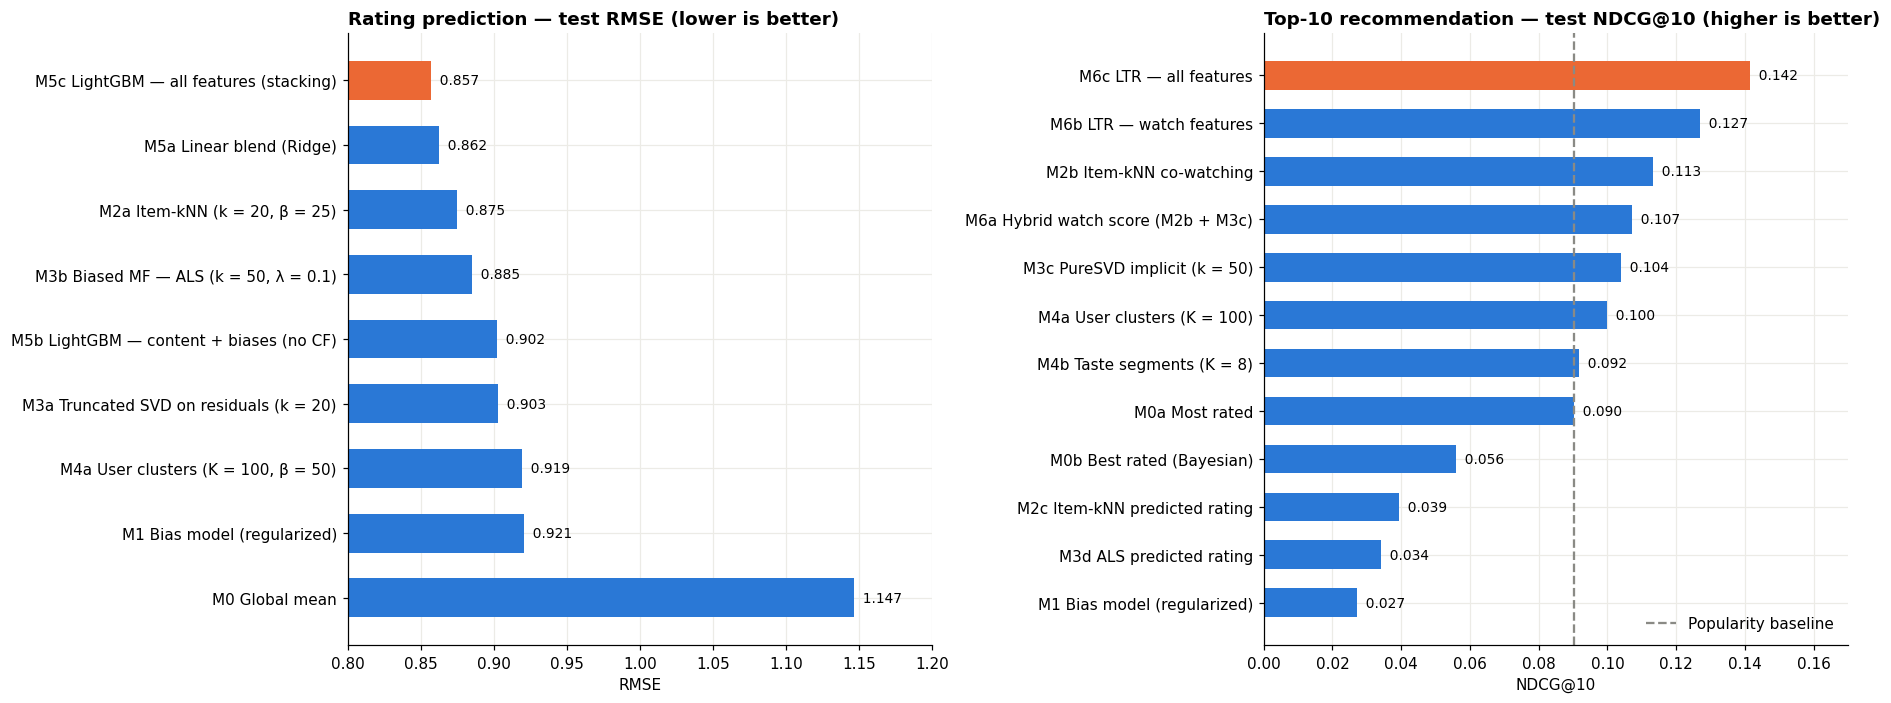

In [40]:
# ==============================
# 8.1.1 Model progression in both tasks
# ==============================
rr = pd.DataFrame(rating_results).set_index("model")["RMSE"]
rr = rr.drop(index=[m for m in rr.index if "no regularization" in m]).sort_values(ascending=False)
tk = pd.DataFrame(topk_results).T["NDCG@10"].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

axes[0].barh(rr.index, rr.values, color=[ORANGE if v == rr.min() else BLUE for v in rr.values], height=0.6)
for y, v in enumerate(rr.values):
    axes[0].text(v, y, f"  {v:.3f}", va="center", fontsize=9)
axes[0].set(title="Rating prediction — test RMSE (lower is better)", xlabel="RMSE")
axes[0].set_xlim(0.8, 1.2)

axes[1].barh(tk.index, tk.values, color=[ORANGE if v == tk.max() else BLUE for v in tk.values], height=0.6)
for y, v in enumerate(tk.values):
    axes[1].text(v, y, f"  {v:.3f}", va="center", fontsize=9)
axes[1].axvline(topk_results["M0a Most rated"]["NDCG@10"], color=GREY, ls="--", lw=1.5, label="Popularity baseline")
axes[1].set(title="Top-10 recommendation — test NDCG@10 (higher is better)", xlabel="NDCG@10")
axes[1].set_xlim(0, 0.17)
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

### 8.2 Key Learnings

1. **Predicting ratings and recommending movies are different problems.** The bias model reduces RMSE by 20% but is the worst ranker; ranking by predicted rating failed three times (M1, M2c, M3d). Offline top-K rewards *"will they watch it?"*, while RMSE rewards *"how much will they like it?"* on movies users **already chose** to watch.
2. **The best recommender combines both questions.** Unsupervised watch signals (co-watching, PureSVD) generate candidates, and a supervised re-ranker adds rating and taste signals: **+26% NDCG** over the best single model, with better-liked recommendations (78% rated 4–5 stars).
3. **Interaction data beats explicit attributes.** A supervised model with genres, year and demographics only (M5b) is clearly worse than item-kNN; 91.5% of the stacking model's gain comes from collaborative predictions. Demographics explain 0.05–0.37 stars of variation vs. 1.07 across individual users.
4. **Unsupervised models discover real taste structure.** From ratings alone, item similarities recover franchises and directors (*Star Wars IV → V*, *Pulp Fiction → Reservoir Dogs*), latent factors separate mainstream from auteur cinema, and clustering finds interpretable segments (classic cinema lovers, sci-fi fans, rom-com & family…).
5. **Supervised learning adds value on top of unsupervised representations.** Stacking (M5c) and learning-to-rank (M6c) are the best models in each task: unsupervised models learn *representations of taste*; supervised models learn *how to use them*.
6. **Simple, well-tuned neighborhood models are hard to beat.** Item-kNN was the best single model in both tasks, ahead of matrix factorization (partly under-tuned).
7. **Accuracy and diversity can improve together.** The final recommender covers **33%** of the catalog (10× popularity) while being the most accurate.
8. **Quality is not equal for everyone.** Light users, young users and **women** (28% of users) are harder to predict in every model: a fairness gap to monitor.

### 8.3 Hypotheses Tested

| # | Hypothesis | Where | Result |
|---|---|---|---|
| H1 | User and movie biases explain a large part of ratings | EDA 5.1, M1 | ✅ **Confirmed:** −20% RMSE vs. global mean (\~32% of variance in the EDA) |
| H2 | Ratings contain collaborative taste structure | EDA 5.5, M2, M3 | ✅ **Confirmed:** item-kNN −5% RMSE vs. biases; similarities recover franchises and directors |
| H3 | Demographics are a weak signal for taste | EDA 5.2, M5b | ✅ **Confirmed:** content + demographics model is worse than item-kNN (0.902 vs. 0.875) |
| H4 | The best rating model is also the best recommender | M1, M2c, M3d | ❌ **Rejected:** ranking by predicted rating is consistently the worst personalized ranker |
| H5 | Matrix factorization beats neighborhood models | M3 | ⚠️ **Not confirmed here:** ALS 0.885 vs. kNN 0.875 (ALS likely under-tuned); PureSVD close to kNN in ranking but **2× more diverse** |
| H6 | Users form distinct taste segments | M4 | ⚠️ **Partially confirmed:** 8 interpretable segments, but low silhouette (≤ 0.11): tastes are a **continuum** |
| H7 | A supervised combination beats any single model | M5 | ✅ **Confirmed:** stacking RMSE 0.857 (−2.0% vs. kNN), improving every user segment |
| H8 | Combining *"will they watch it?"* and *"will they like it?"* improves recommendations | M6 | ✅ **Confirmed:** +26% NDCG@10, and 78% of watched recommendations rated ≥ 4 (vs. \~70%) |
| H9 | Rating timestamps reflect viewing behavior over time | EDA 5.4 | ❌ **Rejected:** 72% of ratings were made in the user's first 24 hours (bulk sessions) → sequential modeling is left for a dataset with real interaction sequences |

### 8.4 Business Recommendations

| Surface | Recommendation | Model | KPI to track |
|---|---|---|---|
| **"Top picks for you"** (home row) | Use the **two-stage recommender**: broad candidate generation + learning-to-rank combining watch and taste signals | M6c | Play rate, time to first play, watch time |
| **"Because you watched X"** | Use **item-item co-watching similarity**: accurate and naturally **explainable** | M2b | Click-through rate, titles per session |
| **"Similar movies"** (title page) | Item similarities on residual ratings recover franchises, directors and styles | M2 | CTR, catalog exploration |
| **Themed rows & marketing** | Use the **8 taste segments** (e.g., *Classic cinema lovers*, *Sci-fi fans*, *Rom-com & family*) for editorial rows, campaigns and content acquisition decisions | M4b | Engagement by segment, campaign conversion |
| **Predicted rating badge** (*"We think you'll rate it 4.3★"*) | Use the **stacking model** only for displaying expected ratings, **not** for ranking | M5c | User trust, rating agreement |
| **New users (onboarding)** | Start with **popular + best-rated** movies and ask for a few favorite movies or genres; switch to collaborative models after \~20 ratings | M0 / M2 | Activation, early retention |
| **Catalog exposure** | Monitor **coverage and long-tail share**; favor diverse candidate generators (PureSVD) to avoid recommending only blockbusters | M3c / M6 | Share of views outside the top 20% titles |
| **Fairness monitoring** | Track quality for **women, young and light users**, who are consistently harder to predict | All | Quality metrics by segment |

**Validation:** these results come from an **offline** evaluation on past ratings. Before rollout, each surface should be validated with **A/B tests** on business KPIs (play rate, watch time, retention).

### 8.5 Limitations and Next Steps

**Limitations**
- **Selection bias:** users rate movies they chose to watch, so a recommended movie the user never rated counts as a miss, even if they would have liked it. Offline top-K metrics are conservative and favor popular movies.
- **Bulk rating sessions:** most ratings were made at sign-up about movies watched in the past, so the temporal split behaves almost like a random split within each user's session.
- **Per-user temporal split:** a user's test ratings can be earlier than other users' training ratings (accepted limitation in MovieLens benchmarks).
- **Data from 2000–2003**, from a non-commercial research website (not a streaming service), with a 72/28 male/female imbalance.
- **Under-tuned models:** the best ALS configuration was at the edge of the search grid; LightGBM hyperparameters were not tuned.
- **Candidate recall@100 = 41.6%:** the re-ranker cannot recover relevant movies outside the candidate set.
- **Item cold start not evaluated:** almost all test movies were seen in training (0.03% unseen), and every user has ≥ 20 ratings.

**Next steps**
1. **Tune ALS further** (larger λ, more iterations) and try **implicit-feedback models** (implicit ALS, BPR) for candidate generation.
2. **Broaden candidate generation** (more candidates, more generators) to raise the re-ranking ceiling.
3. **Debiasing:** inverse-propensity weighting to correct for selection bias in training and evaluation.
4. **Simulated cold start:** evaluate new users with only their first 5–10 ratings, comparing collaborative, content and demographic approaches.
5. **Fairness-aware evaluation and re-ranking** for under-served groups.
6. **Sequential models** on a dataset with real interaction sequences (next project: Amazon Reviews 2023).
7. **Online A/B tests** for each surface.

In [41]:
# ==============================
# End of execution
# ==============================
end = time.time()
delta = end - start

hours, remainder = divmod(delta, 3600)
minutes, seconds = divmod(remainder, 60)
print(f"Total execution time: {int(hours)}h {int(minutes)}m {int(seconds)}s ({delta:,.0f} seconds)")

Total execution time: 0h 3m 45s (226 seconds)
